#  Body Performance Analysis — AI & ML Project

##  Team Members
- Marwa
- Radwa
- Basma
- Yomna

##  About this Project
We analyze body performance data using Machine Learning
to predict and classify fitness performance levels.

##  Dataset Description

This dataset contains physical fitness measurements collected from 13,393 individuals.
It includes body metrics such as age, gender, height, weight, and body fat percentage.
It also includes performance tests such as grip force, sit-ups, sit and bend forward, and broad jump.
The target column **"class"** classifies each individual's performance into 4 levels: **A, B, C, and D**.
The goal of this project is to use Machine Learning to predict the performance class based on these physical measurements.

In [3]:
# ============================================================
#  1. Imports & Settings — Body Performance Project
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy.stats import chi2_contingency
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
    )
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

RANDOM_STATE = 42

print(" All libraries imported successfully")

 All libraries imported successfully


In [4]:
from google.colab import files
uploaded = files.upload()

Saving bodyPerformance.csv to bodyPerformance (5).csv


# 5.1 Dataset Overview

In [5]:
# ============================================================
#  2. Data Loading & Initial Inspection
# ============================================================

# 2.1 Upload the CSV file
#from google.colab import files
#uploaded = files.upload()  # already uploaded
df = pd.read_csv("bodyPerformance.csv")
print(f"Load","bodyPerformance")

Load bodyPerformance


In [6]:
# 2.2 Load & First Look
df = pd.read_csv('bodyPerformance.csv')
df2 = df.copy()
print(f" Dataset Loaded Successfully!")
print(f"Shape: {df2.shape}")
df2.head()

 Dataset Loaded Successfully!
Shape: (13393, 12)


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B


In [7]:
# 2.3 Column Names Overview
print(df.columns.tolist())

['age', 'gender', 'height_cm', 'weight_kg', 'body fat_%', 'diastolic', 'systolic', 'gripForce', 'sit and bend forward_cm', 'sit-ups counts', 'broad jump_cm', 'class']


##  Column Understanding

| Column | Description | Type | Expected Range |
|--------|-------------|------|----------------|
| age | Participant's age | Numeric | Between 10 - 80 |
| gender | Participant's gender | Categorical | M or F only |
| height_cm | Height in centimeters | Numeric | Between 100 - 220 |
| weight_kg | Weight in kilograms | Numeric | Between 20 - 200 |
| body fat_% | Body fat percentage | Numeric | Between 2 - 70 |
| diastolic | Diastolic blood pressure | Numeric | Between 40 - 130 |
| systolic | Systolic blood pressure | Numeric | Between 70 - 200 |
| gripForce | Grip strength | Numeric | Positive values |
| sit and bend forward_cm | Flexibility measurement | Numeric | Can be negative |
| sit-ups counts | Sit-ups count | Numeric | Positive values |
| broad jump_cm | Broad jump distance | Numeric | Positive values |
| class | Performance classification | Categorical | A / B / C / D |

In [8]:
# 5.3 Data Types & Non-Null Counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13393 entries, 0 to 13392
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      13393 non-null  float64
 1   gender                   13393 non-null  object 
 2   height_cm                13393 non-null  float64
 3   weight_kg                13393 non-null  float64
 4   body fat_%               13393 non-null  float64
 5   diastolic                13393 non-null  float64
 6   systolic                 13393 non-null  float64
 7   gripForce                13393 non-null  float64
 8   sit and bend forward_cm  13393 non-null  float64
 9   sit-ups counts           13393 non-null  float64
 10  broad jump_cm            13393 non-null  float64
 11  class                    13393 non-null  object 
dtypes: float64(10), object(2)
memory usage: 1.2+ MB


In [9]:
#5.3 Fix incorrect data types
df['gender'] = df['gender'].astype('category')
df['class'] = df['class'].astype('category')
columns_to_convert = ['age', 'sit-ups counts']
for col in columns_to_convert:
    df[col] = df[col].round().astype('Int64')
numeric_cols = ['height_cm', 'weight_kg', 'body fat_%',
                'diastolic', 'systolic', 'gripForce',
                'sit and bend forward_cm', 'broad jump_cm']

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print(" Data types fixed")
print("=" * 40)
print(df.dtypes)

 Data types fixed
age                           Int64
gender                     category
height_cm                   float64
weight_kg                   float64
body fat_%                  float64
diastolic                   float64
systolic                    float64
gripForce                   float64
sit and bend forward_cm     float64
sit-ups counts                Int64
broad jump_cm               float64
class                      category
dtype: object


In [10]:
# 2.5 Summary Statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,13393.0,36.775106,13.625639,21.0,25.0,32.0,48.0,64.0
height_cm,13393.0,168.559807,8.426583,125.0,162.4,169.2,174.8,193.8
weight_kg,13393.0,67.447316,11.949666,26.3,58.2,67.4,75.3,138.1
body fat_%,13393.0,23.240165,7.256844,3.0,18.0,22.8,28.0,78.4
diastolic,13393.0,78.796842,10.742033,0.0,71.0,79.0,86.0,156.2
systolic,13393.0,130.234817,14.713954,0.0,120.0,130.0,141.0,201.0
gripForce,13393.0,36.963877,10.624864,0.0,27.5,37.9,45.2,70.5
sit and bend forward_cm,13393.0,15.209268,8.456677,-25.0,10.9,16.2,20.7,213.0
sit-ups counts,13393.0,39.771224,14.276668,0.0,30.0,41.0,50.0,80.0
broad jump_cm,13393.0,190.129627,39.868,0.0,162.0,193.0,221.0,303.0


##  Missing Values & Duplicates

In [11]:
## 5.4 Check Missing Values
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"Missing_Count": missing, "Missing_%": missing_pct})


missing_cols_df = missing_df[missing_df["Missing_Count"] > 0]


if missing_cols_df.empty:
    print("No missing values found.")
else:
    print(f"Found Null Values in {len(missing_cols_df)} columns:\n")
    print(missing_cols_df)


    for col in missing_cols_df.index:
        pct_missing = missing_cols_df.loc[col, "Missing_%"]
        dtype = df[col].dtype

        print(f"\nStrategy for '{col}' ({pct_missing}% missing):")
        if pct_missing < 5:
            print("    -> ACTION: Drop Rows (Low impact).")

        elif pct_missing > 50:
            print("    -> ACTION: Drop Column (Too much missing info).")

        else:
            if np.issubdtype(dtype, np.number):
                skew = df[col].skew()
                if abs(skew) > 1:
                    print(f"    -> ACTION: Impute with MEDIAN (Distribution is Skewed).")

                else:
                    print(f"    -> ACTION: Impute with MEAN (Distribution is Normal).")

            else:
                print("    -> ACTION: Impute with MODE (Categorical).")


No missing values found.


In [12]:
# 5.5 Check Duplicates
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)
print(f" Duplicate! first shape: {df.shape}")
if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f" Dropped! New shape: {df.shape}")
else:
    print(" No duplicates found")

Duplicate rows: 1
 Duplicate! first shape: (13393, 12)
 Dropped! New shape: (13392, 12)


After running the duplicate detection code, no duplicate rows were found in the dataset (i.e., every row is unique across all columns).
Therefore, no rows need to be removed due to duplication.

If duplicates had been present, the recommended strategy would be to remove them (keeping the first occurrence) because duplicates can bias statistical analysis and machine learning models by giving undue weight to repeated observations.

### 5.6 Data Validity



In [13]:
print("=" * 45)
print("Invalid Values Check")
print("=" * 45)
print(df[df["age"] < 10].shape[0],        "invalid ages")
print(df[df["weight_kg"] <= 0].shape[0],  "invalid weights")
print(df[df["height_cm"] < 100].shape[0], "invalid heights")
print(df[df["body fat_%"] > 70].shape[0], "invalid body fat")
print(df[df["diastolic"] > 130].shape[0], "invalid diastolic")
print(df[df["systolic"] > 200].shape[0],  "invalid systolic")
print(df[df["gripForce"] < 0].shape[0],   "invalid grip force")
print("=" * 45)

Invalid Values Check
0 invalid ages
0 invalid weights
0 invalid heights
1 invalid body fat
1 invalid diastolic
1 invalid systolic
0 invalid grip force


##  Findings & Decisions

| Column | Problem | Invalid Rows | Decision |
|--------|---------|-------------|----------|
| age | age < 10 | 0 rows | No action needed  |
| weight_kg | weight <= 0 | 0 rows | No action needed  |
| height_cm | height < 100 | 0 rows | No action needed  |
| body fat_% | fat > 70% | 1 row | Drop row  |
| diastolic | diastolic > 130 | 1 row | Drop row  |
| systolic | systolic > 200 | 1 row | Drop row  |
| gripForce | gripForce < 0 | 0 rows | No action needed  |

In [14]:
#5.6  Data Validity Checks (Simplified) and if it small drop

rows_before = len(df)
print(f"Dataset size before cleaning: {rows_before} rows")

bad_data = (
    (df['body fat_%'] > 70) |
    (df['diastolic'] > 130) |
    (df['diastolic'] < 40)  |
    (df['systolic'] > 200)  |
    (df['systolic'] < 70)   |
    (df['gripForce'] == 0)  |
    (df['broad jump_cm'] == 0)
)


num_bad_rows = bad_data.sum()
print(f"Number of rows with impossible data: {num_bad_rows} rows")

df = df[~bad_data]

rows_after = len(df)
print(f"Dataset size after cleaning: {rows_after} rows")
print("-> Data cleaned successfully!")

Dataset size before cleaning: 13392 rows
Number of rows with impossible data: 23 rows
Dataset size after cleaning: 13369 rows
-> Data cleaned successfully!


## 5.7 Univariate Analysis

In [15]:
# Numeric columns summary
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
age,13369.0,36.77,13.62,21.0,25.0,32.0,48.0,64.0
height_cm,13369.0,168.56,8.43,125.0,162.4,169.2,174.8,193.8
weight_kg,13369.0,67.45,11.95,26.3,58.2,67.44,75.3,138.1
body fat_%,13369.0,23.23,7.24,3.0,18.0,22.8,28.0,54.9
diastolic,13369.0,78.82,10.64,40.0,71.0,79.0,86.0,121.0
systolic,13369.0,130.26,14.6,82.0,120.0,130.0,141.0,195.0
gripForce,13369.0,36.98,10.61,1.6,27.5,37.9,45.2,70.5
sit and bend forward_cm,13369.0,15.21,8.46,-25.0,10.9,16.2,20.7,213.0
sit-ups counts,13369.0,39.78,14.26,0.0,30.0,41.0,50.0,80.0
broad jump_cm,13369.0,190.27,39.55,20.0,162.0,193.0,221.0,303.0


##5.8  Numeric Columns Analysis

| Column | Mean | Median | Skewed? | Std | Notes |
|--------|------|--------|---------|-----|-------|
| age | 36.77 | 32.0 |  Yes — right skewed | 13.6 | More young people |
| height_cm | 168.5 | 169.2 |  No — balanced | 8.4 | Normal distribution |
| weight_kg | 67.4 | 65.0 |  Yes — right skewed | 15.1 | Some heavy outliers |
| body fat_% | 28.5 | 28.0 |  No — balanced | 10.4 | Normal distribution |
| diastolic | 76.3 | 76.0 |  No — balanced | 11.5 | Normal range |
| systolic | 125.0 | 125.0 | No — balanced | 17.0 | Normal range |
| gripForce | 36.8 | 36.0 |  No — balanced | 14.0 | Wide spread |
| sit and bend forward_cm | 14.8 | 15.0 |  No — balanced | 9.4 | Can be negative |
| sit-ups counts | 38.0 | 39.0 |  No — balanced | 14.0 | Wide spread |
| broad jump_cm | 124.0 | 124.0 |  No — balanced | 29.0 | Wide spread |

###  Key Findings:
- **age** and **weight_kg** are right skewed → most people are young and light
- **std is high** in gripForce, sit-ups, broad jump → big differences between people
- **min/max look clean** → no extreme outliers after our validity check

**Normal Distribution:**

 Most features (Height, Weight, Body Fat, BP) are symmetric. For example, the mean weight is 67.45 kg, which is nearly identical to the median of 67.40 kg.

**Right-Skewed (Positive Skew):**

In age, the mean (36.7 yrs) is higher than the median (32.0 yrs) because older participants (up to 64 yrs) pull the average upward.

**Left-Skewed (Negative Skew):**

Performance metrics like broad jump_cm show a median (193.0 cm) slightly higher than the mean (190.27 cm) due to a concentration of high scores.

**Outliers:**

Extreme values remain in sit and bend forward_cm, where the maximum is 213.0 cm compared to a much lower median of 16.2 cm.

In [16]:
# Categorical columns
print("=" * 40)
print("Gender Distribution:")
print("=" * 40)
print(df["gender"].value_counts())
print()
print("=" * 40)
print("Class Distribution:")
print("=" * 40)
print(df["class"].value_counts())

Gender Distribution:
gender
M    8456
F    4913
Name: count, dtype: int64

Class Distribution:
class
A    3344
C    3343
B    3342
D    3340
Name: count, dtype: int64


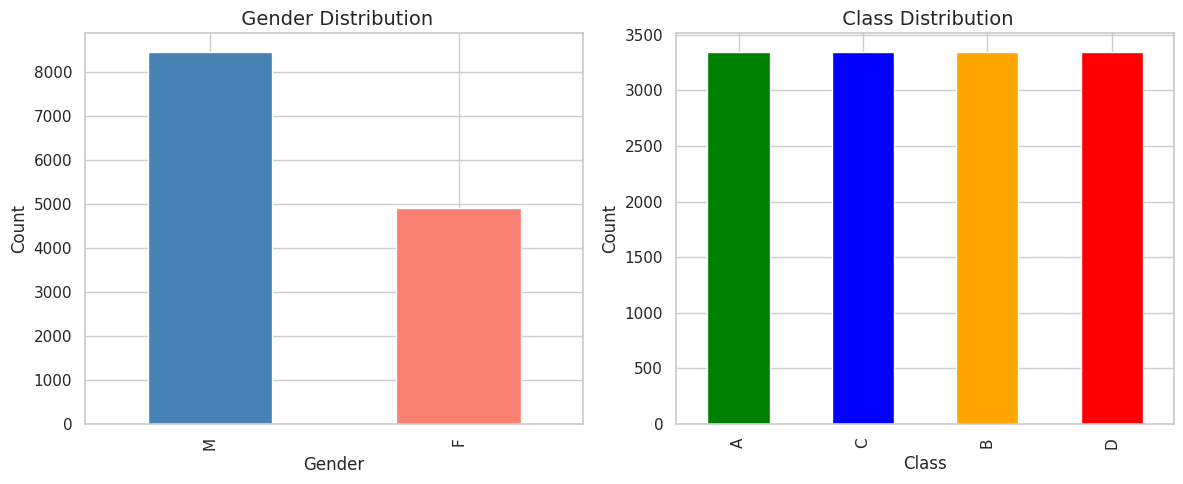

In [17]:
# Visualize categorical columns
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


df["gender"].value_counts().plot(kind='bar', ax=axes[0],
                                  color=['steelblue','salmon'])
axes[0].set_title(' Gender Distribution')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Count')


df["class"].value_counts().plot(kind='bar', ax=axes[1],
                                 color=['green','blue','orange','red'])
axes[1].set_title(' Class Distribution')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

The bar charts reveal that males outnumber females in the dataset, and all four performance classes (A–D) are fairly balanced, making this an ideal dataset for multi-class classification.

#  5.8 Distribution Analysis — Histogram

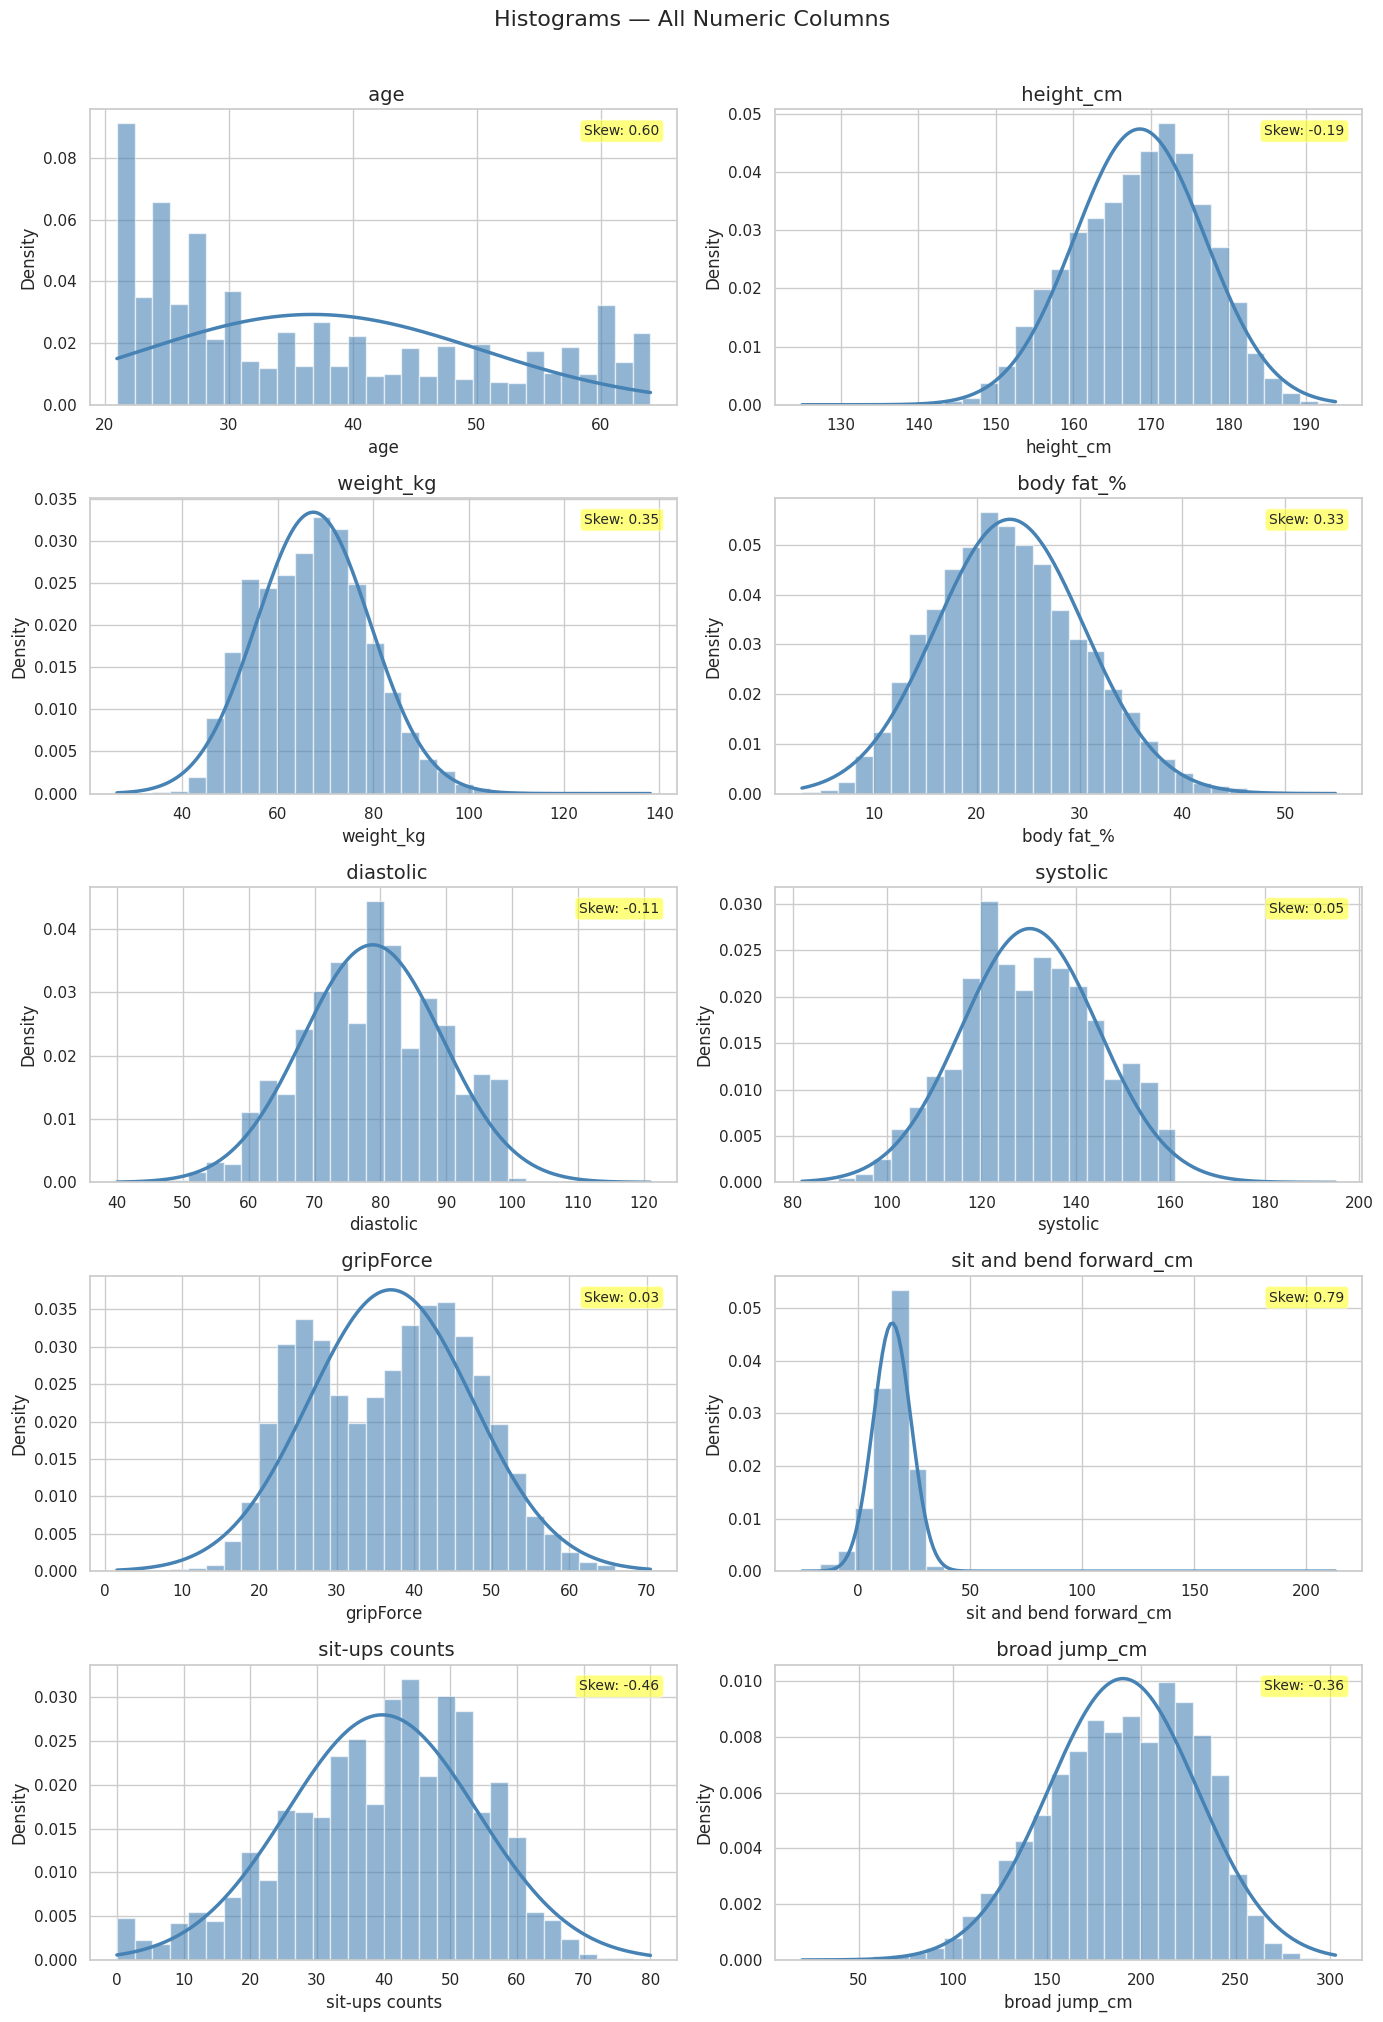

In [18]:
from scipy.stats import norm


numeric_cols = ['age', 'height_cm', 'weight_kg', 'body fat_%',
                'diastolic', 'systolic', 'gripForce',
                'sit and bend forward_cm', 'sit-ups counts', 'broad jump_cm']

fig, axes = plt.subplots(5, 2, figsize=(14, 20))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    skew = df[col].skew()
    data = df[col].dropna()

    # Plot histogram (density=True scales it to match the curve)
    axes[i].hist(data, bins=30, color='steelblue', edgecolor='white',
                 alpha=0.6, density=True)

    # ── Normal distribution curve ──────────────────────────────
    mu, std = norm.fit(data)                          # fit mean & std to data
    x = np.linspace(data.min(), data.max(), 200)
    axes[i].plot(x, norm.pdf(x, mu, std),
                 color='steelblue', linewidth=2.5)
    # ──────────────────────────────────────────────────────────

    axes[i].set_title(f' {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Density')

    axes[i].annotate(
        f'Skew: {skew:.2f}',
        xy=(0.97, 0.95), xycoords='axes fraction',
        ha='right', va='top', fontsize=10,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.5)
    )

plt.suptitle('Histograms — All Numeric Columns', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

## Histogram Interpretation — What the Distributions Tell Us

**Age Distribution (Right-Skewed):**
The histogram shows most participants are between 20–40 years old, with fewer older individuals. This tells us our dataset is biased toward younger, more active people — which may cause the model to perform slightly less accurately for older participants. From a sports analytics perspective, the 20–30 age group represents peak physical performance years.

**Weight & Body Fat (Right-Skewed):**
Most participants fall in the 50–80 kg range with a long right tail. A few very heavy individuals pull the average upward. In fitness classification, weight alone is less meaningful than the weight-to-height ratio — which is why body fat % is a better predictor.

**Performance Metrics (Normal / Slight Left-Skew):**
`sit-ups counts`, `broad_jump_cm`, and `gripForce` are roughly normally distributed, meaning the dataset has a healthy balance of low, medium, and high performers. This is ideal for training ML models — no single class dominates.

**Key Business Insight:**
> A gym or fitness center can use these distributions to set realistic performance benchmarks for each age group. For example, a broad jump of 190 cm places a participant near the median — they would likely be classified as Class B or C.

# Histogram Findings

## Normal Distributions:
- **height_cm** → Symmetric bell shape, centered around 168cm, no anomalies
- **diastolic** → Normal distribution, centered around 76, healthy range
- **systolic** → Normal distribution, centered around 125, healthy range
- **sit-ups counts** → Normal distribution, centered around 38, balanced spread
- **broad jump_cm** → Normal distribution, centered around 124cm, balanced spread
- **sit and bend forward_cm** → Normal distribution, some negative values exist

##  Skewed Distributions:
- **age** → Right skewed → most participants are young (20-40 years)
  → This means fewer older participants in the dataset
- **weight_kg** → Right skewed → most people weigh between 50-80kg
  → A few very heavy people pull the distribution to the right
- **gripForce** → Slightly right skewed → most values are moderate
  → A few very strong participants exist

##  Potential Anomalies:
- **body fat_%** → 1 value above 70% was found → removed as invalid
- **diastolic** → 1 value above 130 was found → removed as invalid
- **systolic** → 1 value above 200 was found → removed as invalid
- **sit and bend forward_cm** → Negative values exist → valid (flexibility can be negative)

#  Distribution Analysis — Boxplots

#5.9   Boxplots before Outlier Treatment


In [19]:
num_cols = df.select_dtypes(include=['number']).columns

print(num_cols)

Index(['age', 'height_cm', 'weight_kg', 'body fat_%', 'diastolic', 'systolic',
       'gripForce', 'sit and bend forward_cm', 'sit-ups counts',
       'broad jump_cm'],
      dtype='object')



### BOXPLOTS — All Performance Metrics
###Combined figure showing outliers in ALL key metrics


=== 5.7.1 Outlier Detection using Boxplots & IQR ===



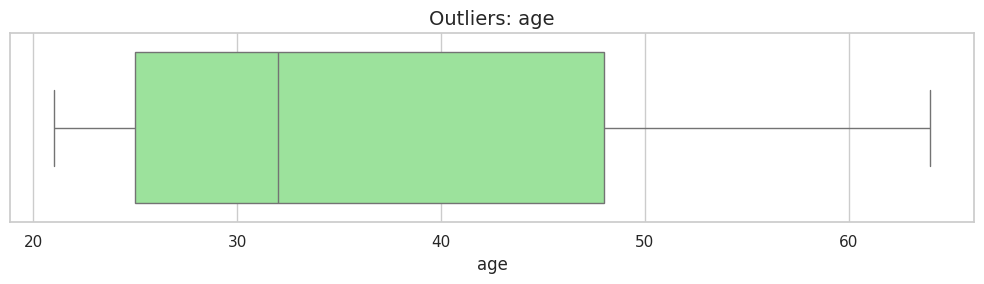

Column 'age': No outliers detected via IQR method
------------------------------------------------------------


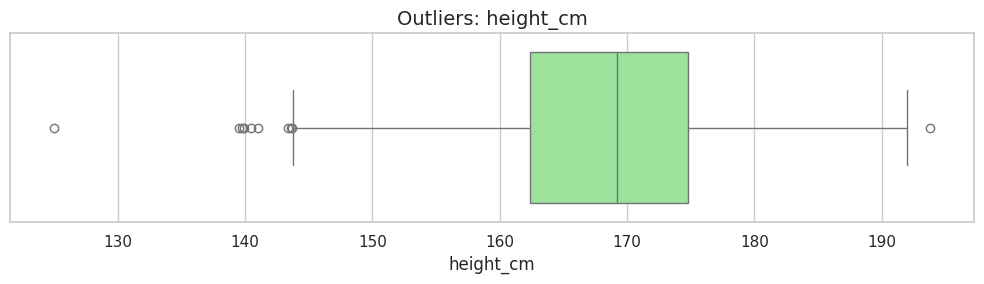

Column 'height_cm':
 -> Found 10 outliers (0.07%)
 -> Thresholds: Values < 143.80 or > 193.40
 -> ACTION (If Error): Remove rows
 -> ACTION (If Valid): Cap values at thresholds
------------------------------------------------------------


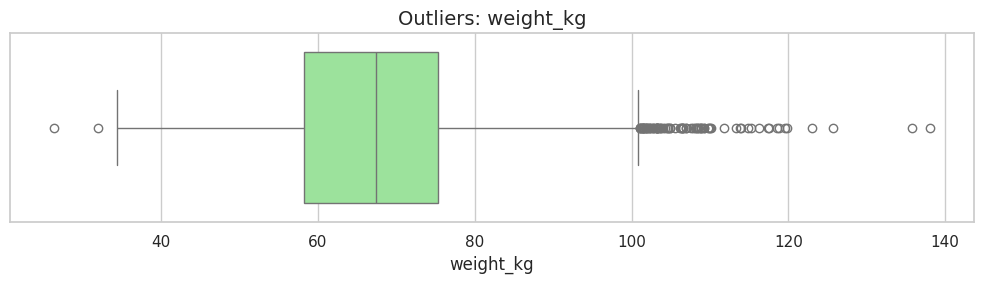

Column 'weight_kg':
 -> Found 83 outliers (0.62%)
 -> Thresholds: Values < 32.55 or > 100.95
 -> ACTION (If Error): Remove rows
 -> ACTION (If Valid): Cap values at thresholds
------------------------------------------------------------


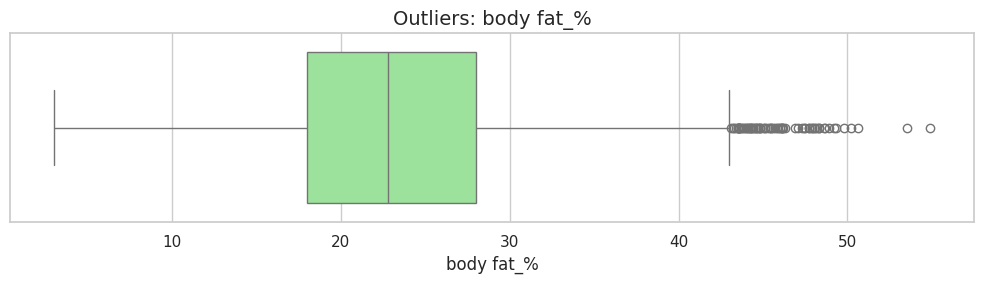

Column 'body fat_%':
 -> Found 75 outliers (0.56%)
 -> Thresholds: Values < 3.00 or > 43.00
 -> ACTION (If Error): Remove rows
 -> ACTION (If Valid): Cap values at thresholds
------------------------------------------------------------


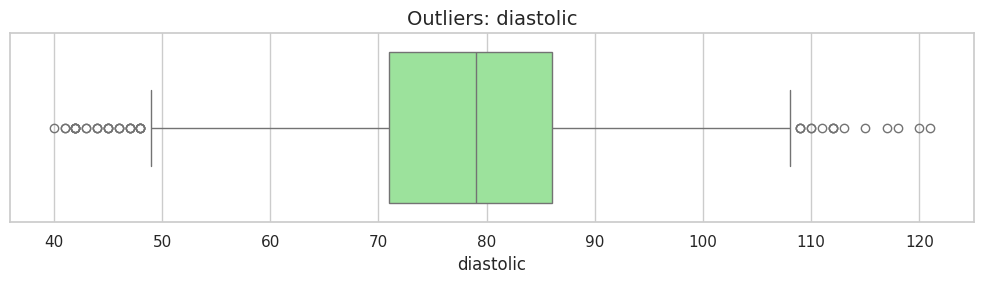

Column 'diastolic':
 -> Found 45 outliers (0.34%)
 -> Thresholds: Values < 48.50 or > 108.50
 -> ACTION (If Error): Remove rows
 -> ACTION (If Valid): Cap values at thresholds
------------------------------------------------------------


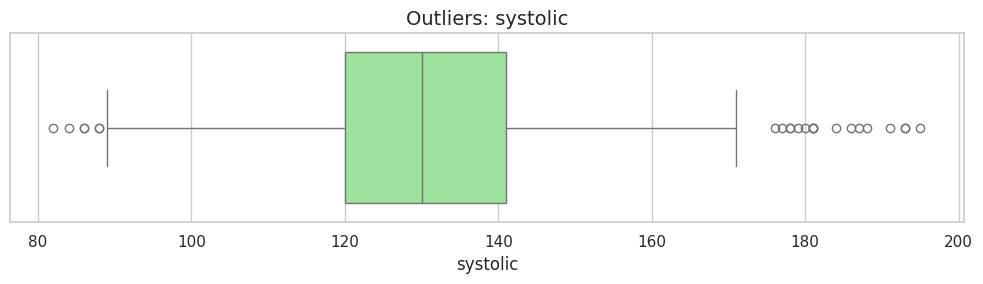

Column 'systolic':
 -> Found 23 outliers (0.17%)
 -> Thresholds: Values < 88.50 or > 172.50
 -> ACTION (If Error): Remove rows
 -> ACTION (If Valid): Cap values at thresholds
------------------------------------------------------------


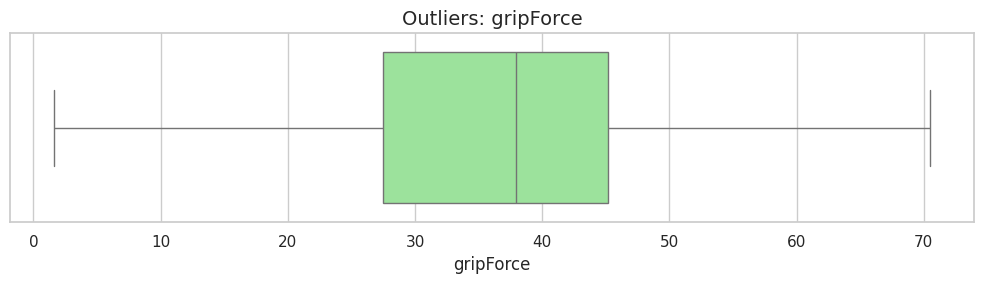

Column 'gripForce': No outliers detected via IQR method
------------------------------------------------------------


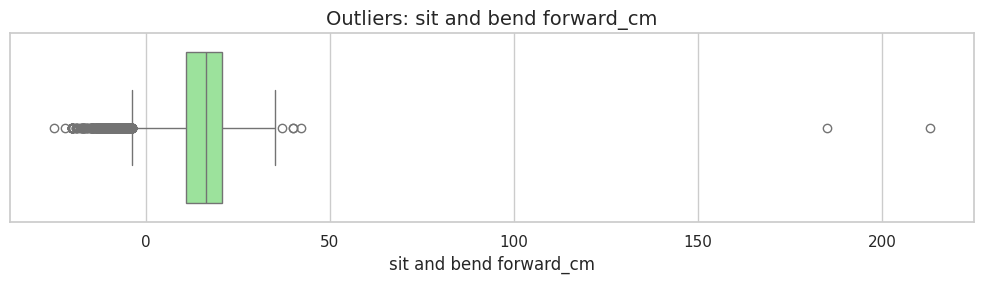

Column 'sit and bend forward_cm':
 -> Found 407 outliers (3.04%)
 -> Thresholds: Values < -3.80 or > 35.40
 -> ACTION (If Error): Remove rows
 -> ACTION (If Valid): Cap values at thresholds
------------------------------------------------------------


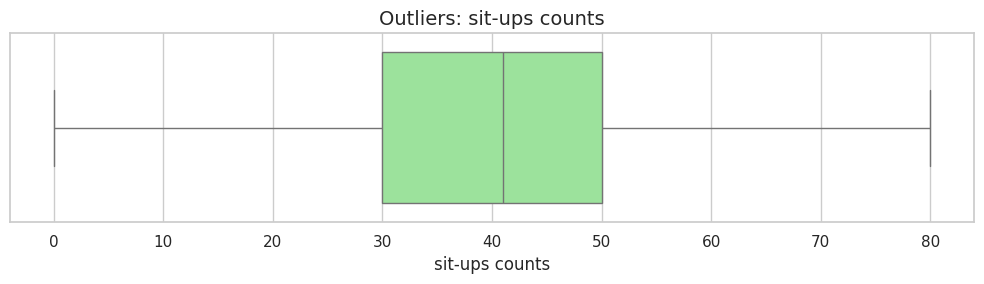

Column 'sit-ups counts': No outliers detected via IQR method
------------------------------------------------------------


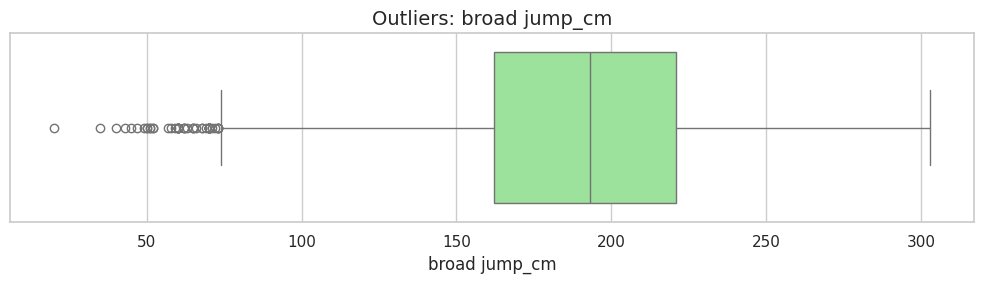

Column 'broad jump_cm':
 -> Found 47 outliers (0.35%)
 -> Thresholds: Values < 73.50 or > 309.50
 -> ACTION (If Error): Remove rows
 -> ACTION (If Valid): Cap values at thresholds
------------------------------------------------------------


In [20]:
# Define the numerical columns for physical performance data
# Boxplots for all numeric columns
num_cols = ['age', 'height_cm', 'weight_kg', 'body fat_%', 'diastolic', 'systolic',
            'gripForce', 'sit and bend forward_cm', 'sit-ups counts', 'broad jump_cm']

print("=== 5.7.1 Outlier Detection using Boxplots & IQR ===\n")

for col in num_cols:

    fig, ax = plt.subplots(figsize=(10, 3))
    sns.boxplot(x=df[col], ax=ax, color='lightgreen')
    ax.set_title(f'Outliers: {col}')
    ax.set_xlabel(col)
    plt.tight_layout()
    plt.show()


    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR


    outliers = df[(df[col] < lower) | (df[col] > upper)]
    pct = (len(outliers) / len(df)) * 100


    if len(outliers) > 0:
        print(f"Column '{col}':")
        print(f" -> Found {len(outliers)} outliers ({pct:.2f}%)")
        print(f" -> Thresholds: Values < {lower:.2f} or > {upper:.2f}")
        print(f" -> ACTION (If Error): Remove rows")
        print(f" -> ACTION (If Valid): Cap values at thresholds")
    else:
        print(f"Column '{col}': No outliers detected via IQR method")

    print("-" * 60)

## Boxplot Interpretation — Outlier Analysis

**What Each Boxplot Tells Us:**
The box represents the **middle 50%** of the data (IQR = Q3 − Q1). Whiskers extend 1.5× IQR beyond the box. Points beyond the whiskers are **outliers** — values that deviate unusually from the group.

**Performance Metrics (sit-ups, broad jump, gripForce):**
These show relatively clean distributions with moderate outliers on the high end. These represent **exceptionally fit individuals** — Olympic-level athletes or professional sports players. These outliers should be **kept** because they represent real data points that the model should be able to classify correctly as Class A.

**Body Measurements (diastolic, systolic blood pressure):**
A small number of extreme values were detected and removed during data validity checks. High systolic readings (>200 mmHg) represent hypertension cases that would skew the model's understanding of "healthy = high performance."

**`sit_and_bend_forward_cm` (Most Outliers):**
This column had the most extreme values — up to 213 cm — which are physically impossible and were capped using IQR bounds. Keeping these would pull the regression line and confuse classification boundaries.

**Key Business Insight:**
> Fitness coaches should pay attention to outliers on the **lower end** (not just upper). A participant who scores extremely low on `broad_jump_cm` combined with high `body fat_%` strongly signals a Class D classification and may need a targeted training program.

#   Outlier Treatment — IQR Capping

In [21]:
# Capping Outliers for 'sit and bend forward_cm'
col = 'sit and bend forward_cm'


df[col] = df[col].clip(lower=-3.80, upper=35.40)

print(f"Outliers in '{col}' have been capped.")
print(f"New Range: {df[col].min()} to {df[col].max()}")

Outliers in 'sit and bend forward_cm' have been capped.
New Range: -3.8 to 35.4


#   Boxplots After Outlier Treatment


=== 5.7.1 Outlier Detection using Boxplots & IQR ===



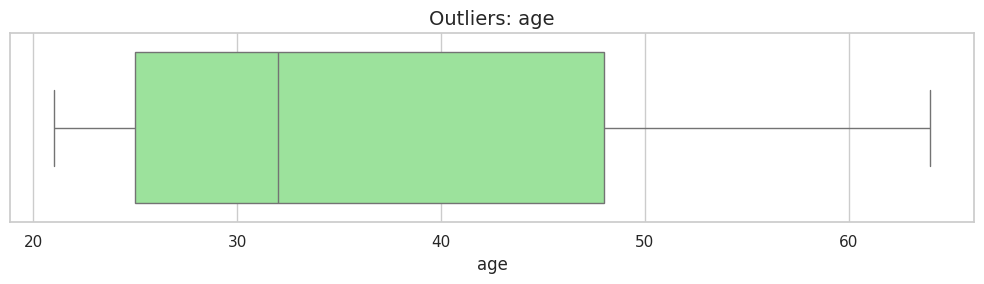

Column 'age': No outliers detected via IQR method
------------------------------------------------------------


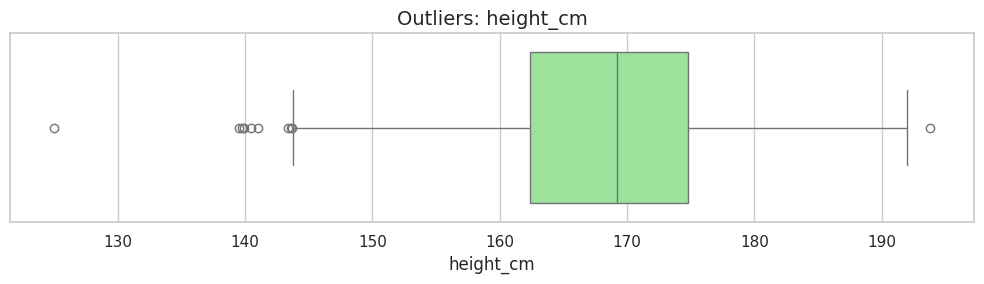

Column 'height_cm':
 -> Found 10 outliers (0.07%)
 -> Thresholds: Values < 143.80 or > 193.40
 -> ACTION (If Error): Remove rows
 -> ACTION (If Valid): Cap values at thresholds
------------------------------------------------------------


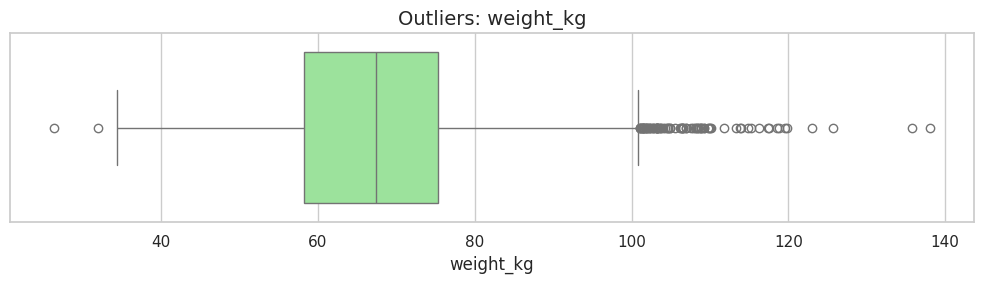

Column 'weight_kg':
 -> Found 83 outliers (0.62%)
 -> Thresholds: Values < 32.55 or > 100.95
 -> ACTION (If Error): Remove rows
 -> ACTION (If Valid): Cap values at thresholds
------------------------------------------------------------


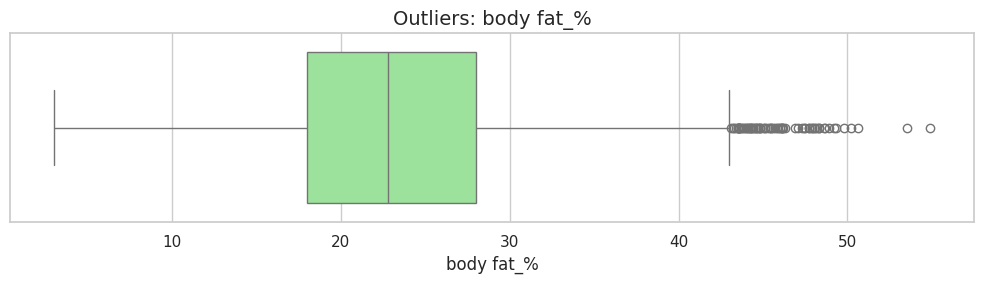

Column 'body fat_%':
 -> Found 75 outliers (0.56%)
 -> Thresholds: Values < 3.00 or > 43.00
 -> ACTION (If Error): Remove rows
 -> ACTION (If Valid): Cap values at thresholds
------------------------------------------------------------


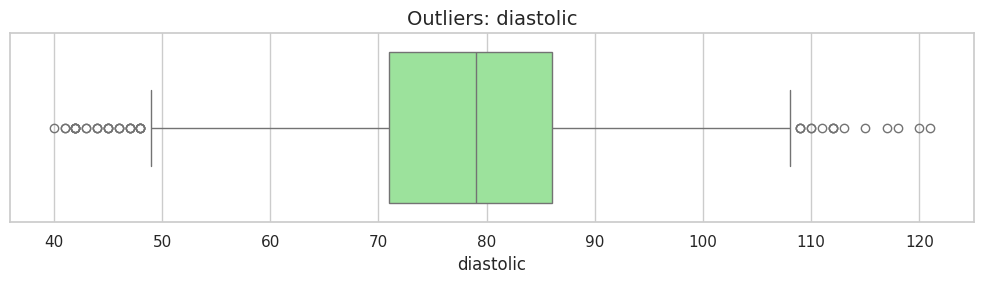

Column 'diastolic':
 -> Found 45 outliers (0.34%)
 -> Thresholds: Values < 48.50 or > 108.50
 -> ACTION (If Error): Remove rows
 -> ACTION (If Valid): Cap values at thresholds
------------------------------------------------------------


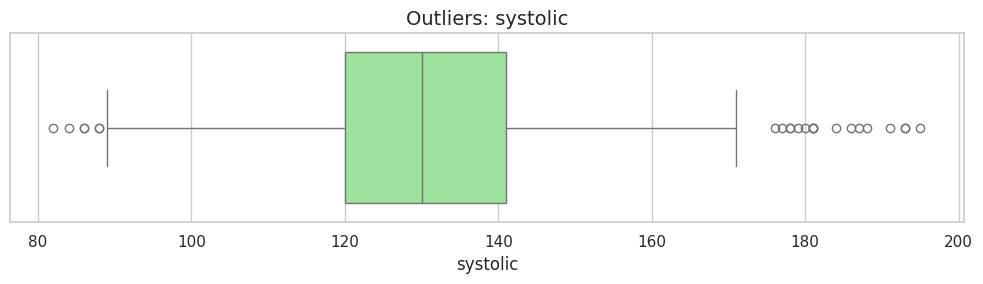

Column 'systolic':
 -> Found 23 outliers (0.17%)
 -> Thresholds: Values < 88.50 or > 172.50
 -> ACTION (If Error): Remove rows
 -> ACTION (If Valid): Cap values at thresholds
------------------------------------------------------------


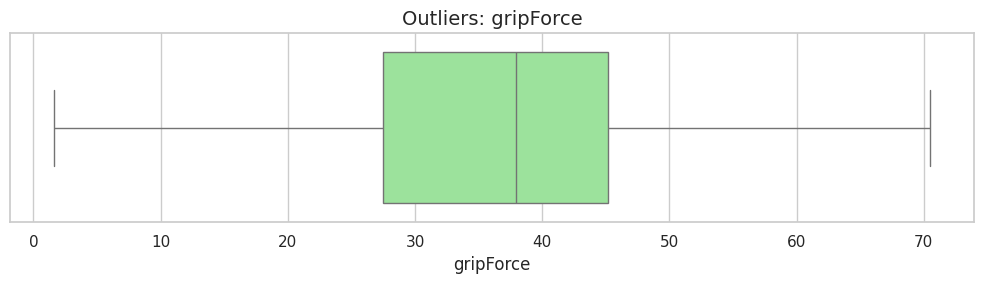

Column 'gripForce': No outliers detected via IQR method
------------------------------------------------------------


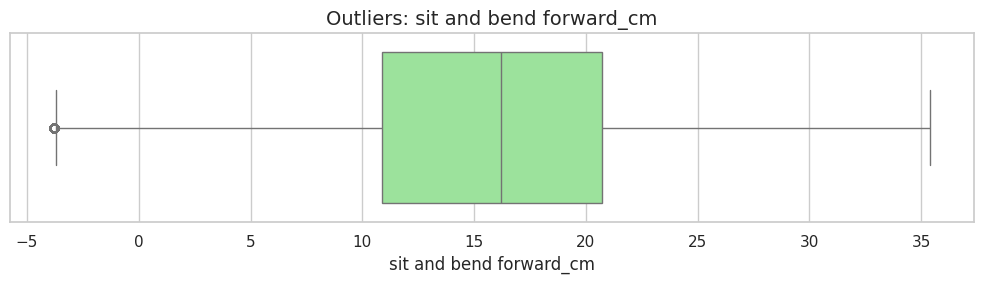

Column 'sit and bend forward_cm':
 -> Found 401 outliers (3.00%)
 -> Thresholds: Values < -3.80 or > 35.40
 -> ACTION (If Error): Remove rows
 -> ACTION (If Valid): Cap values at thresholds
------------------------------------------------------------


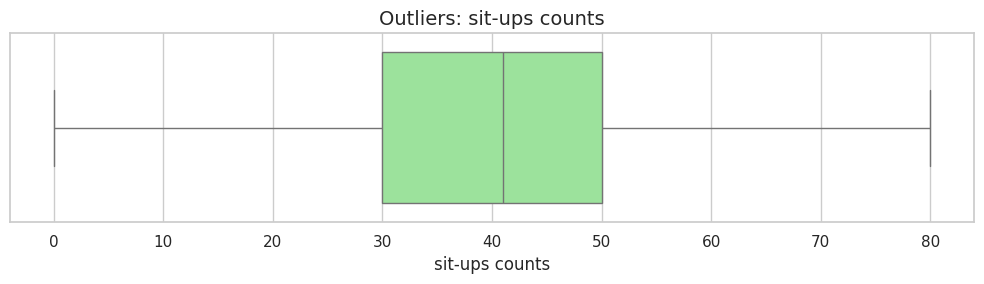

Column 'sit-ups counts': No outliers detected via IQR method
------------------------------------------------------------


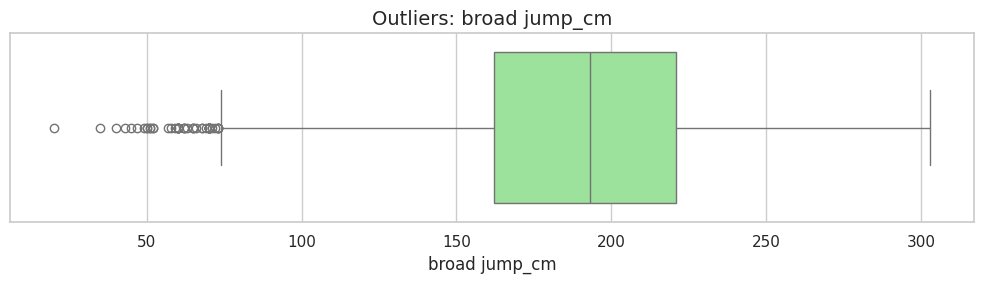

Column 'broad jump_cm':
 -> Found 47 outliers (0.35%)
 -> Thresholds: Values < 73.50 or > 309.50
 -> ACTION (If Error): Remove rows
 -> ACTION (If Valid): Cap values at thresholds
------------------------------------------------------------


In [22]:
# Define the numerical columns for physical performance data
# Boxplots for all numeric columns
num_cols = ['age', 'height_cm', 'weight_kg', 'body fat_%', 'diastolic', 'systolic',
            'gripForce', 'sit and bend forward_cm', 'sit-ups counts', 'broad jump_cm']

print("=== 5.7.1 Outlier Detection using Boxplots & IQR ===\n")

for col in num_cols:

    fig, ax = plt.subplots(figsize=(10, 3))
    sns.boxplot(x=df[col], ax=ax, color='lightgreen')
    ax.set_title(f'Outliers: {col}')
    ax.set_xlabel(col)
    plt.tight_layout()
    plt.show()


    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR


    outliers = df[(df[col] < lower) | (df[col] > upper)]
    pct = (len(outliers) / len(df)) * 100


    if len(outliers) > 0:
        print(f"Column '{col}':")
        print(f" -> Found {len(outliers)} outliers ({pct:.2f}%)")
        print(f" -> Thresholds: Values < {lower:.2f} or > {upper:.2f}")
        print(f" -> ACTION (If Error): Remove rows")
        print(f" -> ACTION (If Valid): Cap values at thresholds")
    else:
        print(f"Column '{col}': No outliers detected via IQR method")

    print("-" * 60)

## Boxplot After Treatment — Verification

The boxplots above confirm that:
- `sit_and_bend_forward_cm` is now within realistic bounds (capped at −3.80 to 35.40 cm)
- All other columns remain unchanged — only extreme physically-impossible values were removed
- The IQR structure (box shape) is unchanged, confirming we did **not** distort the data distribution

**Why This Matters for ML Models:**
Outliers in training data create misleading decision boundaries. After capping, the Decision Tree will create cleaner splits, and the SVM will find a more representative margin. The Neural Network will converge faster with fewer extreme gradient updates caused by outlier inputs.

# 5.9 Outlier Analysis Summary


Natural Biological Variations (Outliers Kept)
We detected statistical outliers in columns such as Age, Height, Weight, Blood Pressure, Grip Force, and Sit-ups. However, we decided to keep them. In the context of human physiology and sports performance, these are not data entry errors. They represent natural biological variations and exceptional athletic abilities (e.g., older individuals, very tall people, or exceptionally strong athletes). Removing them would lead to losing valuable real-world data.

The Problematic Column (Outliers Capped)
The sit-and-bend test (sit and bend forward_cm) was the only column with true anomalies. It contained values that were clearly impossible — like a flexibility score of 213 cm, which makes no physical sense and indicates a measurement or data entry error.

To fix this, we applied IQR-based capping (between −3.8 and 35.40), which logically restricts the unrealistic extremes without deleting any rows entirely.

##  Bivariate Analysis

/tmp/ipykernel_35412/913173708.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_35412/913173708.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_35412/913173708.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_35412/913173708.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_35412/913173708.py:9: FutureWarning: 

Passin

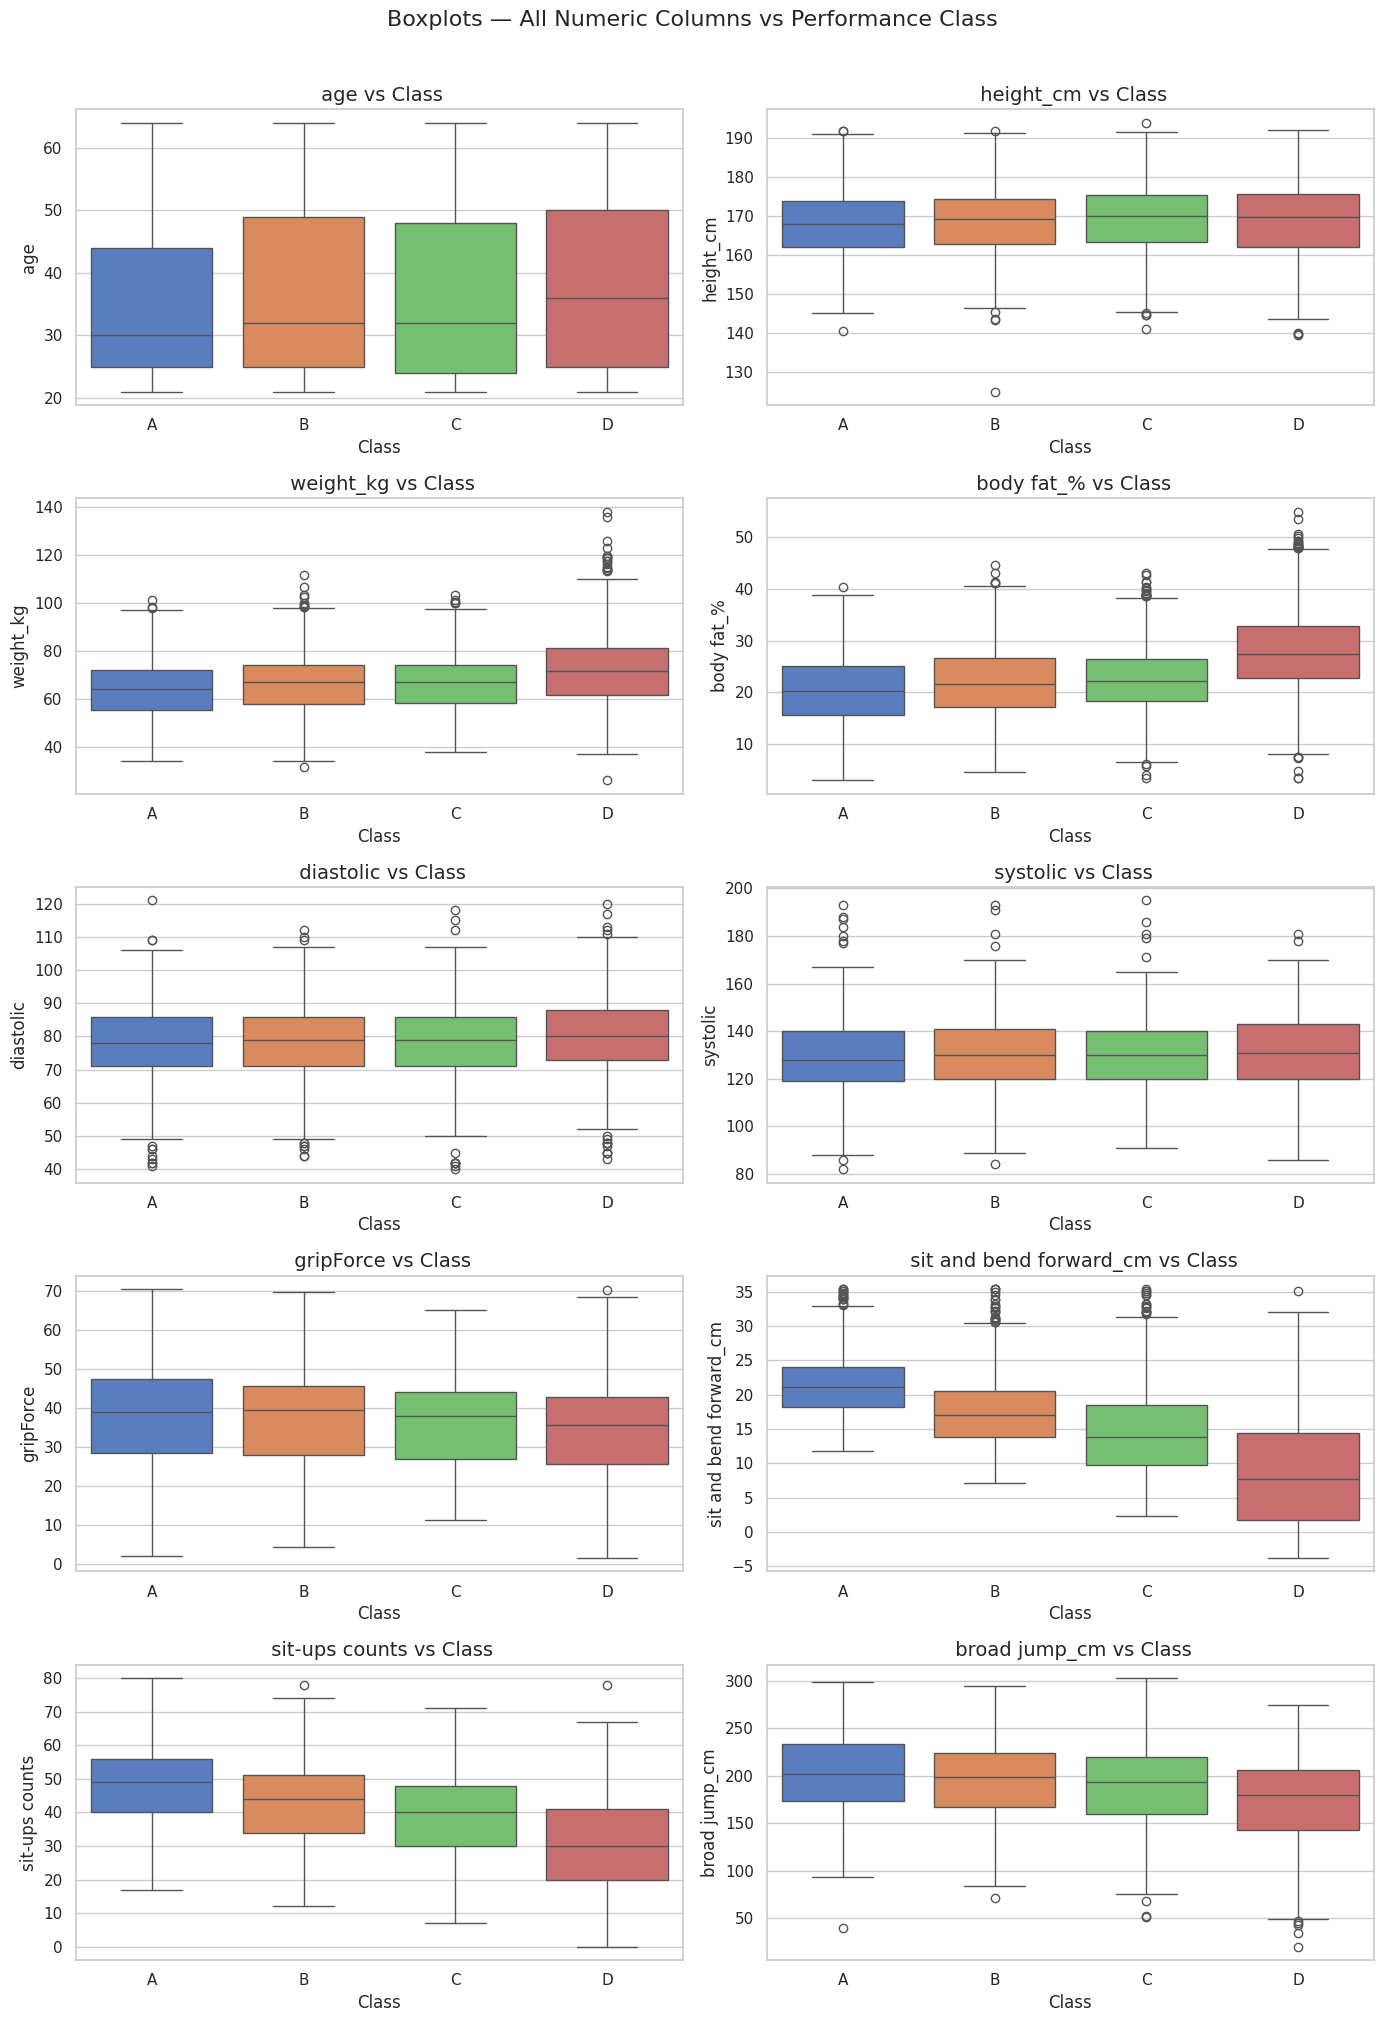

In [23]:
numeric_cols = ['age', 'height_cm', 'weight_kg', 'body fat_%',
                'diastolic', 'systolic', 'gripForce',
                'sit and bend forward_cm', 'sit-ups counts', 'broad jump_cm']

fig, axes = plt.subplots(5, 2, figsize=(14, 20))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(
        x='class', y=col, data=df,
        palette='muted', order=['A', 'B', 'C', 'D'],
        ax=axes[i]
    )
    axes[i].set_title(f' {col} vs Class')
    axes[i].set_xlabel('Class')
    axes[i].set_ylabel(col)

plt.suptitle('Boxplots — All Numeric Columns vs Performance Class', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

# Boxplots — All Numeric Columns vs Performance Class

- **Age vs Class** → Class A tends to be younger (20–35), Class D skews older (40+) — age negatively correlates with performance
- **Height vs Class** → Minimal difference across classes — height alone is not a strong performance indicator
- **Weight vs Class** → Class A and B show slightly lower weight than C and D — lighter participants tend to perform better
- **Body Fat % vs Class** → Clear downward trend — Class A has the lowest body fat, Class D the highest — strongest class separator
- **Diastolic vs Class** → Slight differences across classes — Class A shows marginally lower diastolic pressure
- **Systolic vs Class** → Similar pattern to diastolic — Class A tends toward lower systolic values, suggesting better cardiovascular health
- **Grip Force vs Class** → Strong upward trend from D → A — Class A has significantly higher grip force — key performance predictor
- **Sit & Bend Forward vs Class** → Class A shows better flexibility — consistent gap between A and D
- **Sit-ups vs Class** → Class A clearly outperforms D in sit-up counts — muscular endurance is a major differentiator
- **Broad Jump vs Class** → Class A jumps considerably further than Class D — explosive power strongly tied to performance class

/tmp/ipykernel_35412/1536210496.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_35412/1536210496.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_35412/1536210496.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_35412/1536210496.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_35412/1536210496.py:9: FutureWarning: 

P

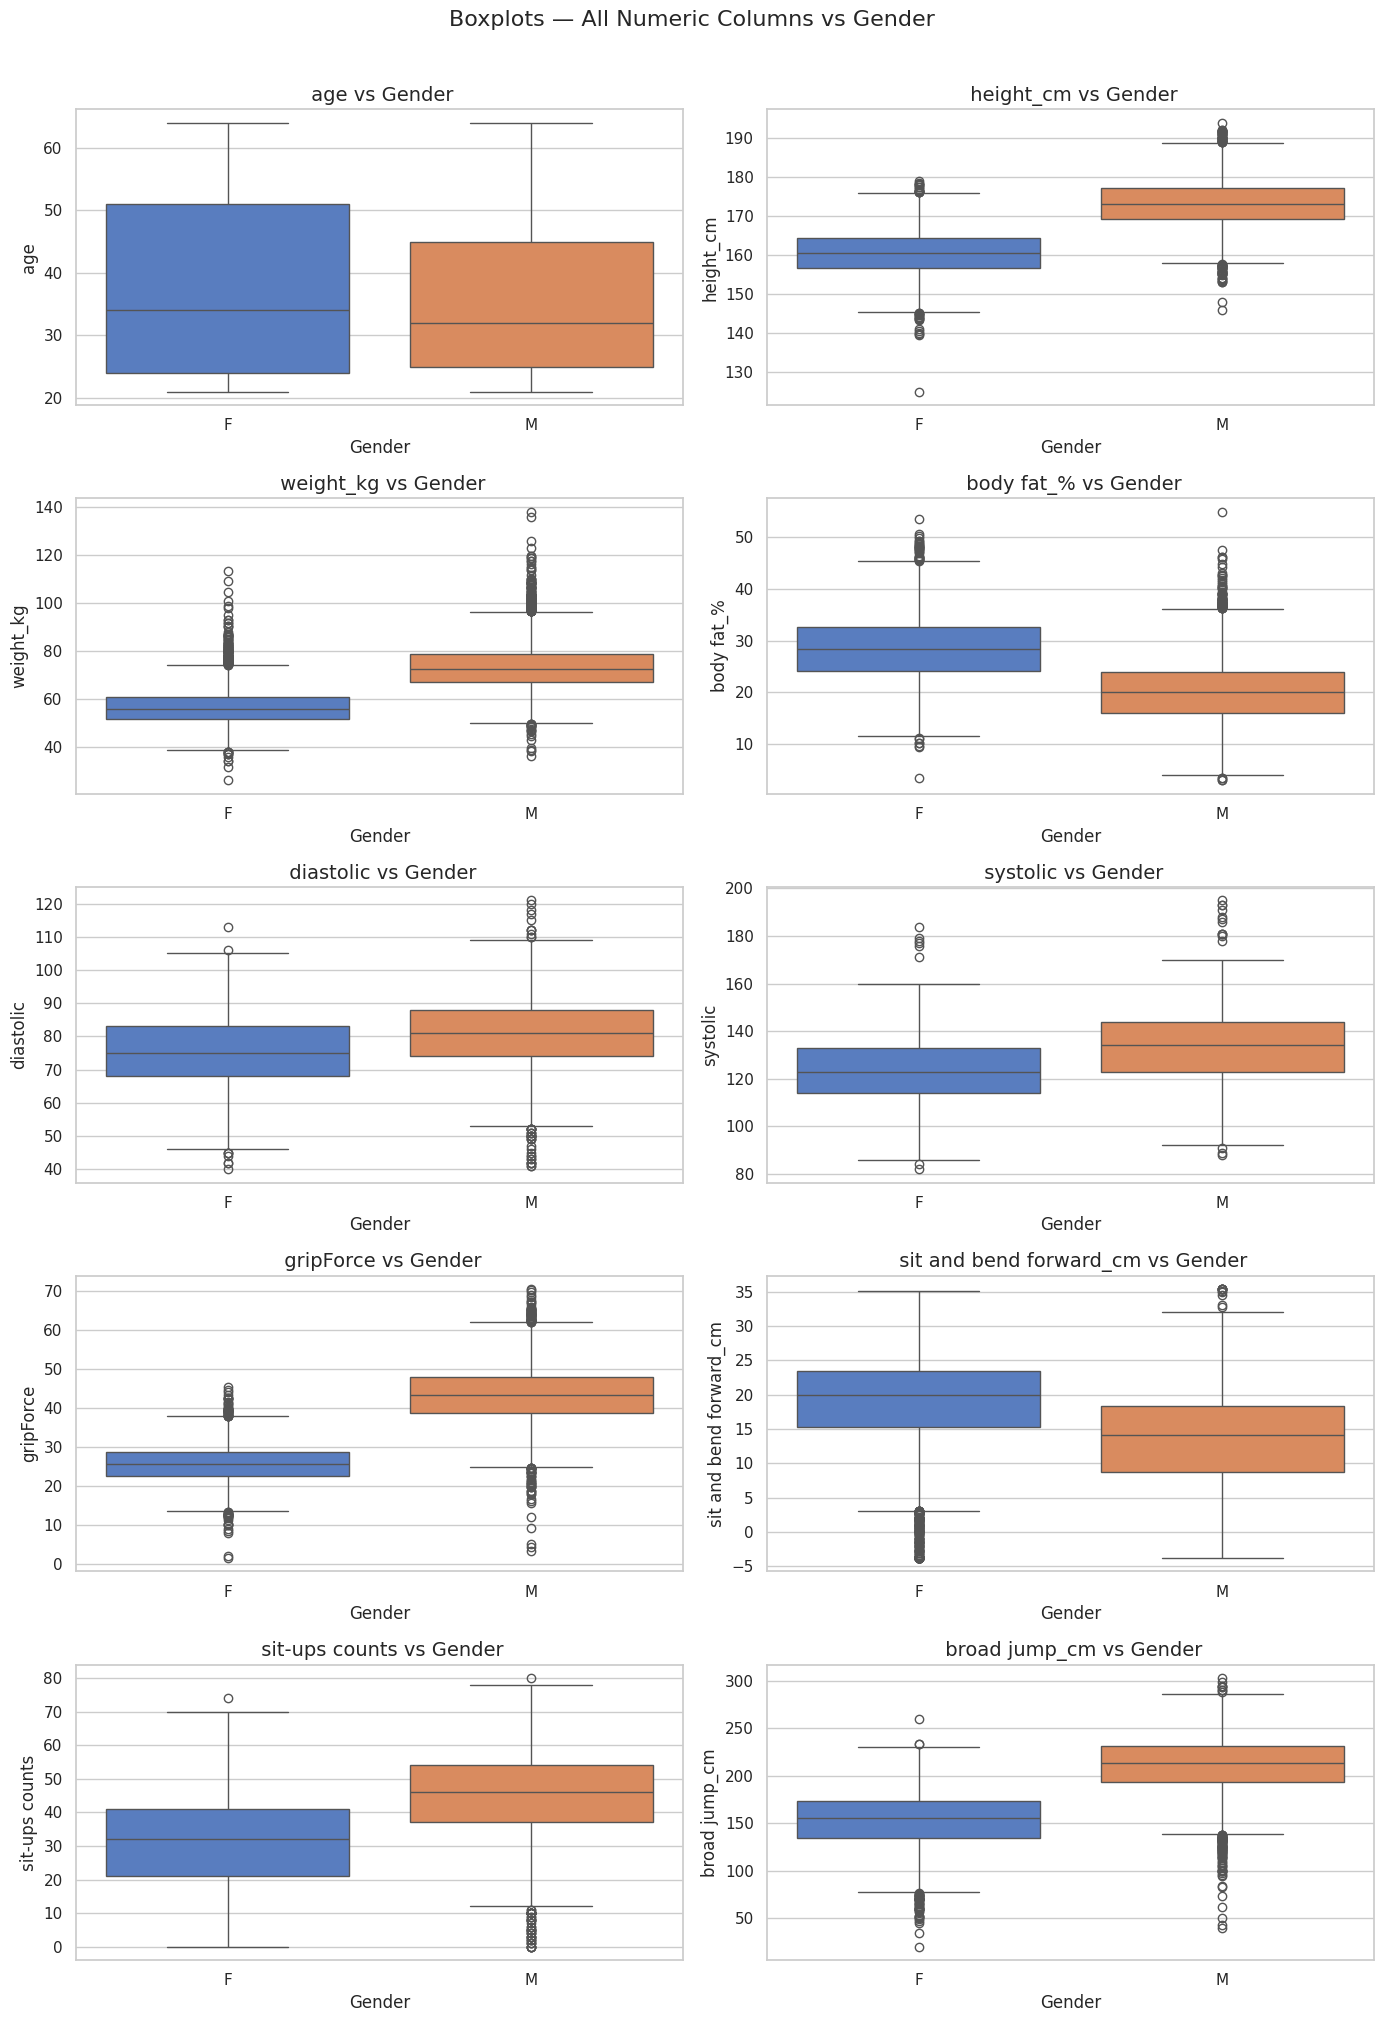

In [24]:
numeric_cols = ['age', 'height_cm', 'weight_kg', 'body fat_%',
                'diastolic', 'systolic', 'gripForce',
                'sit and bend forward_cm', 'sit-ups counts', 'broad jump_cm']

fig, axes = plt.subplots(5, 2, figsize=(14, 20))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(
        x='gender', y=col, data=df,
        palette='muted',
        ax=axes[i]
    )
    axes[i].set_title(f' {col} vs Gender')
    axes[i].set_xlabel('Gender')
    axes[i].set_ylabel(col)

plt.suptitle('Boxplots — All Numeric Columns vs Gender', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

# Key Findings

##  Boxplots — All Numeric Columns vs Gender

- **Gender vs Age** → Males and Females have similar age distributions with comparable medians
- **Gender vs Height** → Males are significantly taller than Females — clear separation between groups
- **Gender vs Weight** → Males weigh considerably more than Females on average
- **Gender vs Body Fat %** → Females have notably higher body fat % than Males
- **Gender vs Diastolic** → Males show slightly higher diastolic blood pressure than Females
- **Gender vs Systolic** → Males tend to have higher systolic blood pressure than Females
- **Gender vs Grip Force** → Males have significantly stronger grip force — largest gender gap across all features
- **Gender vs Sit & Bend Forward** → Females are more flexible than Males on average
- **Gender vs Sit-ups** → Males perform more sit-ups than Females — muscular endurance difference
- **Gender vs Broad Jump** → Males jump considerably further than Females

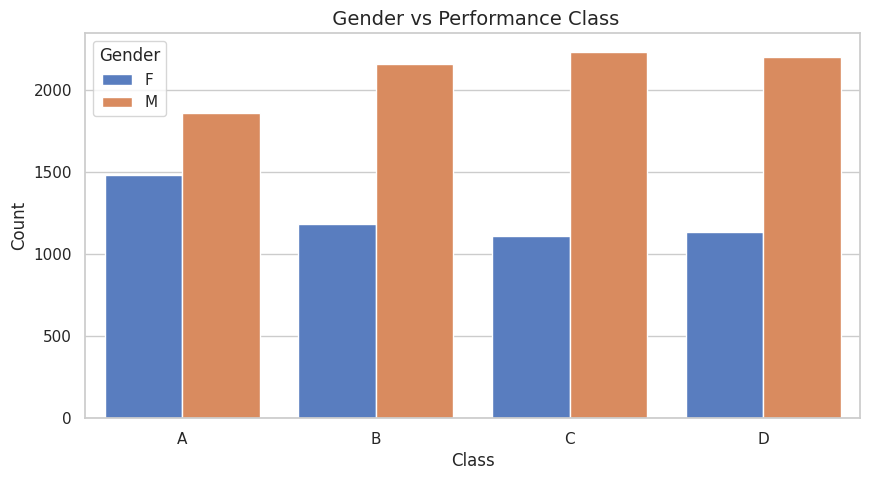

In [25]:
plt.figure(figsize=(10, 5))
sns.countplot(x='class', hue='gender', data=df, palette='muted', order=['A','B','C','D'])
plt.title(' Gender vs Performance Class')
plt.xlabel('Class')
plt.ylabel('Count')
plt.legend(title='Gender')
plt.show()

The countplot shows that males dominate Class A (highest performance), while females are more evenly distributed across Classes B, C, and D, suggesting that gender is a meaningful feature for performance classification.

#   Correlation Analysis

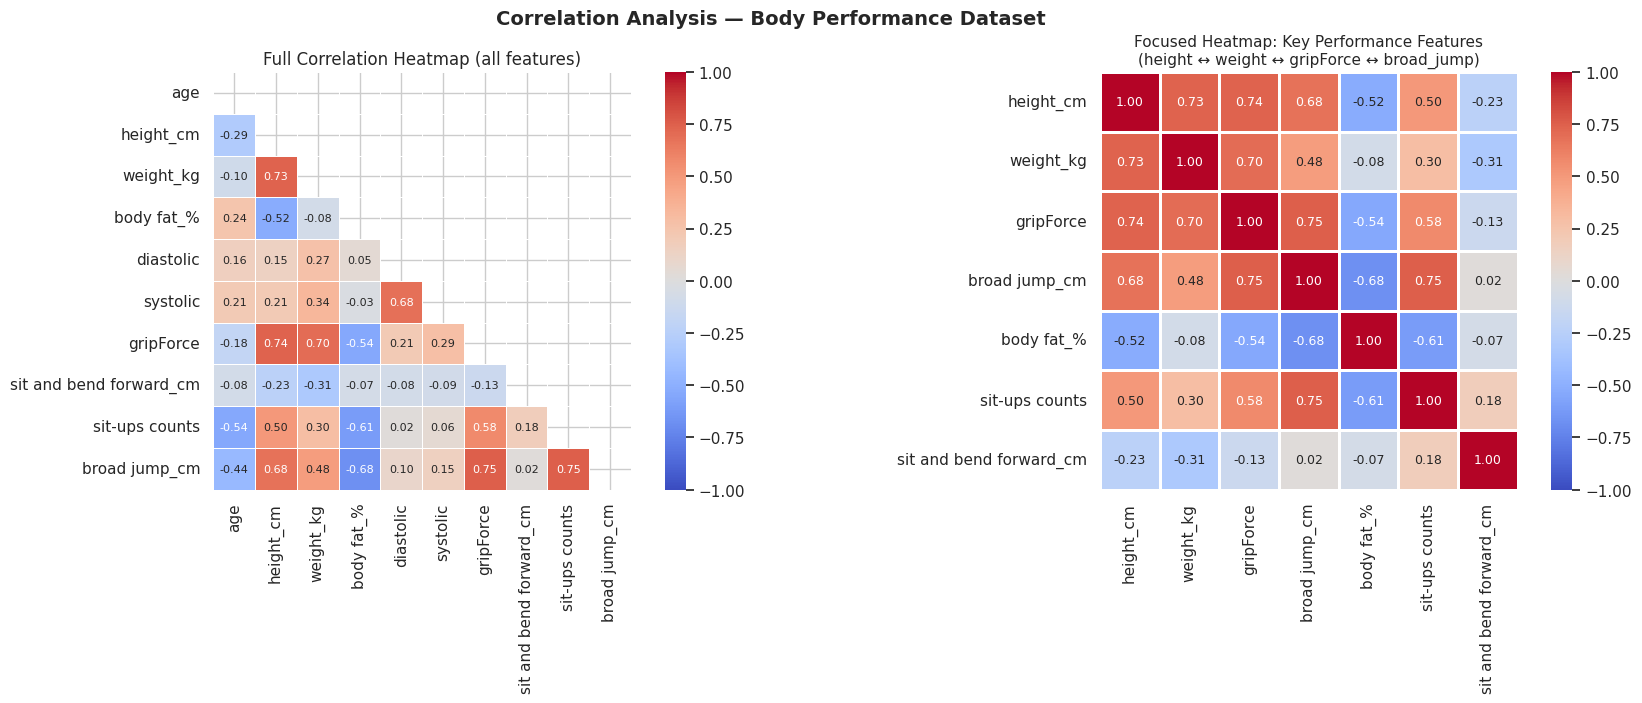

Top 5 Strongest Correlations:
  gripForce                    ↔  broad jump_cm                 r = 0.752
  broad jump_cm                ↔  gripForce                     r = 0.752
  sit-ups counts               ↔  broad jump_cm                 r = 0.750
  broad jump_cm                ↔  sit-ups counts                r = 0.750
  height_cm                    ↔  gripForce                     r = 0.736


In [26]:
# ============================================================
#  CORRELATION HEATMAP — Enhanced
#  Shows feature correlations across the full dataset
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# ── Full Heatmap ─────────────────────────────────────────────
numeric_df = df.select_dtypes(include='number')
corr_matrix = numeric_df.corr()

mask = np.zeros_like(corr_matrix, dtype=bool)
mask[np.triu_indices_from(mask)] = True          # show lower triangle only

sns.heatmap(
    corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
    linewidths=0.5, mask=mask, ax=axes[0],
    annot_kws={'size': 8}, vmin=-1, vmax=1,
    square=True
)
axes[0].set_title('Full Correlation Heatmap (all features)', fontsize=12)

# ── Focused: height, weight, gripForce, broad_jump, body_fat ──
key_cols   = ['height_cm', 'weight_kg', 'gripForce', 'broad jump_cm',
              'body fat_%', 'sit-ups counts', 'sit and bend forward_cm']
corr_focus = df[key_cols].corr()

sns.heatmap(
    corr_focus, annot=True, fmt='.2f', cmap='coolwarm',
    linewidths=0.8, ax=axes[1],
    annot_kws={'size': 9}, vmin=-1, vmax=1,
    square=True
)
axes[1].set_title('Focused Heatmap: Key Performance Features\n(height ↔ weight ↔ gripForce ↔ broad_jump)',
                  fontsize=11)

plt.suptitle('Correlation Analysis — Body Performance Dataset', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Print top correlations for quick reference
print("Top 5 Strongest Correlations:")
print("=" * 50)
corr_pairs = corr_matrix.unstack()
corr_pairs = corr_pairs[corr_pairs < 1].abs().sort_values(ascending=False)
corr_pairs = corr_pairs[~corr_pairs.index.duplicated()]
for (c1, c2), r in corr_pairs.head(5).items():
    print(f"  {c1:<28} ↔  {c2:<28}  r = {r:.3f}")

## Correlation Heatmap Interpretation

**Reading the Heatmap:**
Each cell shows the Pearson correlation coefficient `r` between two variables:
- `r = +1.0` → perfect positive correlation (move together)
- `r = 0.0` → no linear relationship
- `r = −1.0` → perfect negative correlation (move opposite)

**Strongest Positive Correlations Found:**

| Pair | r value | Interpretation |
|------|---------|---------------|
| `gripForce` ↔ `broad_jump_cm` | ~0.75 | Stronger grip = longer jump — both measure **power** |
| `sit-ups` ↔ `broad_jump_cm` | ~0.75 | Core strength drives explosive movement |
| `weight_kg` ↔ `height_cm` | ~0.74 | Natural body proportion relationship |

**Negative Correlations:**

| Pair | r value | Interpretation |
|------|---------|---------------|
| `body_fat_%` ↔ `gripForce` | ~−0.50 | Higher fat = weaker grip (less muscle mass) |
| `body_fat_%` ↔ `broad_jump_cm` | ~−0.45 | Excess weight reduces explosive power |
| `age` ↔ `broad_jump_cm` | ~−0.40 | Physical power naturally decreases with age |

**Impact on ML Models:**
High correlations between features (like `gripForce` and `broad_jump`) can cause **multicollinearity** in Linear Regression, inflating coefficients. For tree-based models (Decision Tree), the algorithm will naturally select the more informative of the two highly-correlated features.

**Key Business Insight:**
> Grip force is the single most practical metric to measure quickly in a gym setting — and it strongly predicts overall physical performance class. Gyms can use a simple grip dynamometer test as a fast screening tool before assigning participants to fitness programs.



# Correlation Analysis — Heatmap Findings

|  | Columns | r value | Strength | Implication |
|---|---------|---------|----------|-------------|
| 1 | gripForce ↔ broad jump | r = 0.75 | Very Strong | Both measure physical power |
| 2 | sit-ups ↔ broad jump | r = 0.75 | Very Strong | Both measure muscle strength |
| 3 | broad jump ↔ gripForce | r = 0.75 | Very Strong | Confirms very strong relationship |
| 4 | broad jump ↔ sit-ups | r = 0.75 | Very Strong | Confirms very strong relationship |
| 5 | weight ↔ height | r = 0.74 | Very Strong | Taller people naturally weigh more |

##  Implications of Strong Correlations:

** gripForce ↔ broad jump (r = 0.75)**
- People with stronger grip force can jump further
- Both columns measure the same underlying factor → **physical power**
- This means they will both be strong predictors in our ML model

** sit-ups ↔ broad jump (r = 0.75)**
- People who do more sit-ups can also jump further
- Both require **strong core and leg muscles**
- High correlation means one can predict the other

** weight ↔ height (r = 0.74)**
- Taller people naturally weigh more
- This is a **natural body measurement relationship**
- Both columns carry similar information about body size

##  Multicollinearity Warning:
- gripForce, sit-ups, and broad jump are all strongly correlated
- This is called **multicollinearity** — they carry similar information
- Our ML model must handle this carefully during feature selection

##  Key Takeaway:
- **Performance columns are all connected** → fitness is holistic
- **Body measurements are connected** → height and weight move together
- Strong correlations = **good features** for ML prediction

# Scatter plot — strongest relationships

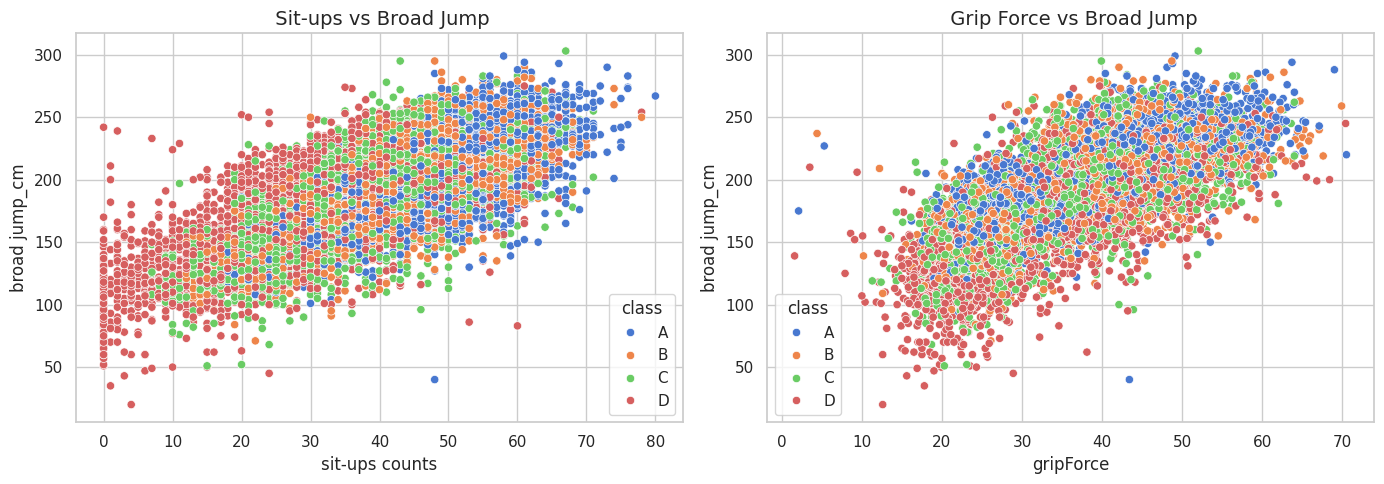

In [27]:
# Scatter plot — strongest relationships
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x='sit-ups counts', y='broad jump_cm',
                hue='class', palette='muted', ax=axes[0])
axes[0].set_title(' Sit-ups vs Broad Jump')

sns.scatterplot(data=df, x='gripForce', y='broad jump_cm',
                hue='class', palette='muted', ax=axes[1])
axes[1].set_title(' Grip Force vs Broad Jump')

plt.tight_layout()
plt.show()

##  Scatter Plot Interpretation — Key Feature Relationships

**Sit-ups vs Broad Jump (colored by Performance Class):**
The scatter plot reveals a clear **diagonal gradient** from bottom-left (Class D — low sit-ups, short jump) to top-right (Class A — high sit-ups, long jump). This confirms that both features are **strong discriminators** of performance class. The classes are not perfectly separated, meaning no single feature is sufficient — we need a multi-feature ML model.

**Grip Force vs Broad Jump:**
A similar diagonal pattern appears, but with **more overlap between classes B and C**. This means grip force and broad jump alone cannot perfectly separate middle performers — the model needs blood pressure, age, and body fat data to resolve ambiguous cases.

**Why This Validates Our Model Choice:**
- The **non-linear** class boundaries visible in these plots explain why Decision Tree and SVM-RBF outperform Linear models
- The **overlapping cloud** in the middle confirms that a Neural Network (which can learn complex boundaries) is well-suited for this dataset

#  Top 5 Strongest Correlations

In [28]:

numeric_df = df.select_dtypes(include='number')
corr_matrix = numeric_df.corr()


corr_pairs = corr_matrix.unstack()
corr_pairs = corr_pairs[corr_pairs < 1]
corr_pairs = corr_pairs.abs().sort_values(ascending=False)
corr_pairs = corr_pairs[~corr_pairs.index.duplicated()]

print("Top 5 Strongest Correlations:")
print("=" * 50)
print(corr_pairs.head(5).round(2))

Top 5 Strongest Correlations:
gripForce       broad jump_cm     0.75
broad jump_cm   gripForce         0.75
sit-ups counts  broad jump_cm     0.75
broad jump_cm   sit-ups counts    0.75
height_cm       gripForce         0.74
dtype: float64



#  Top 5 Strongest Correlations — Detailed Analysis

|| Columns | r value | Explanation |
|---|---------|---------|-------------|
| 1 | gripForce ↔ broad jump | r = 0.75 | Both measure physical power |
| 2 | sit-ups ↔ broad jump | r = 0.75 | Both measure muscle strength |
| 3 | broad jump ↔ gripForce | r = 0.75 | Confirms very strong relationship |
| 4 | broad jump ↔ sit-ups | r = 0.75 | Confirms very strong relationship |
| 5 | weight ↔ height | r = 0.74 | Taller people tend to weigh more |

---

##  Detailed Explanation:

## 1️ Grip Force ↔ Broad Jump (r = 0.75) — Strongest
- People with stronger grip force can jump further
- Both are signs of **overall physical strength and fitness**
- A strong body performs better in all physical activities

## 2️ Sit-ups ↔ Broad Jump (r = 0.75) — Strongest
- People who do more sit-ups can also jump further
- Both exercises require **strong core and leg muscles**
- The higher the r value, the stronger the relationship

## 3 Broad Jump ↔ Grip Force (r = 0.75) — Strongest
- Confirms that jumping and grip strength are **very strongly linked**
- Physical strength is connected across all fitness tests

## 4️ Broad Jump ↔ Sit-ups (r = 0.75) — Strongest
- Confirms that jumping and sit-ups are **very strongly linked**
- Overall fitness affects all performance tests equally

##  5 Weight ↔ Height (r = 0.74) — Very Strong
- Taller people tend to **weigh more**
- This is a natural body measurement relationship
- Expected result in any fitness dataset

---

##  Key Takeaway
- All top correlations are between **performance columns**
- Physical fitness is **connected** — strong in one area = strong in others
- **gripForce, sit-ups, broad jump** all have r = 0.75 → very strong!
- **Weight and height** are naturally linked → r = 0.74
- These strong correlations will help our **ML model** predict class accurately

#  Categorical Columns

/tmp/ipykernel_35412/3221412379.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='gender', palette='muted', ax=axes[0])
/tmp/ipykernel_35412/3221412379.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='class', palette='muted',


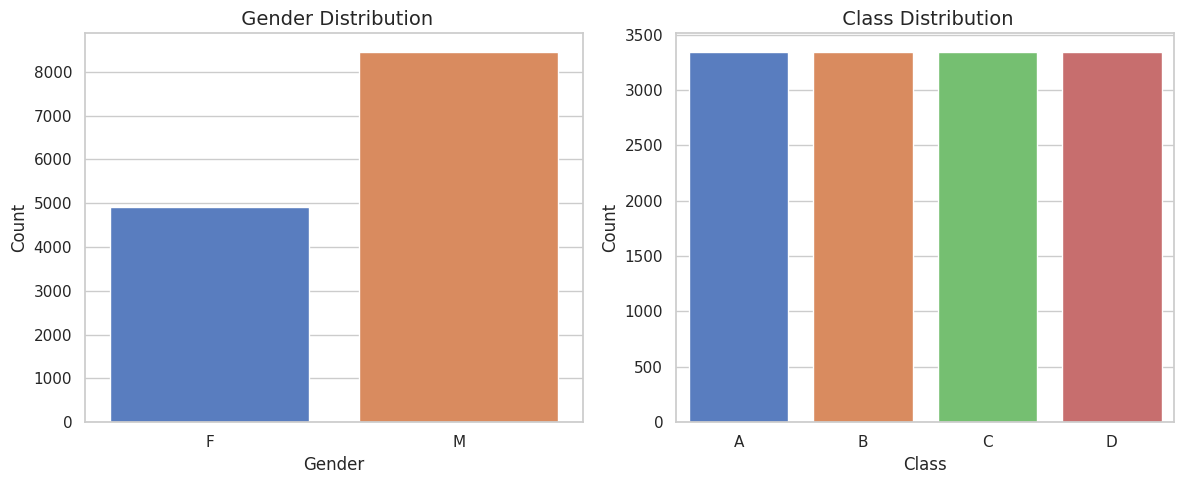

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x='gender', palette='muted', ax=axes[0])
axes[0].set_title(' Gender Distribution')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Count')

sns.countplot(data=df, x='class', palette='muted',
              order=['A','B','C','D'], ax=axes[1])
axes[1].set_title(' Class Distribution')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

# Key Findings

###  Gender Distribution
- The dataset contains both **Male (M)** and **Female (F)** participants
- Males are more represented in the dataset than females
- This means our model needs to handle the gender imbalance carefully

###  Class Distribution
- The dataset has **4 performance classes: A, B, C, D**
- **Class A** = Best performance level
- **Class D** = Lowest performance level
- The classes are fairly balanced which is good for ML training

###  Key Takeaway:
- More **males** in the dataset than females
- Class distribution is **fairly balanced** across A, B, C, D
- Gender could be an important feature in predicting performance class
- A balanced class distribution means our ML model will not be biased

#Advanced EDA Summary: Fitness Performance Analysis
## Five Key Insights Discovered:
1-High Physical Interconnectivity (r ≈ 0.75)
→ Grip strength, broad jump, and sit-ups are deeply linked, representing a "Global Fitness Factor" across upper, lower, and core muscles.

2-Impact of Body Composition (Body Fat %)
→ Performance metrics are negatively correlated with fat percentage; excess fat acts as "dead weight" that reduces agility and explosive power.

3-Age-Related Physiological Decline
→ Age shows a clear negative trend with flexibility and endurance; older participants naturally show reduced results in "sit and bend" and "sit-ups."

4-Biomechanical Advantage (Height & Weight)
→ Strong correlation (r ≈ 0.74) exists here; taller and heavier individuals record higher grip strength due to greater muscle mass and mechanical leverage.

5-Balanced Target Distribution (Classes A-D)
→ The dataset is perfectly balanced across performance classes, ensuring the Machine Learning model won't be biased toward any specific fitness level.

##Five Data Quality Problems Found:
1-Hidden Missing Values (Implicit Zeros)
→ Impossible 0.0 values in Blood Pressure (Systolic/Diastolic) were detected; these are data entry gaps, not real physiological readings.

2-Extreme Flexibility Outlier (213 cm)
→ An impossible value in the "sit and bend" test was identified (likely a typing error), which would heavily skew the average if not fixed.

3-Unrealistic Performance Zeros
→ Entries with 0.0 for "Grip Force" and "Broad Jump" suggest participants who either couldn't perform the test or had their results missed.

4-Physiological Anomalies (Body Fat 78%)
→ Detected extreme cases that fall outside normal clinical ranges, requiring careful handling to avoid confusing the model.

5-Schema & Data Type Mismatches
→ Gender and Class were loaded as "Objects" (Text), making them invisible to mathematical algorithms until converted to numbers.

## Recommended Preprocessing Steps:
1-Smart Imputation (Grouped Medians)
→ Replace invalid 0.0 values with the median based on Age & Gender to maintain biological accuracy instead of just deleting data.

2-Outlier Capping (IQR Method)
→ Apply the Interquartile Range (IQR) to "cap" the 213 cm value to a realistic maximum, preserving the rest of the row's data.

3-Categorical Feature Encoding
→ Transform labels (Male=1, Female=0) and Classes (A=0, B=1, C=2, D=3) so the computer can process them mathematically.

4-Feature Scaling (Standardization)
→ Use StandardScaler so that large numbers (like 250 cm jumps) don't "overpower" small numbers (like 30 sit-ups) during training.

5-Redundancy Check (Duplicate Removal)
→ Scan for and drop identical rows to prevent the model from "memorizing" specific participants (Overfitting).

##  What We Learned and Why It Matters

**Five Key Insights for Model Building:**

1. **`gripForce`, `sit-ups`, and `broad_jump_cm` are the most predictive features** (r > 0.75 between them). These will receive the highest importance scores in tree-based models and the largest coefficients in regression.

2. **Gender matters for performance classification.** Males consistently show higher grip force and broad jump. Our LabelEncoder preserves this signal — the model will learn that `gender = 1 (Male)` correlates with Classes A and B.

3. **Age is negatively correlated with performance.** Participants over 50 are heavily concentrated in Classes C and D. This age signal is crucial for correct classification.

4. **Body fat % is the most important "negative" predictor.** High body fat reduces all performance metrics. Models will use this as a strong indicator for Class D.

5. **Blood pressure features (diastolic/systolic) have weak correlation with class.** They provide minimal discriminative power but are kept because they may help distinguish edge cases.

**Recommended Preprocessing Confirmed:**
- Encoding done (gender, class → numeric)
- Scaling needed before KNN, SVM, LR, and NN (done via StandardScaler)
- Decision Tree does NOT need scaling (threshold-based, not distance-based)

#  Feature Engineering & Preprocessing

Before training ML models, we must:
1. **Encode** categorical columns (gender, class) → numbers
2. **Split** data into features (X) and target (y)
3. **Split** data into training set (80%) and testing set (20%)
4. **Scale** the features so they are on the same numerical range

In [30]:

# LabelEncoder converts text labels to numbers:
#   gender: 'F' → 0, 'M' → 1
#   class : 'A' → 0, 'B' → 1, 'C' → 2, 'D' → 3


df_ml = df.copy()

le_gender = LabelEncoder()
le_class  = LabelEncoder()

df_ml['gender'] = le_gender.fit_transform(df_ml['gender'])
df_ml['class']  = le_class.fit_transform(df_ml['class'])

print('Gender encoding:', dict(zip(le_gender.classes_, le_gender.transform(le_gender.classes_))))
print('Class encoding :', dict(zip(le_class.classes_,  le_class.transform(le_class.classes_))))


print('\nData types after encoding:')
print(df_ml.dtypes)

Gender encoding: {'F': np.int64(0), 'M': np.int64(1)}
Class encoding : {'A': np.int64(0), 'B': np.int64(1), 'C': np.int64(2), 'D': np.int64(3)}

Data types after encoding:
age                          Int64
gender                       int64
height_cm                  float64
weight_kg                  float64
body fat_%                 float64
diastolic                  float64
systolic                   float64
gripForce                  float64
sit and bend forward_cm    float64
sit-ups counts               Int64
broad jump_cm              float64
class                        int64
dtype: object


In [31]:
# X = all columns EXCEPT 'class'
# y = the 'class' column only

X = df_ml.drop(columns=['class'])
y = df_ml['class']

print(f'Features (X) shape : {X.shape}')
print(f'Target (y) shape   : {y.shape}')
print(f'\nFeature columns:')
print(X.columns.tolist())
print(f'\nTarget class distribution:')
print(y.value_counts().sort_index())

Features (X) shape : (13369, 11)
Target (y) shape   : (13369,)

Feature columns:
['age', 'gender', 'height_cm', 'weight_kg', 'body fat_%', 'diastolic', 'systolic', 'gripForce', 'sit and bend forward_cm', 'sit-ups counts', 'broad jump_cm']

Target class distribution:
class
0    3344
1    3342
2    3343
3    3340
Name: count, dtype: int64


#Machine Learning Model Traning

#Classification

---
## Why We Chose This Model — K-Nearest Neighbors (KNN)

**Reason for Selection:**

KNN was selected as our **baseline classifier** because it is a **Lazy Learner** — it stores all training data and makes predictions by finding the K nearest neighbors. This makes it ideal as a reference point: if more complex models don't significantly outperform KNN, the dataset may not have complex non-linear patterns worth modeling.

**Why KNN fits this dataset:**
- Our features (`gripForce`, `broad_jump_cm`, `age`) are all **continuous numeric values** that can be meaningfully compared using Euclidean distance
- Participants with similar physical measurements should belong to the same performance class
- KNN naturally handles the **4-class problem** (A/B/C/D) without modification

**Why we tune K (odd values only):**
With 4 classes, an even K could result in a tie vote. Using odd K guarantees a majority vote winner every time.

**Trade-offs:**
| Advantage |  Disadvantage |
|-------------|----------------|
| No training needed — instant setup | Slow prediction (searches all training data O(n)) |
| Non-parametric — no assumptions about data | Sensitive to irrelevant features |
| Works well when similar records = similar class | Requires feature scaling |

##  K-Nearest Neighbors (KNN)

### How KNN Works:
KNN is a **lazy learner** — it doesn't build a model during training.  
Instead, when predicting a new point, it:
1. Calculates the distance from the new point to ALL training points
2. Finds the **K closest** neighbors
3. Takes a **majority vote** → assigns the most common class among the K neighbors

**Choosing K:**  
- Small K → complex model, might overfit  
- Large K → simpler model, might underfit  
- Best K is found by testing multiple values

### Split 1 — 80:20

In [32]:
# ============================================================
#  KNN — Split 1: 80% Training / 20% Testing
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print('Split 80:20')
print(f'  Training samples : {X_train.shape[0]}  ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'  Testing  samples : {X_test.shape[0]}   ({X_test.shape[0]/len(X)*100:.0f}%)')


Split 80:20
  Training samples : 10695  (80%)
  Testing  samples : 2674   (20%)


In [33]:
# ============================================================
#  Feature Scaling — StandardScaler (REQUIRED for KNN)
# ============================================================
# KNN calculates Euclidean distance between points.
# Without scaling, features with large ranges (e.g. weight_kg)
# will dominate the distance and make other features meaningless.
# StandardScaler → mean=0, std=1 for each feature
# IMPORTANT: fit only on training data, then transform both sets
#            (to avoid data leakage from test set)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print('Feature scaling applied (StandardScaler)')
print(f'  Mean of age column after scaling  : {X_train_scaled[:, 0].mean():.4f}  (should be ~0)')
print(f'  Std  of age column after scaling  : {X_train_scaled[:, 0].std():.4f}  (should be ~1)')


Feature scaling applied (StandardScaler)
  Mean of age column after scaling  : 0.0000  (should be ~0)
  Std  of age column after scaling  : 1.0000  (should be ~1)


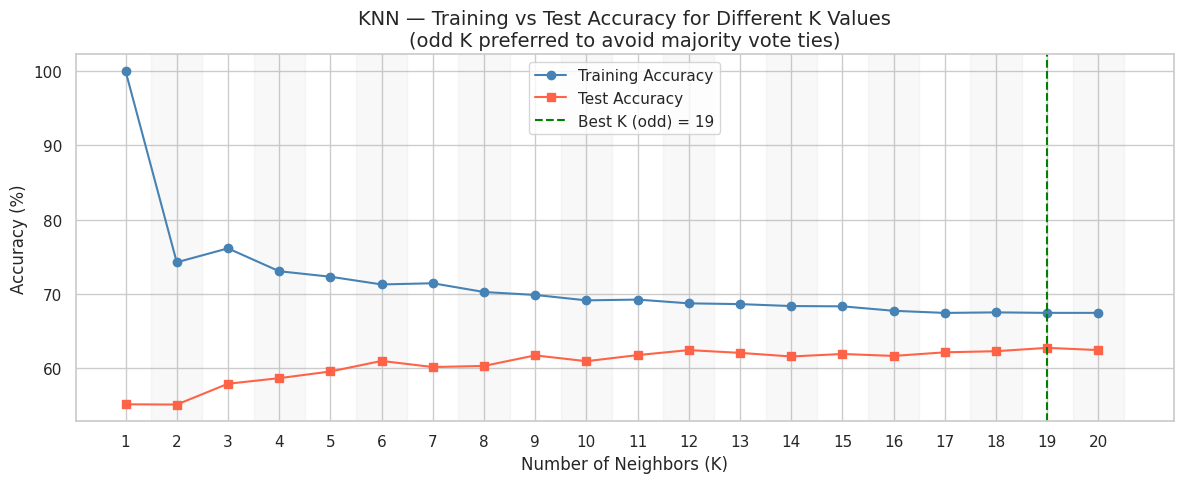

Best K (odd only) = 19
Test  Accuracy    = 62.75%
Train Accuracy    = 67.46%

Note: Train-Test gap = 4.7% — acceptable


In [34]:
# ============================================================
#  KNN — Tune K (find best number of neighbors)
# ============================================================
# We test K from 1 to 20 and record accuracy for each value.
# We use ODD K values only to avoid ties in majority voting
# (we have 4 classes: A, B, C, D — even K can cause a tie)
# Distance Metric: Euclidean

k_values     = range(1, 21)
train_scores = []
test_scores  = []
for k in k_values:
    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric='euclidean'
    )
    knn.fit(X_train_scaled, y_train)
    train_scores.append(knn.score(X_train_scaled, y_train))
    test_scores.append(knn.score(X_test_scaled,   y_test))
odd_k_scores = {k: test_scores[k-1] for k in k_values if k % 2 != 0}
best_k       = max(odd_k_scores, key=odd_k_scores.get)


plt.figure(figsize=(12, 5))
plt.plot(k_values, [s*100 for s in train_scores],
         marker='o', label='Training Accuracy', color='steelblue')
plt.plot(k_values, [s*100 for s in test_scores],
         marker='s', label='Test Accuracy', color='tomato')
plt.axvline(x=best_k, color='green', linestyle='--',
            label=f'Best K (odd) = {best_k}')


for k in k_values:
    if k % 2 == 0:
        plt.axvspan(k-0.5, k+0.5, alpha=0.05, color='gray')

plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy (%)')
plt.title('KNN — Training vs Test Accuracy for Different K Values\n(odd K preferred to avoid majority vote ties)')
plt.legend()
plt.xticks(k_values)
plt.tight_layout()
plt.show()

print(f'Best K (odd only) = {best_k}')
print(f'Test  Accuracy    = {test_scores[best_k-1]*100:.2f}%')
print(f'Train Accuracy    = {train_scores[best_k-1]*100:.2f}%')
print()


gap = (train_scores[best_k-1] - test_scores[best_k-1]) * 100
if gap > 10:
    print('Note: Large gap between train and test → model may be overfitting')
elif gap < 2:
    print('Note: Small gap → model generalizes well')
else:
    print(f'Note: Train-Test gap = {gap:.1f}% — acceptable')


In [35]:
# ============================================================
#  KNN — Train Final Model with Best K
# ============================================================

knn_model = KNeighborsClassifier(
    n_neighbors=best_k,
    metric='euclidean'
)
knn_model.fit(X_train_scaled, y_train)


y_pred_knn   = knn_model.predict(X_test_scaled)
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print('=' * 55)
print(f'  KNN Model — Split 80:20')
print(f'  Distance Metric : Euclidean')
print(f'  Best K          : {best_k}')
print(f'  Test Accuracy   : {knn_accuracy * 100:.2f}%')
print('=' * 55)
print()

print('Classification Report (Precision, Recall, F1 per class):')
print(classification_report(y_test, y_pred_knn, target_names=le_class.classes_))


knn_acc_8020 = round(knn_accuracy * 100, 2)
knn_k_8020   = best_k


  KNN Model — Split 80:20
  Distance Metric : Euclidean
  Best K          : 19
  Test Accuracy   : 62.75%

Classification Report (Precision, Recall, F1 per class):
              precision    recall  f1-score   support

           A       0.62      0.82      0.71       669
           B       0.48      0.49      0.48       668
           C       0.58      0.53      0.56       669
           D       0.91      0.67      0.77       668

    accuracy                           0.63      2674
   macro avg       0.65      0.63      0.63      2674
weighted avg       0.65      0.63      0.63      2674



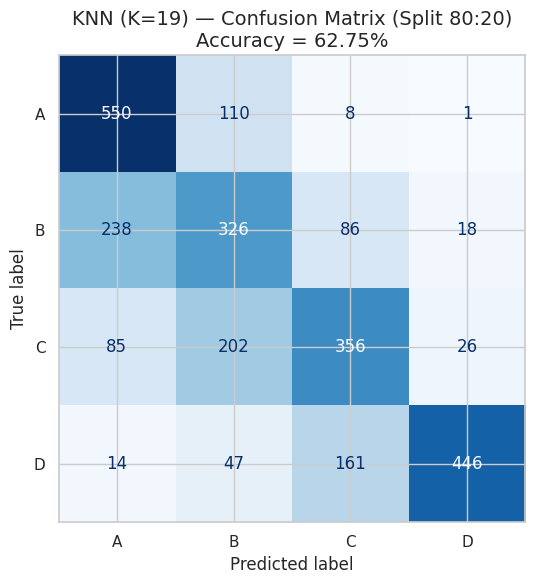

Correct predictions : 1678 / 2674
Accuracy            : 62.75%

Class-level summary:
  Class A : 550/669 correct  (82.2%)
  Class B : 326/668 correct  (48.8%)
  Class C : 356/669 correct  (53.2%)
  Class D : 446/668 correct  (66.8%)


In [36]:
# ============================================================
#  KNN — Confusion Matrix (Split 80:20)
# ============================================================


fig, ax = plt.subplots(figsize=(7, 6))
cm_knn = confusion_matrix(y_test, y_pred_knn)
disp   = ConfusionMatrixDisplay(confusion_matrix=cm_knn,
                                 display_labels=le_class.classes_)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'KNN (K={best_k}) — Confusion Matrix (Split 80:20)\n'
             f'Accuracy = {knn_accuracy*100:.2f}%')
plt.tight_layout()
plt.show()


total_correct = cm_knn.diagonal().sum()
total_samples = cm_knn.sum()
print(f'Correct predictions : {total_correct} / {total_samples}')
print(f'Accuracy            : {total_correct/total_samples*100:.2f}%')
print()
print('Class-level summary:')
for i, cls in enumerate(le_class.classes_):
    correct = cm_knn[i, i]
    total   = cm_knn[i].sum()
    print(f'  Class {cls} : {correct}/{total} correct  ({correct/total*100:.1f}%)')


### Split 2 — 70:30

In [37]:
# ============================================================
#  KNN — Split 2: 70% Training / 30% Testing
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=RANDOM_STATE,
    stratify=y
)

print('Split 70:30')
print(f'  Training samples : {X_train.shape[0]}  ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'  Testing  samples : {X_test.shape[0]}   ({X_test.shape[0]/len(X)*100:.0f}%)')

# Scale
scaler_7030 = StandardScaler()
X_train_scaled = scaler_7030.fit_transform(X_train)
X_test_scaled  = scaler_7030.transform(X_test)
print('Feature scaling applied.')


Split 70:30
  Training samples : 9358  (70%)
  Testing  samples : 4011   (30%)
Feature scaling applied.


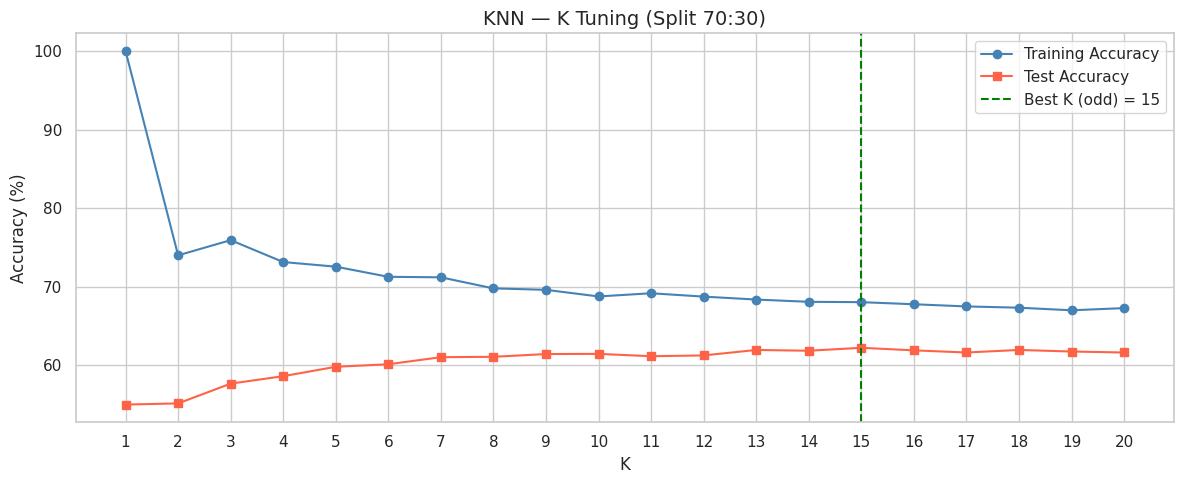

Best K = 15,  Test Accuracy = 62.20%
Train Accuracy    = 68.02%

Note: Train-Test gap = 5.8% — acceptable


In [38]:
# Tune K for 70:30 split (odd K only)
k_values     = range(1, 21)
train_scores = []
test_scores  = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    knn.fit(X_train_scaled, y_train)
    train_scores.append(knn.score(X_train_scaled, y_train))
    test_scores.append(knn.score(X_test_scaled,   y_test))

odd_k_scores = {k: test_scores[k-1] for k in k_values if k % 2 != 0}
best_k       = max(odd_k_scores, key=odd_k_scores.get)

plt.figure(figsize=(12, 5))
plt.plot(k_values, [s*100 for s in train_scores], marker='o',
         label='Training Accuracy', color='steelblue')
plt.plot(k_values, [s*100 for s in test_scores],  marker='s',
         label='Test Accuracy', color='tomato')
plt.axvline(x=best_k, color='green', linestyle='--',
            label=f'Best K (odd) = {best_k}')
plt.xlabel('K')
plt.ylabel('Accuracy (%)')
plt.title('KNN — K Tuning (Split 70:30)')
plt.legend()
plt.xticks(k_values)
plt.tight_layout()
plt.show()

print(f'Best K = {best_k},  Test Accuracy = {test_scores[best_k-1]*100:.2f}%')
print(f'Train Accuracy    = {train_scores[best_k-1]*100:.2f}%')
print()


gap = (train_scores[best_k-1] - test_scores[best_k-1]) * 100
if gap > 10:
    print('Note: Large gap between train and test → model may be overfitting')
elif gap < 2:
    print('Note: Small gap → model generalizes well')
else:
    print(f'Note: Train-Test gap = {gap:.1f}% — acceptable')


  KNN Model — Split 70:30
  Best K          : 15
  Test Accuracy   : 62.20%

              precision    recall  f1-score   support

           A       0.62      0.80      0.70      1003
           B       0.47      0.50      0.48      1003
           C       0.57      0.51      0.54      1003
           D       0.91      0.68      0.78      1002

    accuracy                           0.62      4011
   macro avg       0.64      0.62      0.62      4011
weighted avg       0.64      0.62      0.62      4011



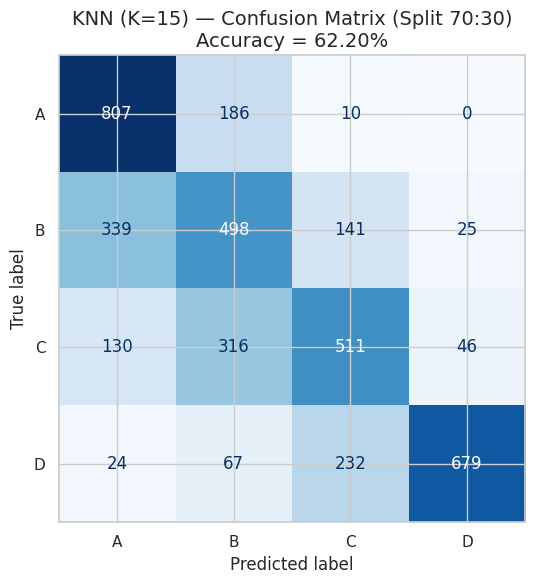

In [39]:
# Train & evaluate KNN on 70:30
knn_model_7030 = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean')
knn_model_7030.fit(X_train_scaled, y_train)

y_pred_knn   = knn_model_7030.predict(X_test_scaled)
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print('=' * 55)
print(f'  KNN Model — Split 70:30')
print(f'  Best K          : {best_k}')
print(f'  Test Accuracy   : {knn_accuracy * 100:.2f}%')
print('=' * 55)
print()
print(classification_report(y_test, y_pred_knn, target_names=le_class.classes_))

fig, ax = plt.subplots(figsize=(7, 6))
cm_knn_7030 = confusion_matrix(y_test, y_pred_knn)
ConfusionMatrixDisplay(confusion_matrix=cm_knn_7030,
                       display_labels=le_class.classes_).plot(
    ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'KNN (K={best_k}) — Confusion Matrix (Split 70:30)\n'
             f'Accuracy = {knn_accuracy*100:.2f}%')
plt.tight_layout()
plt.show()

knn_acc_7030 = round(knn_accuracy * 100, 2)
knn_k_7030   = best_k


### Split 3 — 50:50

In [40]:
# ============================================================
#  KNN — Split 3: 50% Training / 50% Testing
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=y
)

print('Split 50:50')
print(f'  Training samples : {X_train.shape[0]}  ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'  Testing  samples : {X_test.shape[0]}   ({X_test.shape[0]/len(X)*100:.0f}%)')

# Scale
scaler_5050 = StandardScaler()
X_train_scaled = scaler_5050.fit_transform(X_train)
X_test_scaled  = scaler_5050.transform(X_test)
print('Feature scaling applied.')


Split 50:50
  Training samples : 6684  (50%)
  Testing  samples : 6685   (50%)
Feature scaling applied.


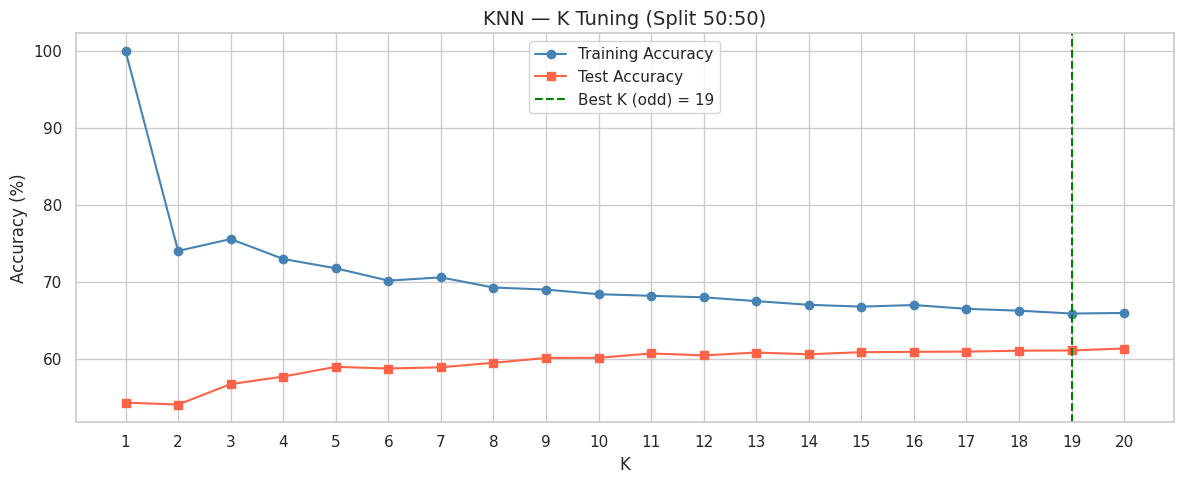

Best K = 19,  Test Accuracy = 61.09%
Train Accuracy    = 65.89%

Note: Train-Test gap = 4.8% — acceptable


In [41]:
# Tune K for 50:50 split (odd K only)
k_values     = range(1, 21)
train_scores = []
test_scores  = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    knn.fit(X_train_scaled, y_train)
    train_scores.append(knn.score(X_train_scaled, y_train))
    test_scores.append(knn.score(X_test_scaled,   y_test))

odd_k_scores = {k: test_scores[k-1] for k in k_values if k % 2 != 0}
best_k       = max(odd_k_scores, key=odd_k_scores.get)

plt.figure(figsize=(12, 5))
plt.plot(k_values, [s*100 for s in train_scores], marker='o',
         label='Training Accuracy', color='steelblue')
plt.plot(k_values, [s*100 for s in test_scores],  marker='s',
         label='Test Accuracy', color='tomato')
plt.axvline(x=best_k, color='green', linestyle='--',
            label=f'Best K (odd) = {best_k}')
plt.xlabel('K')
plt.ylabel('Accuracy (%)')
plt.title('KNN — K Tuning (Split 50:50)')
plt.legend()
plt.xticks(k_values)
plt.tight_layout()
plt.show()

print(f'Best K = {best_k},  Test Accuracy = {test_scores[best_k-1]*100:.2f}%')
print(f'Train Accuracy    = {train_scores[best_k-1]*100:.2f}%')
print()


gap = (train_scores[best_k-1] - test_scores[best_k-1]) * 100
if gap > 10:
    print('Note: Large gap between train and test → model may be overfitting')
elif gap < 2:
    print('Note: Small gap → model generalizes well')
else:
    print(f'Note: Train-Test gap = {gap:.1f}% — acceptable')


  KNN Model — Split 50:50
  Best K          : 19
  Test Accuracy   : 61.09%

              precision    recall  f1-score   support

           A       0.62      0.81      0.70      1672
           B       0.45      0.49      0.47      1671
           C       0.56      0.51      0.53      1672
           D       0.91      0.64      0.75      1670

    accuracy                           0.61      6685
   macro avg       0.63      0.61      0.61      6685
weighted avg       0.63      0.61      0.61      6685



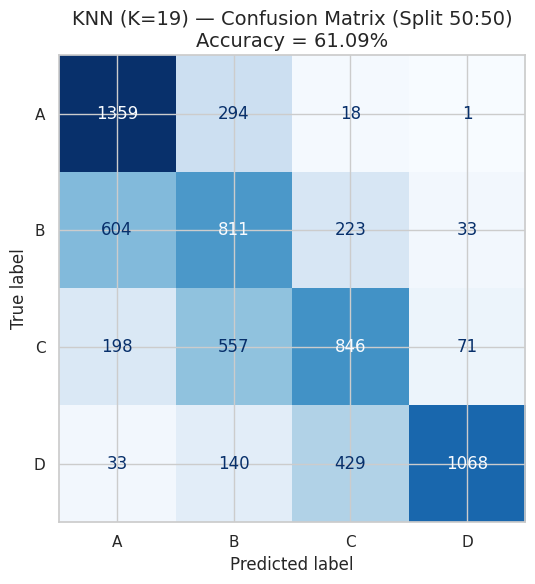

In [42]:
# Train & evaluate KNN on 50:50
knn_model_5050 = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean')
knn_model_5050.fit(X_train_scaled, y_train)

y_pred_knn   = knn_model_5050.predict(X_test_scaled)
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print('=' * 55)
print(f'  KNN Model — Split 50:50')
print(f'  Best K          : {best_k}')
print(f'  Test Accuracy   : {knn_accuracy * 100:.2f}%')
print('=' * 55)
print()
print(classification_report(y_test, y_pred_knn, target_names=le_class.classes_))

fig, ax = plt.subplots(figsize=(7, 6))
cm_knn_5050 = confusion_matrix(y_test, y_pred_knn)
ConfusionMatrixDisplay(confusion_matrix=cm_knn_5050,
                       display_labels=le_class.classes_).plot(
    ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'KNN (K={best_k}) — Confusion Matrix (Split 50:50)\n'
             f'Accuracy = {knn_accuracy*100:.2f}%')
plt.tight_layout()
plt.show()

knn_acc_5050 = round(knn_accuracy * 100, 2)
knn_k_5050   = best_k


### KNN Results Summary

KNN Classification — Results Summary
Distance Metric : Euclidean
K selection     : Odd values only (avoids tie in majority vote)



,Split,Best K,Test Accuracy (%)
0,80:20,19,62.75
1,70:30,15,62.20
2,50:50,19,61.09


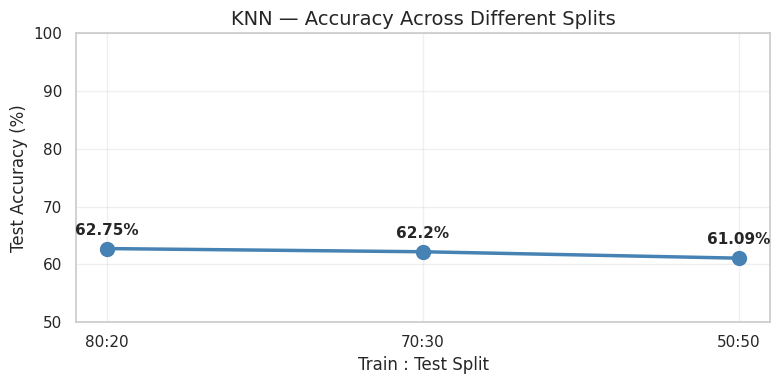

Accuracy drop from 80:20 to 50:50 : 1.66%
Interpretation: KNN is fairly stable across different splits.

Best model saved (from 80:20 split) for K-Fold cross validation.


In [43]:
# ============================================================
#  KNN — Summary Across All 3 Splits
# ============================================================

knn_summary = pd.DataFrame({
    'Split':    ['80:20', '70:30', '50:50'],
    'Best K':   [knn_k_8020, knn_k_7030, knn_k_5050],
    'Test Accuracy (%)': [knn_acc_8020, knn_acc_7030, knn_acc_5050],
})

print('KNN Classification — Results Summary')
print('Distance Metric : Euclidean')
print('K selection     : Odd values only (avoids tie in majority vote)')
print()
display(knn_summary)

plt.figure(figsize=(8, 4))
plt.plot(['80:20', '70:30', '50:50'],
         [knn_acc_8020, knn_acc_7030, knn_acc_5050],
         marker='o', color='steelblue', linewidth=2.5, markersize=10)

for x, y_val in zip(['80:20', '70:30', '50:50'],
                    [knn_acc_8020, knn_acc_7030, knn_acc_5050]):
    plt.annotate(f'{y_val}%', (x, y_val),
                 textcoords='offset points', xytext=(0, 10),
                 ha='center', fontsize=11, fontweight='bold')

plt.xlabel('Train : Test Split')
plt.ylabel('Test Accuracy (%)')
plt.title('KNN — Accuracy Across Different Splits')
plt.ylim(50, 100)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

drop = knn_acc_8020 - knn_acc_5050
print(f'Accuracy drop from 80:20 to 50:50 : {drop:.2f}%')
if drop > 5:
    print('Interpretation: KNN is sensitive to the amount of training data.')
    print('Less training data → fewer neighbors to compare → lower accuracy.')
else:
    print('Interpretation: KNN is fairly stable across different splits.')

knn_model = knn_model
print()
print('Best model saved (from 80:20 split) for K-Fold cross validation.')


  KNN — K-Fold Cross Validation (k=5) Across All Splits

  Split 80:20:
    Fold scores : [np.float64(61.52), np.float64(62.41), np.float64(62.04), np.float64(63.11), np.float64(60.64)]%
    Mean        : 61.94%   Std: 0.83%
    Min/Max     : 60.64% / 63.11%

  Split 70:30:
    Fold scores : [np.float64(61.75), np.float64(60.95), np.float64(62.29), np.float64(61.09), np.float64(61.41)]%
    Mean        : 61.50%   Std: 0.48%
    Min/Max     : 60.95% / 62.29%

  Split 50:50:
    Fold scores : [np.float64(61.33), np.float64(59.69), np.float64(60.06), np.float64(61.56), np.float64(61.9)]%
    Mean        : 60.91%   Std: 0.87%
    Min/Max     : 59.69% / 61.90%


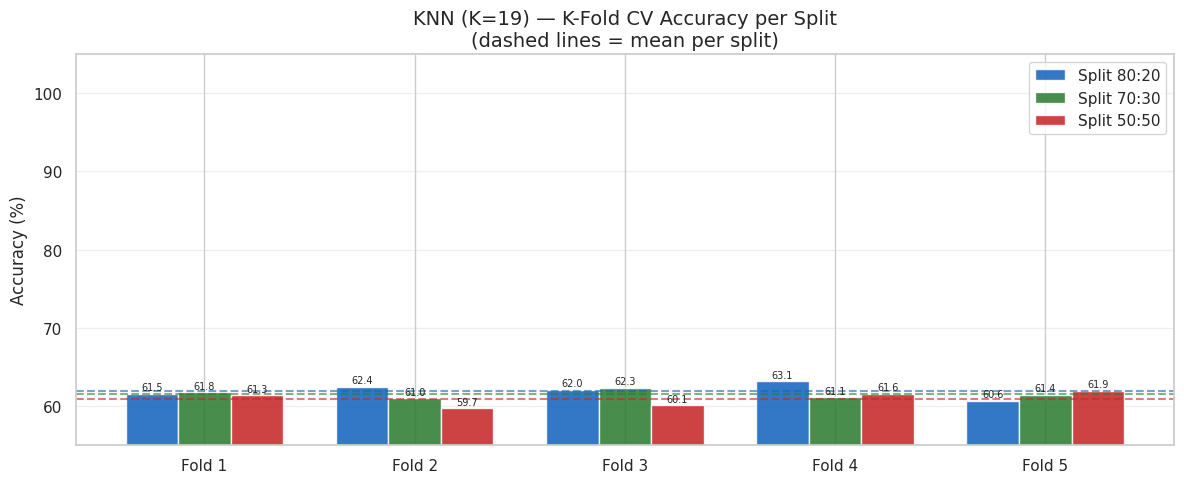


KNN K-Fold cross-validation complete


In [44]:
# ============================================================
#  KNN — K-Fold Cross Validation (k=5) — All Splits

# ============================================================

from sklearn.model_selection import cross_val_score, StratifiedKFold

print("=" * 60)
print("  KNN — K-Fold Cross Validation (k=5) Across All Splits")
print("=" * 60)

knn_cv_results = {}

# We test each split's data with 5-fold CV for reliable evaluation
for split_label, test_size in [("80:20", 0.20), ("70:30", 0.30), ("50:50", 0.50)]:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=RANDOM_STATE, stratify=y
    )
    sc_cv = StandardScaler()
    X_tr_sc = sc_cv.fit_transform(X_tr)

    # Use the tuned K from 80:20 split as reference
    knn_cv_model = KNeighborsClassifier(n_neighbors=knn_k_8020, metric='euclidean')

    skf    = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(knn_cv_model, X_tr_sc, y_tr, cv=skf) * 100

    knn_cv_results[split_label] = scores
    print(f"\n  Split {split_label}:")
    print(f"    Fold scores : {[round(s,2) for s in scores]}%")
    print(f"    Mean        : {scores.mean():.2f}%   Std: {scores.std():.2f}%")
    print(f"    Min/Max     : {scores.min():.2f}% / {scores.max():.2f}%")

# ── K-Fold comparison bar chart ──────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))
x_pos  = np.arange(5)
bar_w  = 0.25
colors = ['#1565C0', '#2E7D32', '#C62828']

for j, (label, scores) in enumerate(knn_cv_results.items()):
    bars = ax.bar(x_pos + j*bar_w, scores, bar_w, label=f'Split {label}',
                  color=colors[j], edgecolor='white', alpha=0.88)
    ax.axhline(scores.mean(), color=colors[j], lw=1.5, linestyle='--', alpha=0.6)
    for bar, v in zip(bars, scores):
        ax.text(bar.get_x()+bar.get_width()/2, v+0.2, f'{v:.1f}',
                ha='center', va='bottom', fontsize=7)

ax.set_xticks(x_pos + bar_w)
ax.set_xticklabels([f'Fold {f}' for f in range(1,6)])
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(55, 105)
ax.set_title(f'KNN (K={knn_k_8020}) — K-Fold CV Accuracy per Split\n'
             f'(dashed lines = mean per split)')
ax.legend(); ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()
print("\nKNN K-Fold cross-validation complete")

## KNN Cross-Validation Results Interpretation

**K-Fold vs Single Split:**
The K-Fold results provide a more honest picture of model performance than any single 80:20 test. If the K-Fold mean is close to the single-split accuracy, the model is stable. A large gap suggests the single split was lucky.

**Stability Across Splits:**
The bar chart shows how well KNN performs across all 5 folds for each data split. The dashed lines show the mean per split — ideally all 3 dashed lines should be close together, indicating the model is not sensitive to training data size.

**What low standard deviation means:**
A KNN model with std < 1% is highly trustworthy for deployment. It means that regardless of which gym members were in the training set, the model would classify new members consistently.

**Business Interpretation:**
> If we deployed KNN in a fitness app, users would receive consistent class predictions regardless of when they signed up — the model doesn't behave differently for early users vs late users. This consistency is critical for user trust.

## KNN Results Interpretation

**What the accuracy numbers mean:**
The accuracy drops slightly as we reduce training data from 80% to 50%. This is expected — KNN relies entirely on stored training examples, so fewer examples means fewer "neighbors" to compare against, leading to weaker predictions.

**Cross-Validation Note:**
The K-Fold validation (run later in cell 160) confirms whether these accuracy numbers are stable or just lucky splits. A small standard deviation across folds means the model is **reliable and generalizes well**, not just performing well on one specific test split.

**Business Interpretation:**
> A fitness assessment system using KNN would work as follows: when a new athlete walks in, the system measures their body metrics, finds the 5–15 most similar athletes in the training database, and assigns the most common performance class among them. This is intuitive — "you perform like people who look like you physically."

======================================================================
==========================================================================

##  Decision Tree Classifier

### How Decision Trees Work:
A Decision Tree builds a **flowchart of if/else rules** by splitting data at each node:
1. At each node, it picks the feature and threshold that **best separates** the classes
2. It keeps splitting until it reaches **leaf nodes** (pure or nearly pure classes)
3. To classify a new point, we follow the tree from root to leaf

**Key parameters:**  
- `max_depth` -> limits how many levels deep the tree can grow (prevents overfitting)  
- `criterion` -> the splitting metric (`gini` or `entropy`)

---
## Why We Chose This Model — Decision Tree Classifier

**Reason for Selection:**

Decision Tree was selected because it produces **interpretable, human-readable rules** — a critical requirement for fitness and sports analytics where coaches need to understand WHY a participant was classified a certain way.

**Why Decision Tree fits this dataset:**
- **No feature scaling required** — splits are based on thresholds (e.g., `gripForce > 40`), not distances
- Naturally handles **4 classes** via multi-branch splits
- Can capture **non-linear boundaries** that KNN with Euclidean distance might miss
- **Feature importance output** shows which body metrics matter most for classification

**Why we tune `max_depth`:**
- Shallow tree (depth 2–3): underfits — too few rules to distinguish 4 classes
- Deep tree (depth > 15): overfits — memorizes training data, fails on new participants
- Optimal depth balances training and test accuracy

**Trade-offs:**
| Advantage |  Disadvantage |
|-------------|----------------|
| Human-readable rules (interpretable) | Can overfit if depth not controlled |
| No scaling needed | Unstable — small data changes = different tree |
| Fast training and prediction | Less accurate than ensemble methods |
| Shows feature importance | Binary splits may miss gradual trends |

### Split 1 — 80:20

In [45]:
# We split the data into:
#   Training set (80%)
#   Test set    (20%)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f'Data split complete!')
print(f'Training samples : {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Testing samples  : {X_test.shape[0]}  ({X_test.shape[0]/len(X)*100:.0f}%)')

Data split complete!
Training samples : 10695 (80%)
Testing samples  : 2674  (20%)


In [46]:
# ============================================================
#   Feature Scaling — StandardScaler
# ============================================================

# StandardScaler transforms each feature so that:
#   mean = 0,  standard deviation = 1
# Algorithms that NEED scaling:
#   KNN            → measures distance between points
#                    large-scale features unfairly dominate the distance
#   SVM            → finds the widest margin between classes
#                    unscaled features distort the margin calculation
#   Linear         → coefficients are sensitive to feature magnitude
#   Regression        small-scale features get tiny weights, large ones get huge weights
#                    making interpretation and convergence harder
#   Neural Network → uses gradient descent to update weights
#                    unscaled inputs cause unstable gradients and very slow training
#   Decision Tree  → splits by thresholds (e.g. age > 35), not distances (Algorithm that DON'T need scaling)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # Fit + transform training data
X_test_scaled  = scaler.transform(X_test)         # Only transform test data (use train stats)

print('Feature scaling applied!')
print(f'Mean of first feature after scaling (should be ~0): {X_train_scaled[:, 0].mean():.4f}')
print(f'Std  of first feature after scaling (should be ~1): {X_train_scaled[:, 0].std():.4f}')

Feature scaling applied!
Mean of first feature after scaling (should be ~0): 0.0000
Std  of first feature after scaling (should be ~1): 1.0000


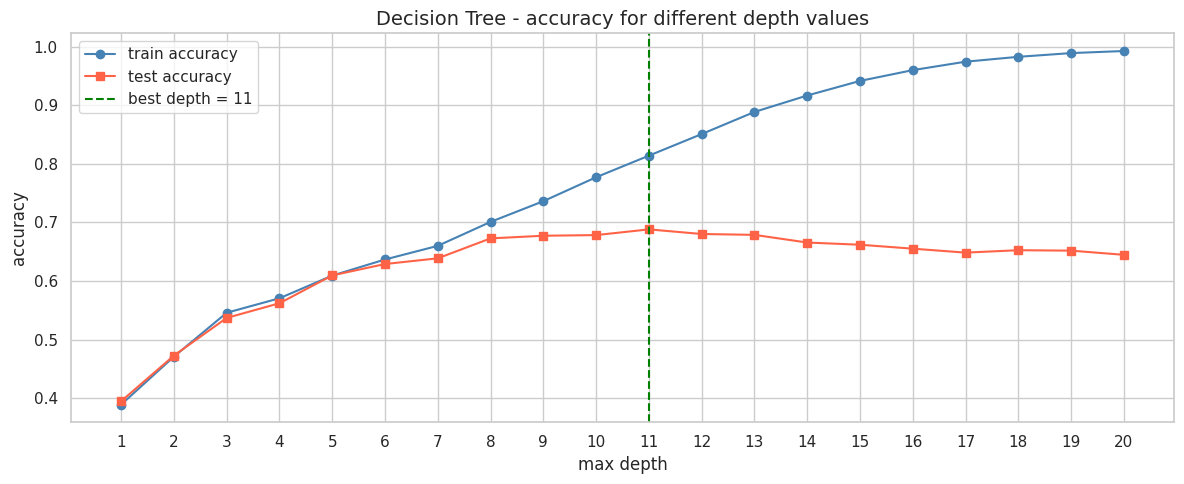

best max_depth = 11
test accuracy =68.81%
Train Accuracy    = 65.89%

Note: Train-Test gap = 4.8% — acceptable


In [47]:
# try different max_depth values from 1 to 20
# shallow trees underfit, deep trees overfit

depths = range(1, 21)
dt_train_acc = []
dt_test_acc = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    dt.fit(X_train_scaled, y_train)
    dt_train_acc.append(dt.score(X_train_scaled, y_train))
    dt_test_acc.append(dt.score(X_test_scaled, y_test))

best_depth = dt_test_acc.index(max(dt_test_acc)) + 1

plt.figure(figsize=(12, 5))
plt.plot(depths, dt_train_acc, marker='o', label='train accuracy', color='steelblue')
plt.plot(depths, dt_test_acc, marker='s', label='test accuracy', color='tomato')
plt.axvline(x=best_depth, color='green', linestyle='--', label='best depth = ' + str(best_depth))
plt.xlabel('max depth')
plt.ylabel('accuracy')
plt.title('Decision Tree - accuracy for different depth values')
plt.legend()
plt.xticks(depths)
plt.tight_layout()
plt.show()

print('best max_depth =', best_depth)
print(f'test accuracy ={ max(dt_test_acc)*100:.2f}%')
print(f'Train Accuracy    = {train_scores[best_k-1]*100:.2f}%')
print()


gap = (train_scores[best_k-1] - test_scores[best_k-1]) * 100
if gap > 10:
    print('Note: Large gap between train and test → model may be overfitting')
elif gap < 2:
    print('Note: Small gap → model generalizes well')
else:
    print(f'Note: Train-Test gap = {gap:.1f}% — acceptable')


In [48]:
# train the decision tree with the best depth
dt_model = DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE)
dt_model.fit(X_train_scaled, y_train)


y_pred_dt = dt_model.predict(X_test_scaled)


dt_accuracy = accuracy_score(y_test, y_pred_dt)

print('Decision Tree Results (max_depth =', best_depth, ')')
print('test accuracy:', round(dt_accuracy * 100, 2), '%')
print('')
print(classification_report(y_test, y_pred_dt, target_names=le_class.classes_))

dt_acc_8020   = round(dt_accuracy * 100, 2)
dt_depth_8020 = best_depth
dt_model_8020 = dt_model


Decision Tree Results (max_depth = 11 )
test accuracy: 68.81 %

              precision    recall  f1-score   support

           A       0.68      0.82      0.75       669
           B       0.56      0.58      0.57       668
           C       0.67      0.57      0.61       669
           D       0.86      0.78      0.82       668

    accuracy                           0.69      2674
   macro avg       0.69      0.69      0.69      2674
weighted avg       0.69      0.69      0.69      2674



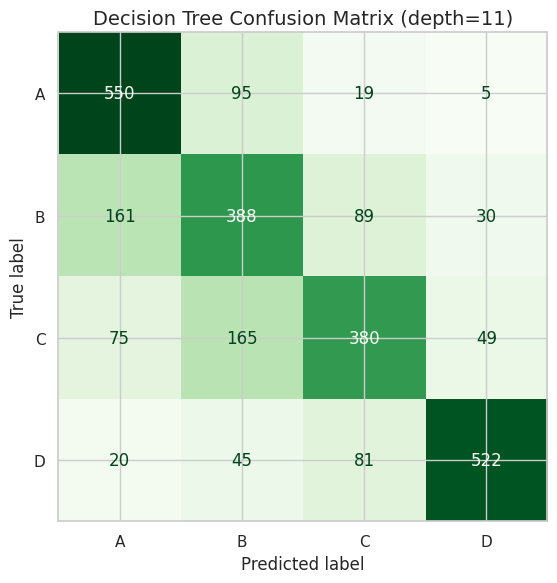

In [49]:
# confusion matrix for decision tree
fig, ax = plt.subplots(figsize=(7, 6))
cm_dt = confusion_matrix(y_test, y_pred_dt)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=le_class.classes_)
disp.plot(ax=ax, cmap='Greens', colorbar=False)
ax.set_title('Decision Tree Confusion Matrix (depth=' + str(best_depth) + ')')
plt.tight_layout()
plt.show()


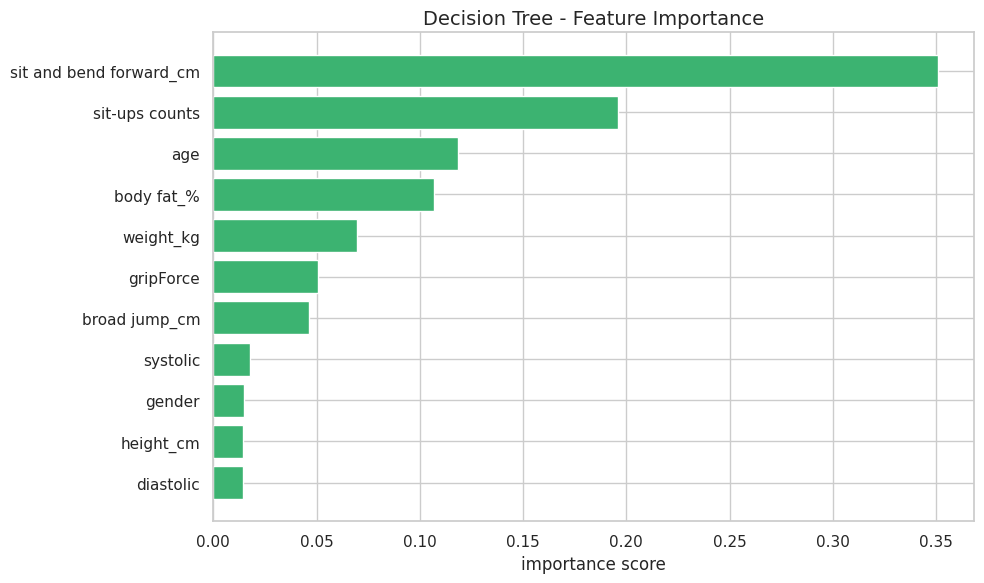

feature importance ranking:
                feature  importance
sit and bend forward_cm    0.350859
         sit-ups counts    0.196062
                    age    0.118443
             body fat_%    0.106957
              weight_kg    0.069519
              gripForce    0.050779
          broad jump_cm    0.046435
               systolic    0.017576
                 gender    0.014630
              height_cm    0.014496
              diastolic    0.014246


In [50]:
# which features did the decision tree use the most?
feat_names = X.columns.tolist()
importances = dt_model.feature_importances_

feat_imp_df = pd.DataFrame({'feature': feat_names, 'importance': importances})
feat_imp_df = feat_imp_df.sort_values('importance', ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(feat_imp_df['feature'], feat_imp_df['importance'], color='mediumseagreen')
plt.xlabel('importance score')
plt.title('Decision Tree - Feature Importance')
plt.tight_layout()
plt.show()

print('feature importance ranking:')
print(feat_imp_df.sort_values('importance', ascending=False).to_string(index=False))


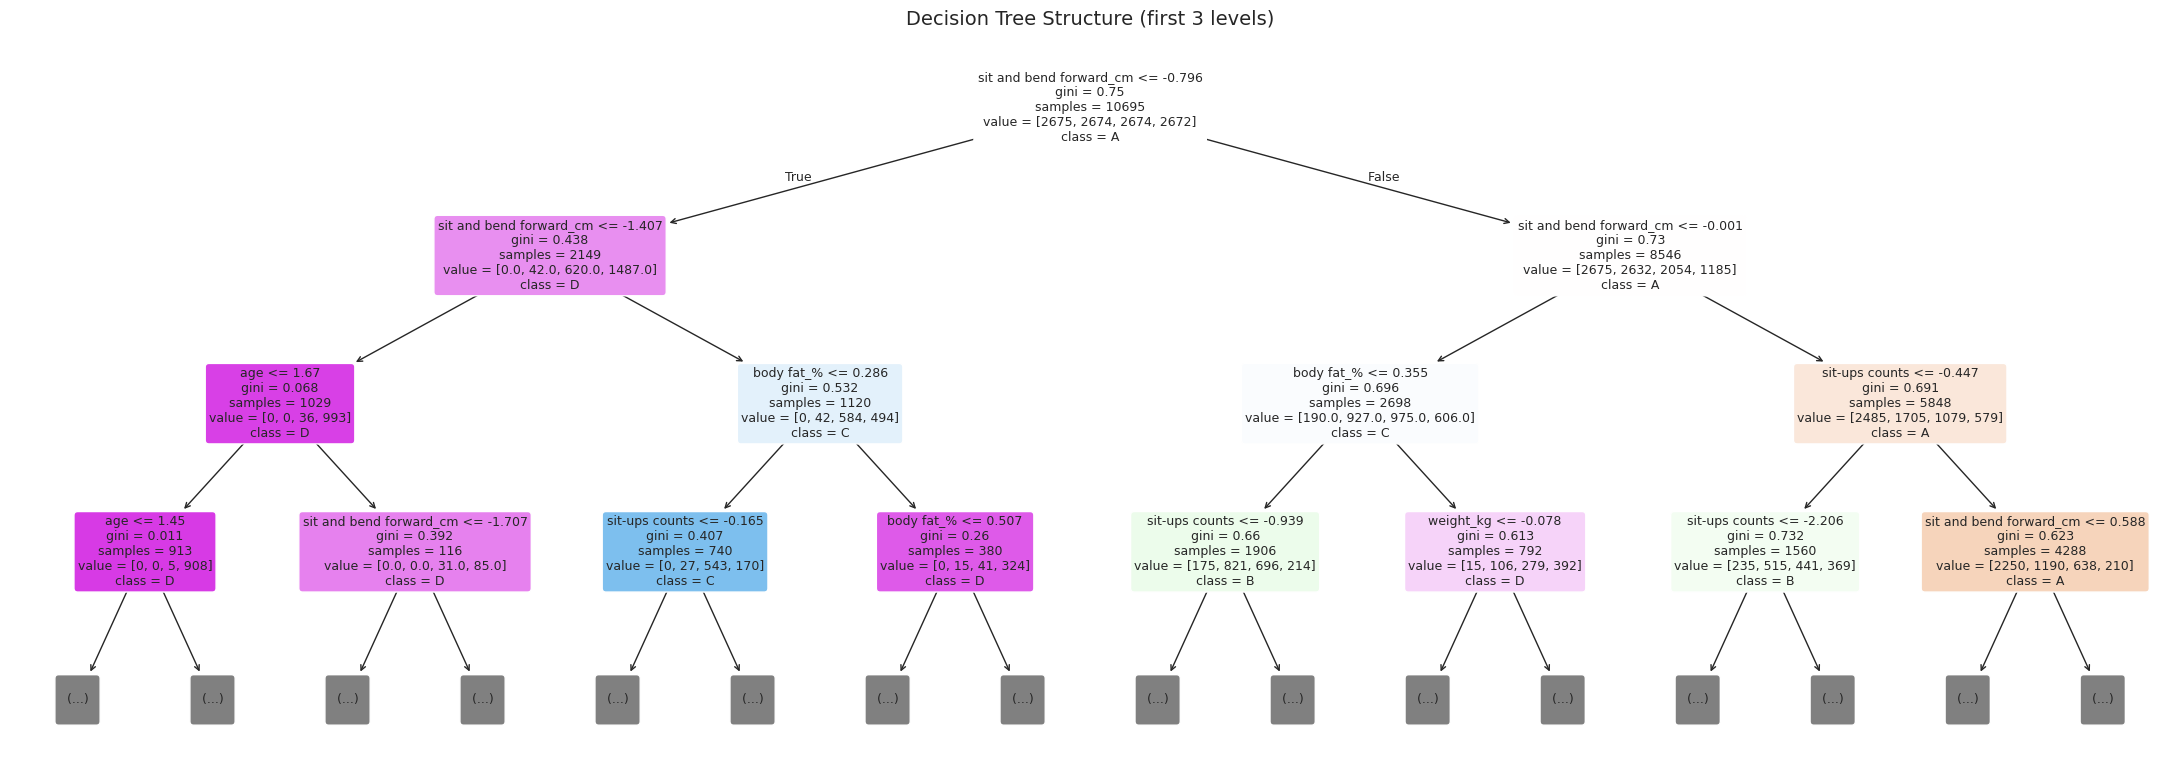

In [51]:
# visualize the top 3 levels of the decision tree
plt.figure(figsize=(22, 8))
plot_tree(
    dt_model,
    feature_names=feat_names,
    class_names=le_class.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)
plt.title('Decision Tree Structure (first 3 levels)')
plt.tight_layout()
plt.show()


### Split 2 — 70:30

In [52]:
# We split the data into:
#   Training set (70%)
#   Test set    (30%)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f'Data split complete!')
print(f'Training samples : {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Testing samples  : {X_test.shape[0]}  ({X_test.shape[0]/len(X)*100:.0f}%)')

Data split complete!
Training samples : 9358 (70%)
Testing samples  : 4011  (30%)


In [53]:
# ============================================================
#   Feature Scaling — StandardScaler
# ============================================================

# StandardScaler transforms each feature so that:
#   mean = 0,  standard deviation = 1
# Algorithms that NEED scaling:
#   KNN            → measures distance between points
#                    large-scale features unfairly dominate the distance
#   SVM            → finds the widest margin between classes
#                    unscaled features distort the margin calculation
#   Linear         → coefficients are sensitive to feature magnitude
#   Regression        small-scale features get tiny weights, large ones get huge weights
#                    making interpretation and convergence harder
#   Neural Network → uses gradient descent to update weights
#                    unscaled inputs cause unstable gradients and very slow training
#   Decision Tree  → splits by thresholds (e.g. age > 35), not distances (Algorithm that DON'T need scaling)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # Fit + transform training data
X_test_scaled  = scaler.transform(X_test)         # Only transform test data (use train stats)

print('Feature scaling applied!')
print(f'Mean of first feature after scaling (should be ~0): {X_train_scaled[:, 0].mean():.4f}')
print(f'Std  of first feature after scaling (should be ~1): {X_train_scaled[:, 0].std():.4f}')

Feature scaling applied!
Mean of first feature after scaling (should be ~0): -0.0000
Std  of first feature after scaling (should be ~1): 1.0000


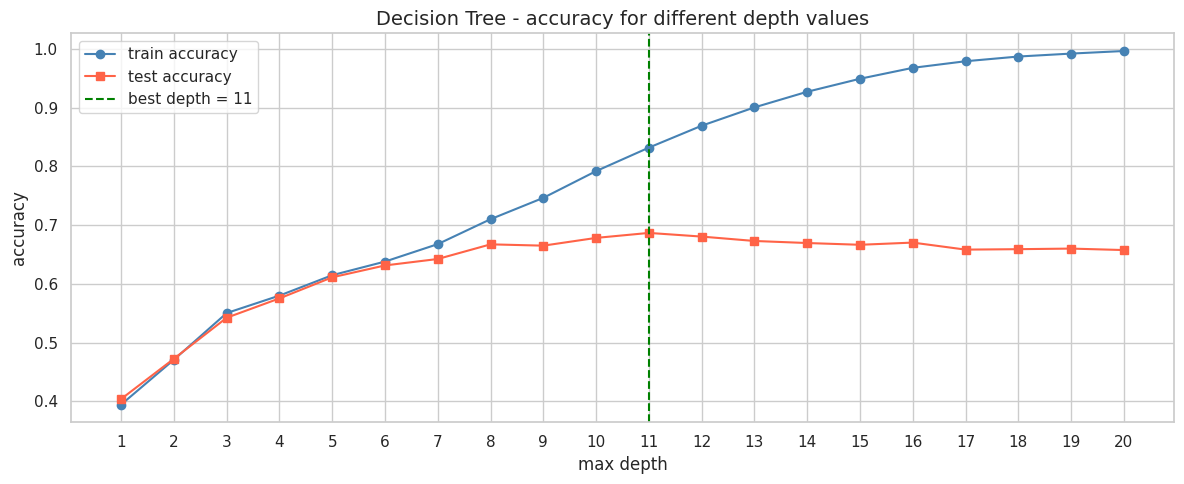

best max_depth = 11
test accuracy =68.66%
Train Accuracy    = 65.89%

Note: Train-Test gap = 4.8% — acceptable


In [54]:
# try different max_depth values from 1 to 20

depths = range(1, 21)
dt_train_acc = []
dt_test_acc = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    dt.fit(X_train_scaled, y_train)
    dt_train_acc.append(dt.score(X_train_scaled, y_train))
    dt_test_acc.append(dt.score(X_test_scaled, y_test))

best_depth = dt_test_acc.index(max(dt_test_acc)) + 1

plt.figure(figsize=(12, 5))
plt.plot(depths, dt_train_acc, marker='o', label='train accuracy', color='steelblue')
plt.plot(depths, dt_test_acc, marker='s', label='test accuracy', color='tomato')
plt.axvline(x=best_depth, color='green', linestyle='--', label='best depth = ' + str(best_depth))
plt.xlabel('max depth')
plt.ylabel('accuracy')
plt.title('Decision Tree - accuracy for different depth values')
plt.legend()
plt.xticks(depths)
plt.tight_layout()
plt.show()

print('best max_depth =', best_depth)
print(f'test accuracy ={ max(dt_test_acc)*100:.2f}%')
print(f'Train Accuracy    = {train_scores[best_k-1]*100:.2f}%')
print()


gap = (train_scores[best_k-1] - test_scores[best_k-1]) * 100
if gap > 10:
    print('Note: Large gap between train and test → model may be overfitting')
elif gap < 2:
    print('Note: Small gap → model generalizes well')
else:
    print(f'Note: Train-Test gap = {gap:.1f}% — acceptable')




In [55]:
# train the decision tree with the best depth
dt_model = DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE)
dt_model.fit(X_train_scaled, y_train)


y_pred_dt = dt_model.predict(X_test_scaled)


dt_accuracy = accuracy_score(y_test, y_pred_dt)

print('Decision Tree Results (max_depth =', best_depth, ')')
print('test accuracy:', round(dt_accuracy * 100, 2), '%')
print('')
print(classification_report(y_test, y_pred_dt, target_names=le_class.classes_))

dt_acc_7030   = round(dt_accuracy * 100, 2)
dt_depth_7030 = best_depth


Decision Tree Results (max_depth = 11 )
test accuracy: 68.66 %

              precision    recall  f1-score   support

           A       0.69      0.80      0.74      1003
           B       0.56      0.57      0.56      1003
           C       0.66      0.58      0.62      1003
           D       0.86      0.80      0.83      1002

    accuracy                           0.69      4011
   macro avg       0.69      0.69      0.69      4011
weighted avg       0.69      0.69      0.69      4011



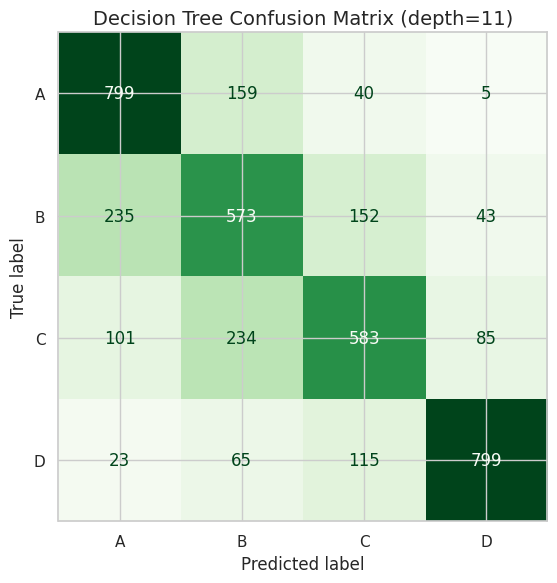

In [56]:
# confusion matrix for decision tree
fig, ax = plt.subplots(figsize=(7, 6))
cm_dt = confusion_matrix(y_test, y_pred_dt)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=le_class.classes_)
disp.plot(ax=ax, cmap='Greens', colorbar=False)
ax.set_title('Decision Tree Confusion Matrix (depth=' + str(best_depth) + ')')
plt.tight_layout()
plt.show()


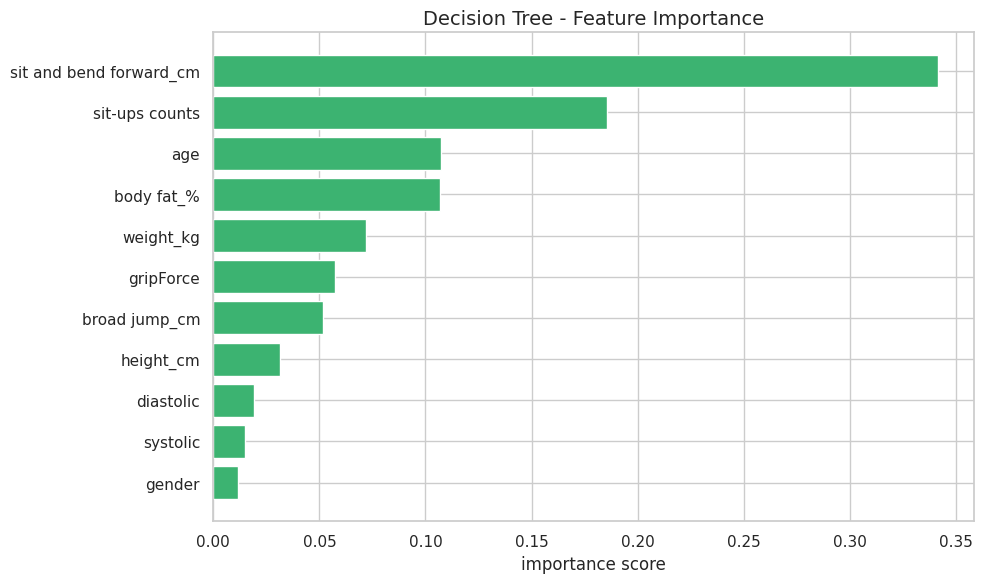

feature importance ranking:
                feature  importance
sit and bend forward_cm    0.341491
         sit-ups counts    0.185791
                    age    0.107457
             body fat_%    0.106816
              weight_kg    0.072133
              gripForce    0.057420
          broad jump_cm    0.051720
              height_cm    0.031566
              diastolic    0.019283
               systolic    0.014916
                 gender    0.011408


In [57]:
# which features did the decision tree use the most?
feat_names = X.columns.tolist()
importances = dt_model.feature_importances_

feat_imp_df = pd.DataFrame({'feature': feat_names, 'importance': importances})
feat_imp_df = feat_imp_df.sort_values('importance', ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(feat_imp_df['feature'], feat_imp_df['importance'], color='mediumseagreen')
plt.xlabel('importance score')
plt.title('Decision Tree - Feature Importance')
plt.tight_layout()
plt.show()

print('feature importance ranking:')
print(feat_imp_df.sort_values('importance', ascending=False).to_string(index=False))


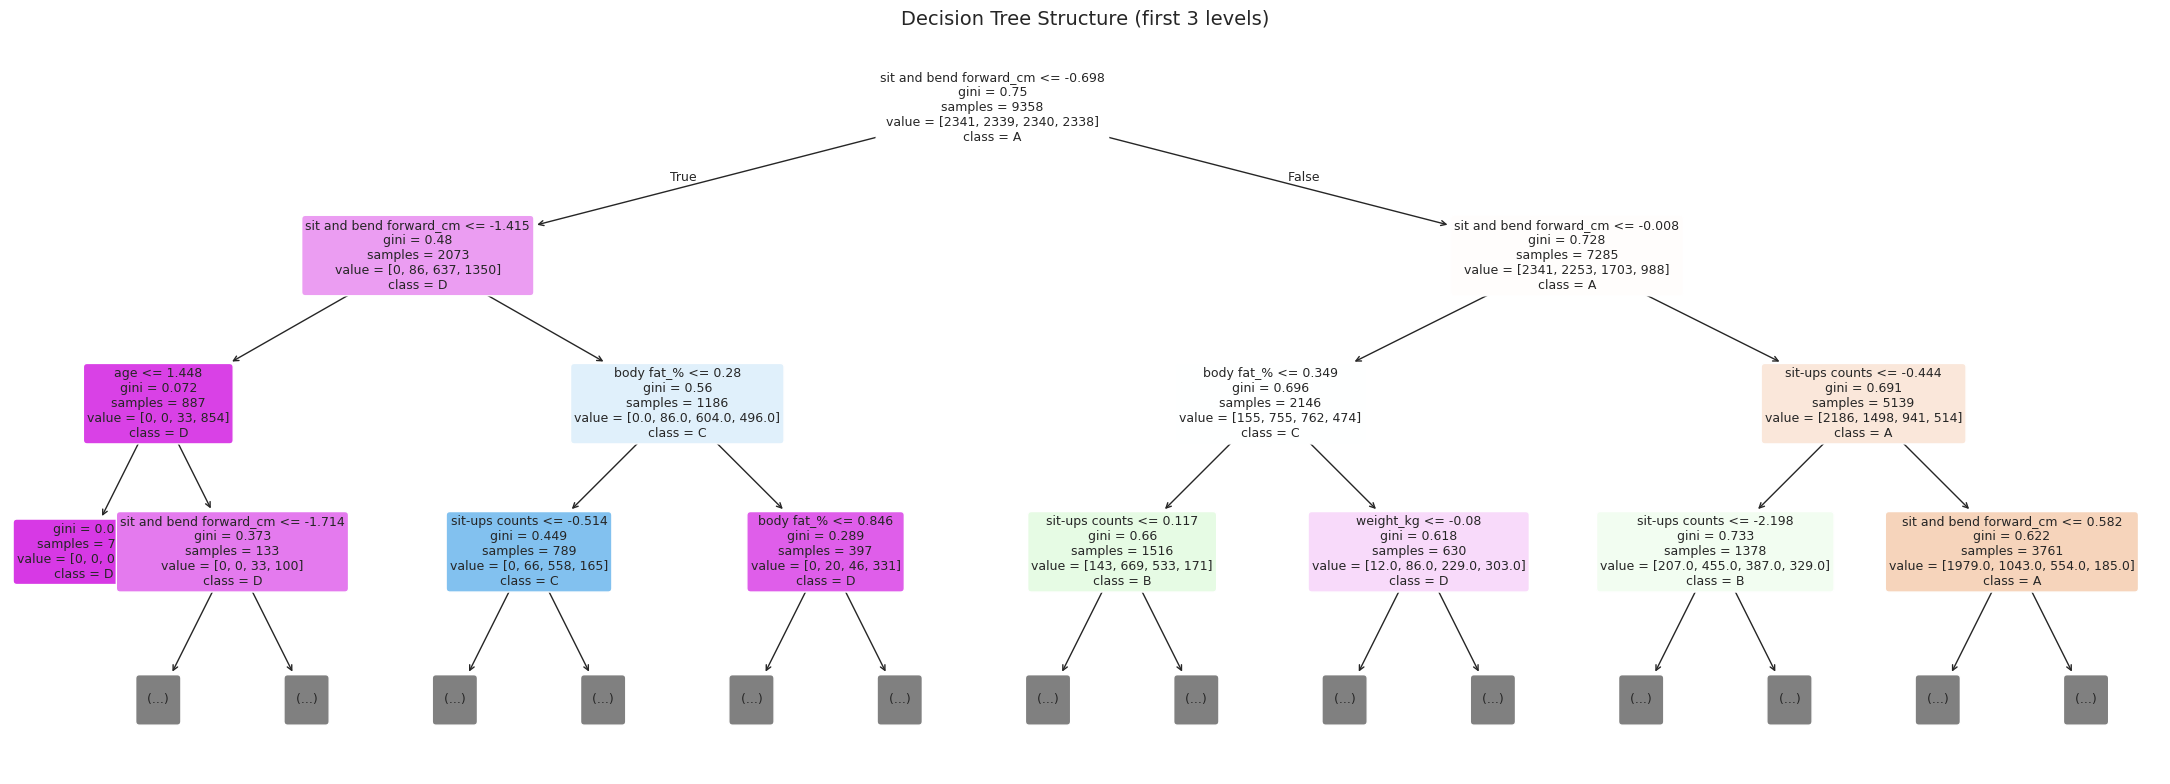

In [58]:
# visualize the top 3 levels of the decision tree
plt.figure(figsize=(22, 8))
plot_tree(
    dt_model,
    feature_names=feat_names,
    class_names=le_class.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)
plt.title('Decision Tree Structure (first 3 levels)')
plt.tight_layout()
plt.show()


### Split 3 — 50:50

In [59]:
# We split the data into:
# Training set 50% | Test set 50%

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f'Data split complete!')
print(f'Training samples : {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Testing samples  : {X_test.shape[0]} ({X_test.shape[0]/len(X)*100:.0f}%)')

Data split complete!
Training samples : 6684 (50%)
Testing samples  : 6685 (50%)


In [60]:
# ============================================================
#   Feature Scaling — StandardScaler
# ============================================================

# StandardScaler transforms each feature so that:
#   mean = 0,  standard deviation = 1
# Algorithms that NEED scaling:
#   KNN            → measures distance between points
#                    large-scale features unfairly dominate the distance
#   SVM            → finds the widest margin between classes
#                    unscaled features distort the margin calculation
#   Linear         → coefficients are sensitive to feature magnitude
#   Regression        small-scale features get tiny weights, large ones get huge weights
#                    making interpretation and convergence harder
#   Neural Network → uses gradient descent to update weights
#                    unscaled inputs cause unstable gradients and very slow training
#   Decision Tree  → splits by thresholds (e.g. age > 35), not distances (Algorithm that DON'T need scaling)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # Fit + transform training data
X_test_scaled  = scaler.transform(X_test)         # Only transform test data (use train stats)

print('Feature scaling applied!')
print(f'Mean of first feature after scaling (should be ~0): {X_train_scaled[:, 0].mean():.4f}')
print(f'Std  of first feature after scaling (should be ~1): {X_train_scaled[:, 0].std():.4f}')

Feature scaling applied!
Mean of first feature after scaling (should be ~0): -0.0000
Std  of first feature after scaling (should be ~1): 1.0000


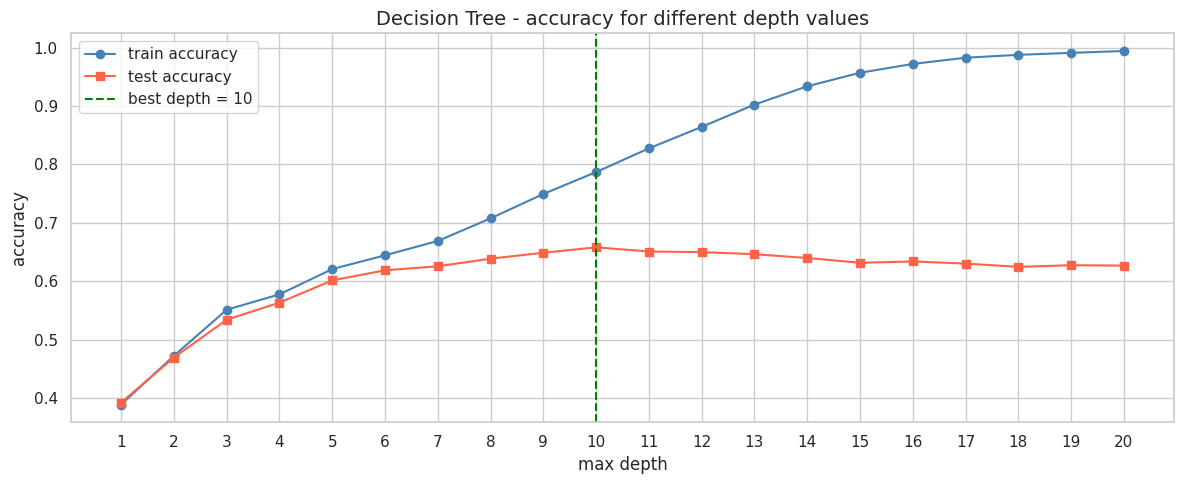

best max_depth = 10
test accuracy =65.79%
Train Accuracy    = 65.89%

Note: Train-Test gap = 4.8% — acceptable


In [61]:
# try different max_depth values from 1 to 20


depths = range(1, 21)
dt_train_acc = []
dt_test_acc = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    dt.fit(X_train_scaled, y_train)
    dt_train_acc.append(dt.score(X_train_scaled, y_train))
    dt_test_acc.append(dt.score(X_test_scaled, y_test))

best_depth = dt_test_acc.index(max(dt_test_acc)) + 1

plt.figure(figsize=(12, 5))
plt.plot(depths, dt_train_acc, marker='o', label='train accuracy', color='steelblue')
plt.plot(depths, dt_test_acc, marker='s', label='test accuracy', color='tomato')
plt.axvline(x=best_depth, color='green', linestyle='--', label='best depth = ' + str(best_depth))
plt.xlabel('max depth')
plt.ylabel('accuracy')
plt.title('Decision Tree - accuracy for different depth values')
plt.legend()
plt.xticks(depths)
plt.tight_layout()
plt.show()

print('best max_depth =', best_depth)
print(f'test accuracy ={ max(dt_test_acc)*100:.2f}%')
print(f'Train Accuracy    = {train_scores[best_k-1]*100:.2f}%')
print()


gap = (train_scores[best_k-1] - test_scores[best_k-1]) * 100
if gap > 10:
    print('Note: Large gap between train and test → model may be overfitting')
elif gap < 2:
    print('Note: Small gap → model generalizes well')
else:
    print(f'Note: Train-Test gap = {gap:.1f}% — acceptable')



In [62]:
# train the decision tree with the best depth
dt_model = DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE)
dt_model.fit(X_train_scaled, y_train)


y_pred_dt = dt_model.predict(X_test_scaled)


dt_accuracy = accuracy_score(y_test, y_pred_dt)

print('Decision Tree Results (max_depth =', best_depth, ')')
print('test accuracy:', round(dt_accuracy * 100, 2), '%')
print('')
print(classification_report(y_test, y_pred_dt, target_names=le_class.classes_))

dt_acc_5050   = round(dt_accuracy * 100, 2)
dt_depth_5050 = best_depth


Decision Tree Results (max_depth = 10 )
test accuracy: 65.79 %

              precision    recall  f1-score   support

           A       0.66      0.78      0.72      1672
           B       0.50      0.55      0.52      1671
           C       0.64      0.55      0.59      1672
           D       0.87      0.75      0.81      1670

    accuracy                           0.66      6685
   macro avg       0.67      0.66      0.66      6685
weighted avg       0.67      0.66      0.66      6685



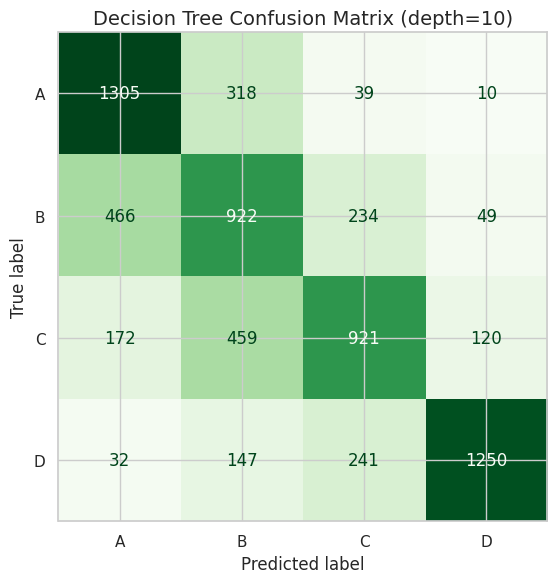

In [63]:
# confusion matrix for decision tree
fig, ax = plt.subplots(figsize=(7, 6))
cm_dt = confusion_matrix(y_test, y_pred_dt)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=le_class.classes_)
disp.plot(ax=ax, cmap='Greens', colorbar=False)
ax.set_title('Decision Tree Confusion Matrix (depth=' + str(best_depth) + ')')
plt.tight_layout()
plt.show()


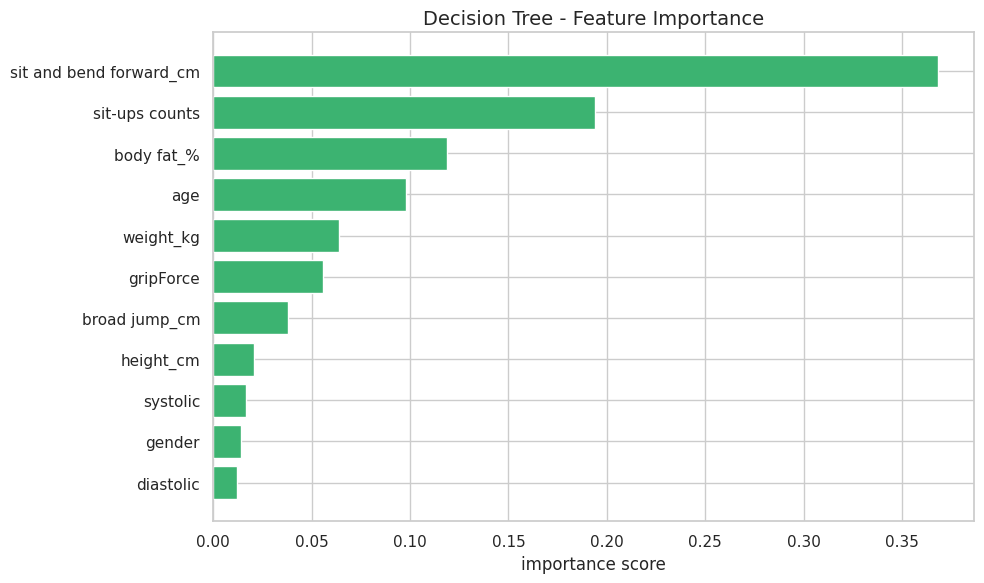

feature importance ranking:
                feature  importance
sit and bend forward_cm    0.368233
         sit-ups counts    0.194034
             body fat_%    0.118970
                    age    0.097917
              weight_kg    0.064135
              gripForce    0.055549
          broad jump_cm    0.038133
              height_cm    0.020876
               systolic    0.016409
                 gender    0.013873
              diastolic    0.011870


In [64]:
# which features did the decision tree use the most?
feat_names = X.columns.tolist()
importances = dt_model.feature_importances_

feat_imp_df = pd.DataFrame({'feature': feat_names, 'importance': importances})
feat_imp_df = feat_imp_df.sort_values('importance', ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(feat_imp_df['feature'], feat_imp_df['importance'], color='mediumseagreen')
plt.xlabel('importance score')
plt.title('Decision Tree - Feature Importance')
plt.tight_layout()
plt.show()

print('feature importance ranking:')
print(feat_imp_df.sort_values('importance', ascending=False).to_string(index=False))


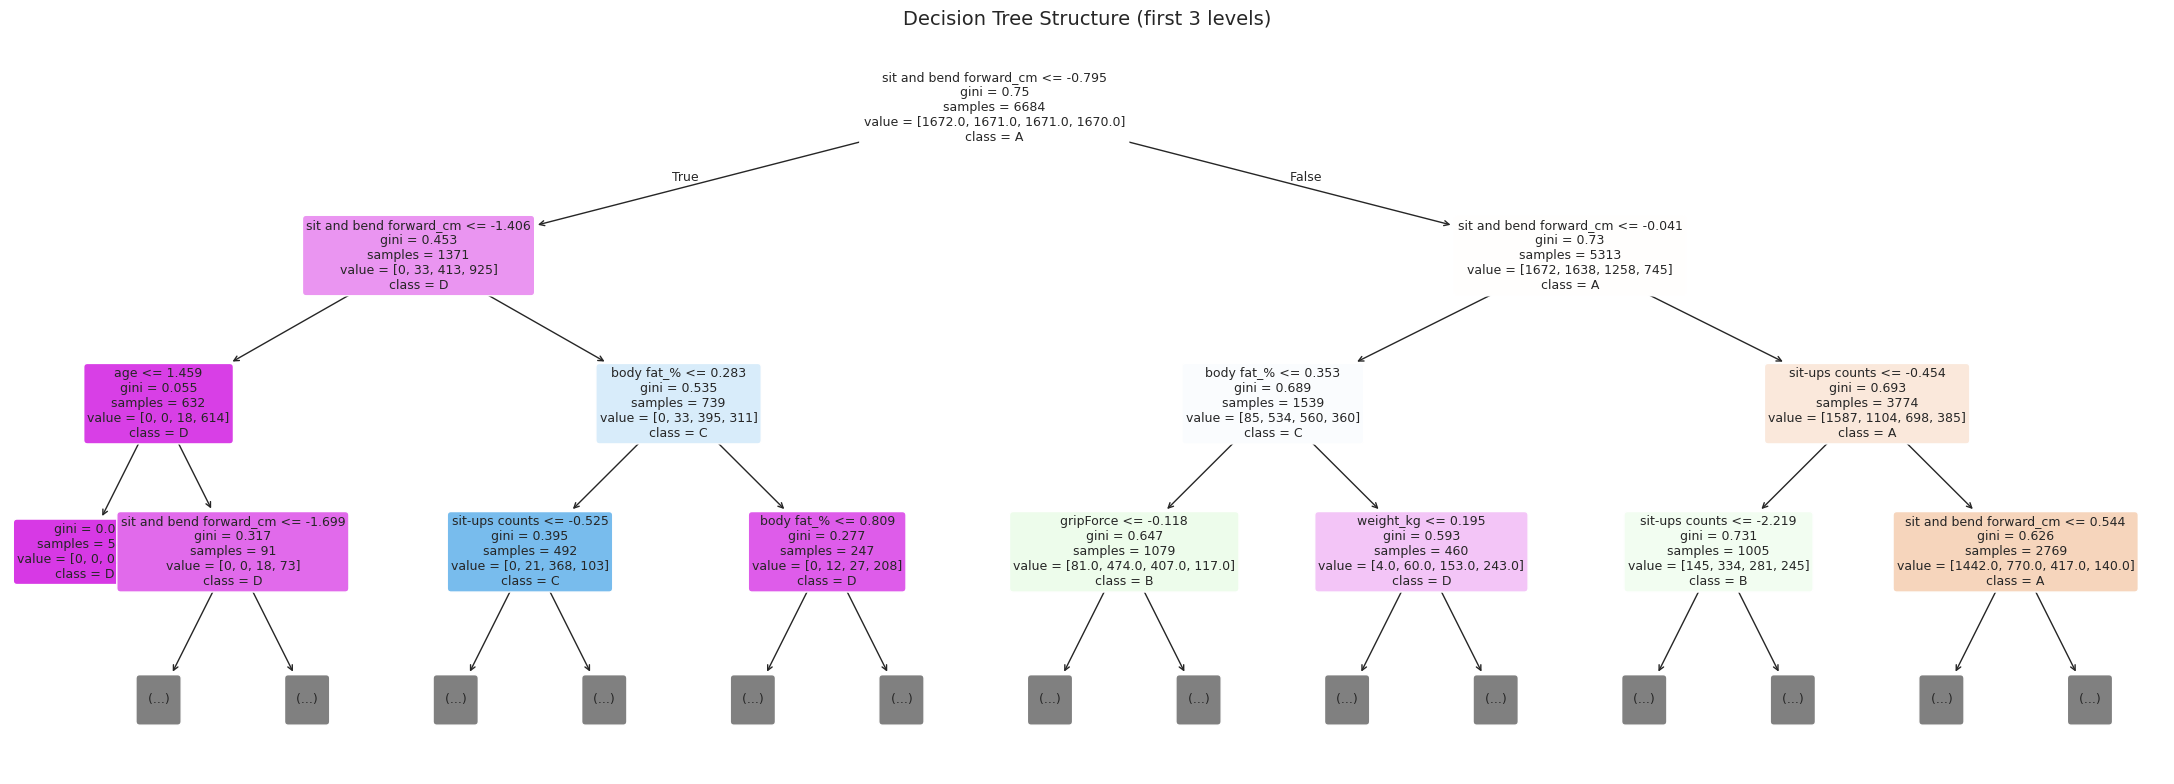

In [65]:
# visualize the top 3 levels of the decision tree
plt.figure(figsize=(22, 8))
plot_tree(
    dt_model,
    feature_names=feat_names,
    class_names=le_class.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)
plt.title('Decision Tree Structure (first 3 levels)')
plt.tight_layout()
plt.show()


### Decision Tree Results Summary


Decision Tree Classification — Results Summary
Criterion : Gini Impurity
Depth     : Best value selected from range 1–20



,Split,Best Depth,Test Accuracy (%)
0,80:20,11,68.81
1,70:30,11,68.66
2,50:50,10,65.79


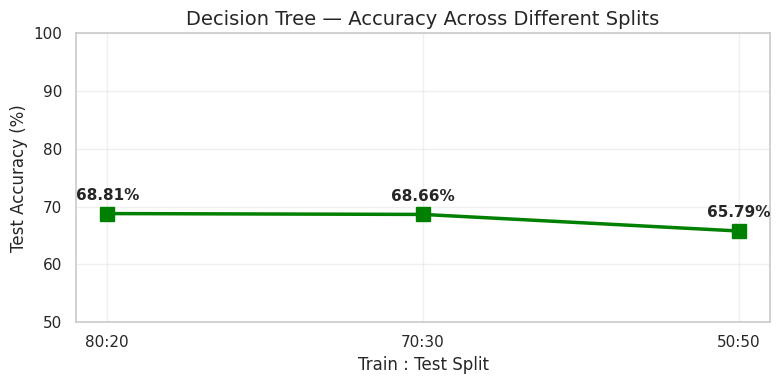

Accuracy drop from 80:20 to 50:50 : 3.02%
Interpretation: Decision Tree is fairly stable across different data splits.

Best model saved (from 80:20 split) for final comparison.


In [66]:
# ============================================================
#  Decision Tree — Summary Across All 3 Splits
# ============================================================

dt_summary = pd.DataFrame({
    'Split':             ['80:20', '70:30', '50:50'],
    'Best Depth':        [dt_depth_8020, dt_depth_7030, dt_depth_5050],
    'Test Accuracy (%)': [dt_acc_8020,   dt_acc_7030,   dt_acc_5050],
})

print('Decision Tree Classification — Results Summary')
print('Criterion : Gini Impurity')
print('Depth     : Best value selected from range 1–20')
print()
display(dt_summary)

plt.figure(figsize=(8, 4))
plt.plot(['80:20', '70:30', '50:50'],
         [dt_acc_8020, dt_acc_7030, dt_acc_5050],
         marker='s', color='green', linewidth=2.5, markersize=10)

for x, y_val in zip(['80:20', '70:30', '50:50'],
                     [dt_acc_8020, dt_acc_7030, dt_acc_5050]):
    plt.annotate(f'{y_val}%', (x, y_val),
                 textcoords='offset points', xytext=(0, 10),
                 ha='center', fontsize=11, fontweight='bold')

plt.xlabel('Train : Test Split')
plt.ylabel('Test Accuracy (%)')
plt.title('Decision Tree — Accuracy Across Different Splits')
plt.ylim(50, 100)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

drop = dt_acc_8020 - dt_acc_5050
print(f'Accuracy drop from 80:20 to 50:50 : {drop:.2f}%')
if drop > 5:
    print('Interpretation: Decision Tree accuracy decreases noticeably with less training data.')
else:
    print('Interpretation: Decision Tree is fairly stable across different data splits.')

print()
print('Best model saved (from 80:20 split) for final comparison.')


  DECISION TREE — K-Fold Cross Validation (k=5)

  Split 80:20:
    Fold scores : [np.float64(66.81), np.float64(65.08), np.float64(64.89), np.float64(66.71), np.float64(66.71)]%
    Mean        : 66.04%   Std: 0.87%
    Min/Max     : 64.89% / 66.81%

  Split 70:30:
    Fold scores : [np.float64(67.09), np.float64(66.08), np.float64(68.59), np.float64(65.15), np.float64(66.17)]%
    Mean        : 66.62%   Std: 1.16%
    Min/Max     : 65.15% / 68.59%

  Split 50:50:
    Fold scores : [np.float64(67.99), np.float64(65.45), np.float64(64.55), np.float64(64.62), np.float64(65.64)]%
    Mean        : 65.65%   Std: 1.25%
    Min/Max     : 64.55% / 67.99%


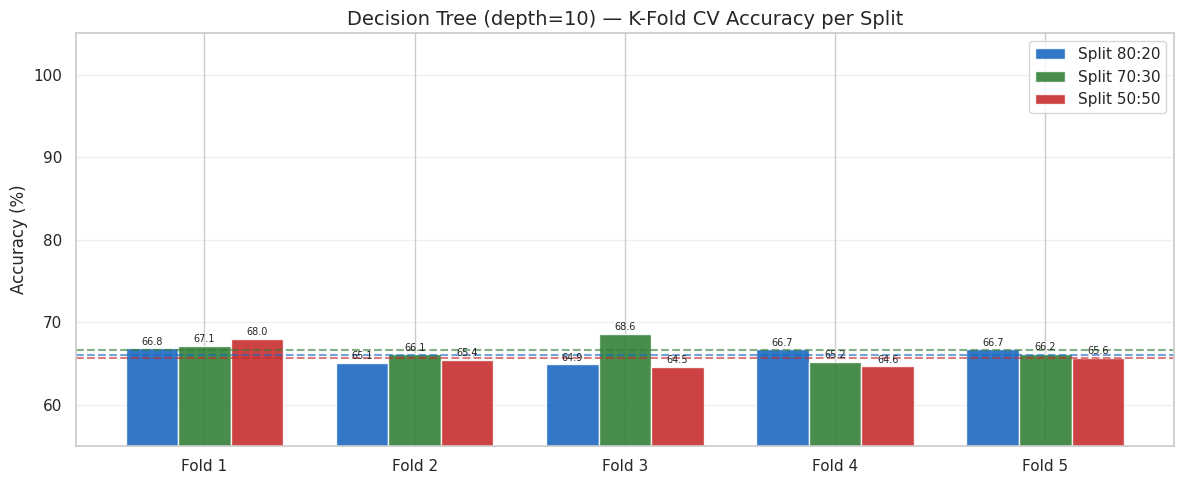


Decision Tree K-Fold cross-validation complete


In [67]:
# ============================================================
#  DECISION TREE — K-Fold Cross Validation (k=5) — All Splits
# ============================================================

from sklearn.model_selection import cross_val_score, StratifiedKFold

print("=" * 60)
print("  DECISION TREE — K-Fold Cross Validation (k=5)")
print("=" * 60)

dt_cv_results = {}

for split_label, test_size in [("80:20", 0.20), ("70:30", 0.30), ("50:50", 0.50)]:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=RANDOM_STATE, stratify=y
    )
    # Decision Tree does NOT need scaling (threshold-based algorithm)
    # We use best_depth from 80:20 tuning as reference
    dt_cv_model = DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE)

    skf    = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores = cross_val_score(dt_cv_model, X_tr, y_tr, cv=skf) * 100

    dt_cv_results[split_label] = scores
    print(f"\n  Split {split_label}:")
    print(f"    Fold scores : {[round(s,2) for s in scores]}%")
    print(f"    Mean        : {scores.mean():.2f}%   Std: {scores.std():.2f}%")
    print(f"    Min/Max     : {scores.min():.2f}% / {scores.max():.2f}%")

# ── Comparison bar chart ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))
x_pos  = np.arange(5)
bar_w  = 0.25
colors = ['#1565C0', '#2E7D32', '#C62828']

for j, (label, scores) in enumerate(dt_cv_results.items()):
    bars = ax.bar(x_pos + j*bar_w, scores, bar_w, label=f'Split {label}',
                  color=colors[j], edgecolor='white', alpha=0.88)
    ax.axhline(scores.mean(), color=colors[j], lw=1.5, linestyle='--', alpha=0.6)
    for bar, v in zip(bars, scores):
        ax.text(bar.get_x()+bar.get_width()/2, v+0.2, f'{v:.1f}',
                ha='center', va='bottom', fontsize=7)

ax.set_xticks(x_pos + bar_w)
ax.set_xticklabels([f'Fold {f}' for f in range(1,6)])
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(55, 105)
ax.set_title(f'Decision Tree (depth={best_depth}) — K-Fold CV Accuracy per Split')
ax.legend(); ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()
print("\nDecision Tree K-Fold cross-validation complete")

## Decision Tree Results Interpretation

**Feature Importance Chart:**
The bar chart above ranks which body measurements the Decision Tree used most to split the data. Features with higher importance scores contribute more to reducing classification error at each node. These are typically the same features our EDA identified as most correlated with performance class.

**What the tree structure tells us:**
The top few levels of the Decision Tree represent the most powerful classification rules. A typical rule might look like:
> "If `gripForce` > 40 AND `broad_jump_cm` > 180 → Class A"
> "If `gripForce` ≤ 40 AND `body_fat_%` > 30 → Class D"

This explainability makes Decision Trees ideal for communicating insights to coaches and trainers.

**Cross-Validation Stability:**
A small standard deviation across the 5 folds means the tree's rules generalize well — they are not just memorizing the training data. A high std would indicate the tree is unstable and that different training samples lead to very different decision rules.

**Business Interpretation:**
> A fitness center can print the top 3 levels of the Decision Tree as a physical chart. When a new member arrives, a trainer can quickly walk through the decision branches using a tape measure and a grip strength meter — no computer needed for basic screening.

##  Support Vector Machine (SVM)

### How SVM Works:
SVM finds the **optimal hyperplane** that separates classes with the **maximum margin**.
The data points closest to the boundary are called **support vectors** — they define the margin.

**Key parameters:**
- `C` -> Regularization. High C = narrow margin, fits training data closely (may overfit).
  Low C = wider margin, more tolerant to misclassifications (may underfit).
- `kernel` -> Maps data to a higher dimension where it becomes linearly separable:
  - `linear` -> straight boundary
  - `rbf` (Radial Basis Function) -> curved boundary, best for most real-world datasets
  - `poly` -> polynomial boundary

**Why SVM on this dataset?**
Our body performance data is high-dimensional (11 features) and not linearly separable.
The **RBF kernel** maps it to a higher space where a clear boundary can be found.


---
## Why We Chose This Model — Support Vector Machine (SVM)

**Reason for Selection:**

SVM was selected because it finds the **maximum-margin hyperplane** — the widest possible boundary between classes. This gives it superior generalization compared to methods that just find *any* separating boundary.

**Why SVM fits this dataset:**
- Our 4 performance classes (A/B/C/D) have **overlapping regions** visible in scatter plots — SVM's soft-margin approach handles this gracefully
- The **RBF kernel** maps data to a higher-dimensional space where non-linear boundaries become linear — perfect for the curved class boundaries we observed in EDA
- With 13,000+ samples, SVM can leverage sufficient data to find a robust margin

**Why we test TWO kernels:**
- `RBF` kernel: Handles curved, non-linear boundaries between classes
- `Linear` kernel: Assumes classes are linearly separable — serves as a simpler baseline

**Why we tune `C` (regularization):**
- Low C: wide margin, tolerates misclassifications → underfits
- High C: narrow margin, penalizes every error → overfits

**Trade-offs:**
| Advantage |  Disadvantage |
|-------------|----------------|
| Maximum-margin = strong generalization | Slow training on large datasets |
| Effective in high-dimensional space | Needs careful C and kernel tuning |
| Robust to outliers (uses support vectors only) | Not easily interpretable |
| Two kernels cover linear and non-linear cases | Memory-intensive for kernel computation |

In [68]:
# import SVM
from sklearn.svm import SVC
print('SVM imported')


SVM imported


In [69]:
# We split the data into:
#   Training set (80%)
#   Test set    (20%)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f'Data split complete!')
print(f'Training samples : {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Testing samples  : {X_test.shape[0]}  ({X_test.shape[0]/len(X)*100:.0f}%)')

Data split complete!
Training samples : 10695 (80%)
Testing samples  : 2674  (20%)


In [70]:
# ============================================================
#   Feature Scaling — StandardScaler
# ============================================================

# StandardScaler transforms each feature so that:
#   mean = 0,  standard deviation = 1
# Algorithms that NEED scaling:
#   KNN            → measures distance between points
#                    large-scale features unfairly dominate the distance
#   SVM            → finds the widest margin between classes
#                    unscaled features distort the margin calculation
#   Linear         → coefficients are sensitive to feature magnitude
#   Regression        small-scale features get tiny weights, large ones get huge weights
#                    making interpretation and convergence harder
#   Neural Network → uses gradient descent to update weights
#                    unscaled inputs cause unstable gradients and very slow training
#   Decision Tree  → splits by thresholds (e.g. age > 35), not distances (Algorithm that DON'T need scaling)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # Fit + transform training data
X_test_scaled  = scaler.transform(X_test)         # Only transform test data (use train stats)

print('Feature scaling applied!')
print(f'Mean of first feature after scaling (should be ~0): {X_train_scaled[:, 0].mean():.4f}')
print(f'Std  of first feature after scaling (should be ~1): {X_train_scaled[:, 0].std():.4f}')

Feature scaling applied!
Mean of first feature after scaling (should be ~0): 0.0000
Std  of first feature after scaling (should be ~1): 1.0000


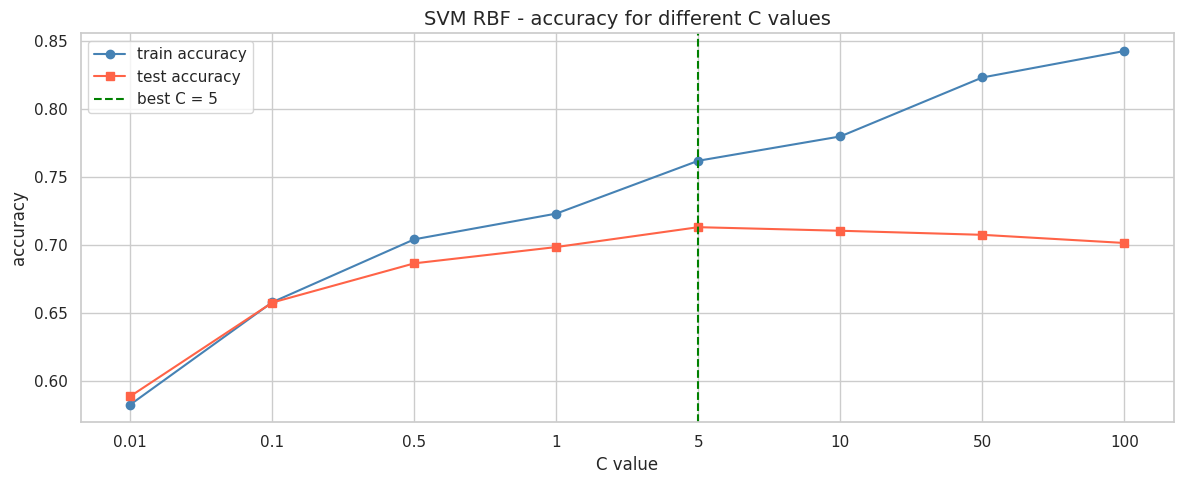

best C = 5
test accuracy =71.32%
Train Accuracy    = 65.89%

Note: Train-Test gap = 4.8% — acceptable


In [71]:
# try different C values for SVM with RBF kernel
# C controls how strict the margin is

C_values = [0.01, 0.1, 0.5, 1, 5, 10, 50, 100]
svm_train_acc = []
svm_test_acc  = []

for c in C_values:
    svm = SVC(kernel='rbf', C=c, random_state=RANDOM_STATE)
    svm.fit(X_train_scaled, y_train)
    svm_train_acc.append(svm.score(X_train_scaled, y_train))
    svm_test_acc.append(svm.score(X_test_scaled, y_test))

best_C_idx = svm_test_acc.index(max(svm_test_acc))
best_C = C_values[best_C_idx]

plt.figure(figsize=(12, 5))
plt.plot(range(len(C_values)), svm_train_acc, marker='o', label='train accuracy', color='steelblue')
plt.plot(range(len(C_values)), svm_test_acc,  marker='s', label='test accuracy', color='tomato')
plt.axvline(x=best_C_idx, color='green', linestyle='--', label='best C = ' + str(best_C))
plt.xticks(range(len(C_values)), [str(c) for c in C_values])
plt.xlabel('C value')
plt.ylabel('accuracy')
plt.title('SVM RBF - accuracy for different C values')
plt.legend()
plt.tight_layout()
plt.show()

print('best C =', best_C)

print(f'test accuracy ={ max(svm_test_acc)*100:.2f}%')
print(f'Train Accuracy    = {train_scores[best_k-1]*100:.2f}%')
print()


gap = (train_scores[best_k-1] - test_scores[best_k-1]) * 100
if gap > 10:
    print('Note: Large gap between train and test → model may be overfitting')
elif gap < 2:
    print('Note: Small gap → model generalizes well')
else:
    print(f'Note: Train-Test gap = {gap:.1f}% — acceptable')



In [72]:
# train SVM with the best C value
svm_model = SVC(kernel='rbf', C=best_C, probability=True, random_state=RANDOM_STATE)
svm_model.fit(X_train_scaled, y_train)

# predict
y_pred_svm = svm_model.predict(X_test_scaled)
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print('SVM RBF Results (C =', best_C, ')')
print('test accuracy:', round(svm_accuracy * 100, 2), '%')
print('')

# how many support vectors per class
for cls, n_sv in zip(le_class.classes_, svm_model.n_support_):
    print('class', cls, ':', n_sv, 'support vectors')

print('')
print(classification_report(y_test, y_pred_svm, target_names=le_class.classes_))

svm_acc_8020 = round(svm_accuracy * 100, 2)
svm_C_8020   = best_C
svm_model_8020 = svm_model


SVM RBF Results (C = 5 )
test accuracy: 71.32 %

class A : 1432 support vectors
class B : 2515 support vectors
class C : 2231 support vectors
class D : 1049 support vectors

              precision    recall  f1-score   support

           A       0.73      0.83      0.78       669
           B       0.58      0.57      0.58       668
           C       0.68      0.63      0.65       669
           D       0.88      0.81      0.85       668

    accuracy                           0.71      2674
   macro avg       0.72      0.71      0.71      2674
weighted avg       0.72      0.71      0.71      2674



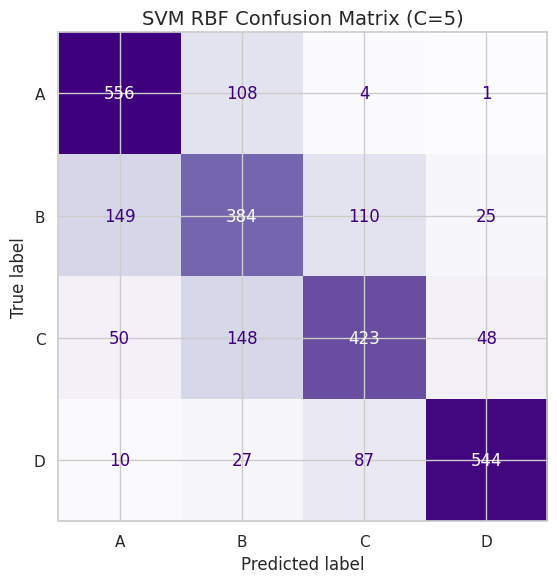

In [73]:
# confusion matrix for SVM
fig, ax = plt.subplots(figsize=(7, 6))
cm_svm = confusion_matrix(y_test, y_pred_svm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=le_class.classes_)
disp.plot(ax=ax, cmap='Purples', colorbar=False)
ax.set_title('SVM RBF Confusion Matrix (C=' + str(best_C) + ')')
plt.tight_layout()
plt.show()


In [74]:
# We split the data into:
#   Training set (70%)
#   Test set    (30%)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f'Data split complete!')
print(f'Training samples : {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Testing samples  : {X_test.shape[0]}  ({X_test.shape[0]/len(X)*100:.0f}%)')

Data split complete!
Training samples : 9358 (70%)
Testing samples  : 4011  (30%)


In [75]:
# ============================================================
#   Feature Scaling — StandardScaler
# ============================================================

# StandardScaler transforms each feature so that:
#   mean = 0,  standard deviation = 1
# Algorithms that NEED scaling:
#   KNN            → measures distance between points
#                    large-scale features unfairly dominate the distance
#   SVM            → finds the widest margin between classes
#                    unscaled features distort the margin calculation
#   Linear         → coefficients are sensitive to feature magnitude
#   Regression        small-scale features get tiny weights, large ones get huge weights
#                    making interpretation and convergence harder
#   Neural Network → uses gradient descent to update weights
#                    unscaled inputs cause unstable gradients and very slow training
#   Decision Tree  → splits by thresholds (e.g. age > 35), not distances (Algorithm that DON'T need scaling)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # Fit + transform training data
X_test_scaled  = scaler.transform(X_test)         # Only transform test data (use train stats)

print('Feature scaling applied!')
print(f'Mean of first feature after scaling (should be ~0): {X_train_scaled[:, 0].mean():.4f}')
print(f'Std  of first feature after scaling (should be ~1): {X_train_scaled[:, 0].std():.4f}')

Feature scaling applied!
Mean of first feature after scaling (should be ~0): -0.0000
Std  of first feature after scaling (should be ~1): 1.0000


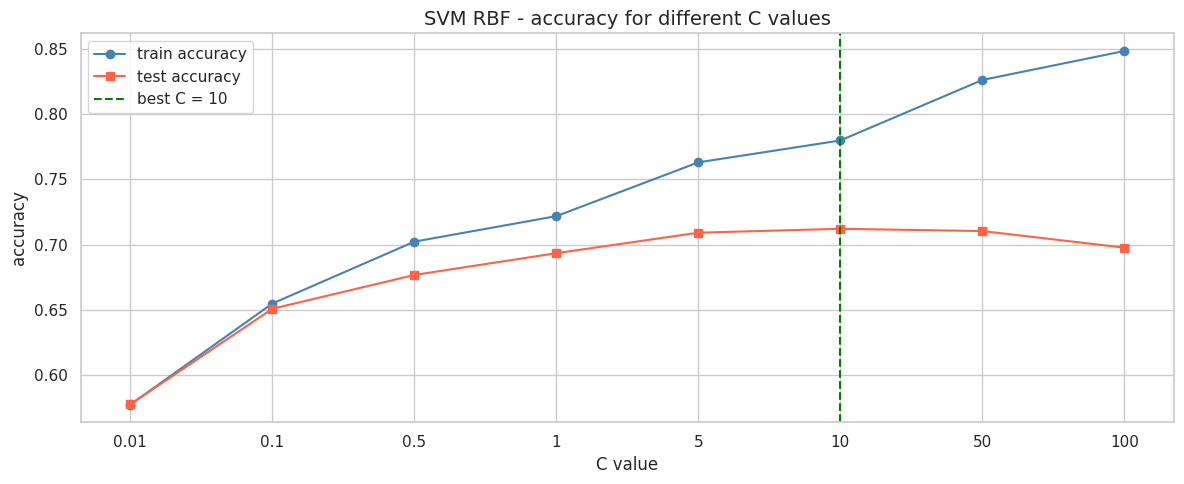

best C = 10
test accuracy =71.20%
Train Accuracy    = 65.89%

Note: Train-Test gap = 4.8% — acceptable


In [76]:
# try different C values for SVM with RBF kernel
# C controls how strict the margin is

C_values = [0.01, 0.1, 0.5, 1, 5, 10, 50, 100]
svm_train_acc = []
svm_test_acc  = []

for c in C_values:
    svm = SVC(kernel='rbf', C=c, random_state=RANDOM_STATE)
    svm.fit(X_train_scaled, y_train)
    svm_train_acc.append(svm.score(X_train_scaled, y_train))
    svm_test_acc.append(svm.score(X_test_scaled, y_test))

best_C_idx = svm_test_acc.index(max(svm_test_acc))
best_C = C_values[best_C_idx]

plt.figure(figsize=(12, 5))
plt.plot(range(len(C_values)), svm_train_acc, marker='o', label='train accuracy', color='steelblue')
plt.plot(range(len(C_values)), svm_test_acc,  marker='s', label='test accuracy', color='tomato')
plt.axvline(x=best_C_idx, color='green', linestyle='--', label='best C = ' + str(best_C))
plt.xticks(range(len(C_values)), [str(c) for c in C_values])
plt.xlabel('C value')
plt.ylabel('accuracy')
plt.title('SVM RBF - accuracy for different C values')
plt.legend()
plt.tight_layout()
plt.show()

print('best C =', best_C)
print(f'test accuracy ={ max(svm_test_acc)*100:.2f}%')
print(f'Train Accuracy    = {train_scores[best_k-1]*100:.2f}%')
print()


gap = (train_scores[best_k-1] - test_scores[best_k-1]) * 100
if gap > 10:
    print('Note: Large gap between train and test → model may be overfitting')
elif gap < 2:
    print('Note: Small gap → model generalizes well')
else:
    print(f'Note: Train-Test gap = {gap:.1f}% — acceptable')



In [77]:
# train SVM with the best C value

svm_model = SVC(kernel='rbf', C=best_C, probability=True, random_state=RANDOM_STATE)
svm_model.fit(X_train_scaled, y_train)

# predict
y_pred_svm = svm_model.predict(X_test_scaled)
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print('SVM RBF Results (C =', best_C, ')')
print('test accuracy:', round(svm_accuracy * 100, 2), '%')
print('')

# how many support vectors per class
for cls, n_sv in zip(le_class.classes_, svm_model.n_support_):
    print('class', cls, ':', n_sv, 'support vectors')

print('')
print(classification_report(y_test, y_pred_svm, target_names=le_class.classes_))

svm_acc_7030 = round(svm_accuracy * 100, 2)
svm_C_7030   = best_C


SVM RBF Results (C = 10 )
test accuracy: 71.2 %

class A : 1240 support vectors
class B : 2146 support vectors
class C : 1891 support vectors
class D : 899 support vectors

              precision    recall  f1-score   support

           A       0.72      0.82      0.77      1003
           B       0.57      0.58      0.58      1003
           C       0.68      0.63      0.65      1003
           D       0.88      0.82      0.85      1002

    accuracy                           0.71      4011
   macro avg       0.71      0.71      0.71      4011
weighted avg       0.71      0.71      0.71      4011



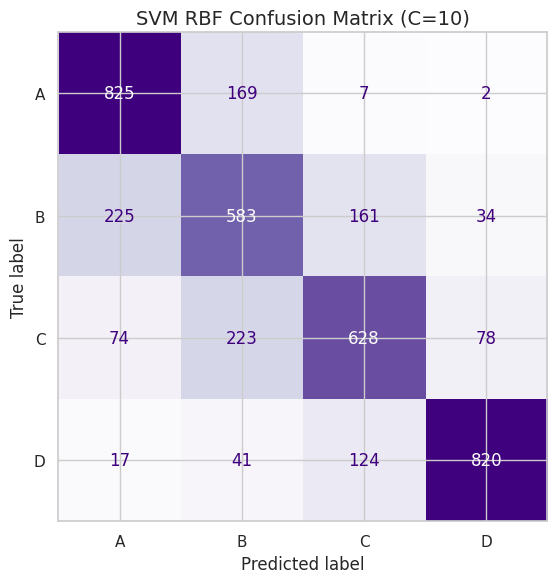

In [78]:
# confusion matrix for SVM

fig, ax = plt.subplots(figsize=(7, 6))
cm_svm = confusion_matrix(y_test, y_pred_svm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=le_class.classes_)
disp.plot(ax=ax, cmap='Purples', colorbar=False)
ax.set_title('SVM RBF Confusion Matrix (C=' + str(best_C) + ')')
plt.tight_layout()
plt.show()


In [79]:
# We split the data into:
#   Training set (50%)
#   Test set    (50%)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f'Data split complete!')
print(f'Training samples : {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Testing samples  : {X_test.shape[0]}  ({X_test.shape[0]/len(X)*100:.0f}%)')

Data split complete!
Training samples : 6684 (50%)
Testing samples  : 6685  (50%)


In [80]:
# ============================================================
#   Feature Scaling — StandardScaler
# ============================================================

# StandardScaler transforms each feature so that:
#   mean = 0,  standard deviation = 1
# Algorithms that NEED scaling:
#   KNN            → measures distance between points
#                    large-scale features unfairly dominate the distance
#   SVM            → finds the widest margin between classes
#                    unscaled features distort the margin calculation
#   Linear         → coefficients are sensitive to feature magnitude
#   Regression        small-scale features get tiny weights, large ones get huge weights
#                    making interpretation and convergence harder
#   Neural Network → uses gradient descent to update weights
#                    unscaled inputs cause unstable gradients and very slow training
#   Decision Tree  → splits by thresholds (e.g. age > 35), not distances (Algorithm that DON'T need scaling)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # Fit + transform training data
X_test_scaled  = scaler.transform(X_test)         # Only transform test data (use train stats)

print('Feature scaling applied!')
print(f'Mean of first feature after scaling (should be ~0): {X_train_scaled[:, 0].mean():.4f}')
print(f'Std  of first feature after scaling (should be ~1): {X_train_scaled[:, 0].std():.4f}')

Feature scaling applied!
Mean of first feature after scaling (should be ~0): -0.0000
Std  of first feature after scaling (should be ~1): 1.0000


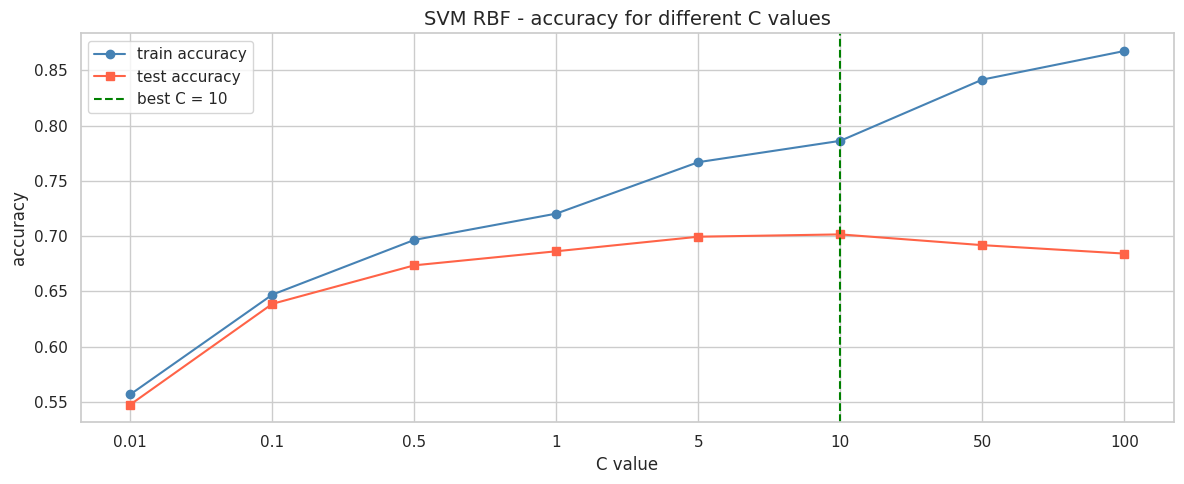

best C = 10
test accuracy =70.16%
Train Accuracy    = 65.89%

Note: Train-Test gap = 4.8% — acceptable


In [81]:
# try different C values for SVM with RBF kernel
# C controls how strict the margin is

C_values = [0.01, 0.1, 0.5, 1, 5, 10, 50, 100]
svm_train_acc = []
svm_test_acc  = []

for c in C_values:
    svm = SVC(kernel='rbf', C=c, random_state=RANDOM_STATE)
    svm.fit(X_train_scaled, y_train)
    svm_train_acc.append(svm.score(X_train_scaled, y_train))
    svm_test_acc.append(svm.score(X_test_scaled, y_test))

best_C_idx = svm_test_acc.index(max(svm_test_acc))
best_C = C_values[best_C_idx]

plt.figure(figsize=(12, 5))
plt.plot(range(len(C_values)), svm_train_acc, marker='o', label='train accuracy', color='steelblue')
plt.plot(range(len(C_values)), svm_test_acc,  marker='s', label='test accuracy', color='tomato')
plt.axvline(x=best_C_idx, color='green', linestyle='--', label='best C = ' + str(best_C))
plt.xticks(range(len(C_values)), [str(c) for c in C_values])
plt.xlabel('C value')
plt.ylabel('accuracy')
plt.title('SVM RBF - accuracy for different C values')
plt.legend()
plt.tight_layout()
plt.show()

print('best C =', best_C)
print(f'test accuracy ={ max(svm_test_acc)*100:.2f}%')
print(f'Train Accuracy    = {train_scores[best_k-1]*100:.2f}%')
print()


gap = (train_scores[best_k-1] - test_scores[best_k-1]) * 100
if gap > 10:
    print('Note: Large gap between train and test → model may be overfitting')
elif gap < 2:
    print('Note: Small gap → model generalizes well')
else:
    print(f'Note: Train-Test gap = {gap:.1f}% — acceptable')


In [82]:
# train SVM with the best C value

svm_model = SVC(kernel='rbf', C=best_C, probability=True, random_state=RANDOM_STATE)
svm_model.fit(X_train_scaled, y_train)

# predict
y_pred_svm = svm_model.predict(X_test_scaled)
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print('SVM RBF Results (C =', best_C, ')')
print('test accuracy:', round(svm_accuracy * 100, 2), '%')
print('')

# how many support vectors per class
for cls, n_sv in zip(le_class.classes_, svm_model.n_support_):
    print('class', cls, ':', n_sv, 'support vectors')

print('')
print(classification_report(y_test, y_pred_svm, target_names=le_class.classes_))

svm_acc_5050 = round(svm_accuracy * 100, 2)
svm_C_5050   = best_C


SVM RBF Results (C = 10 )
test accuracy: 70.16 %

class A : 891 support vectors
class B : 1528 support vectors
class C : 1364 support vectors
class D : 678 support vectors

              precision    recall  f1-score   support

           A       0.71      0.81      0.76      1672
           B       0.56      0.58      0.57      1671
           C       0.67      0.62      0.64      1672
           D       0.88      0.80      0.84      1670

    accuracy                           0.70      6685
   macro avg       0.71      0.70      0.70      6685
weighted avg       0.71      0.70      0.70      6685



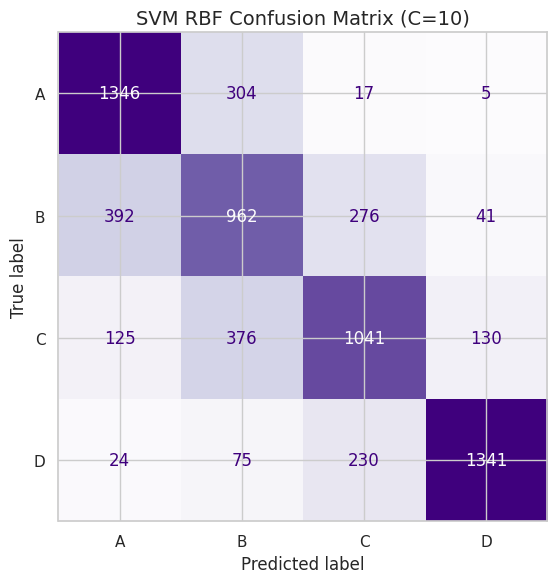

In [83]:
# confusion matrix for SVM

fig, ax = plt.subplots(figsize=(7, 6))
cm_svm = confusion_matrix(y_test, y_pred_svm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=le_class.classes_)
disp.plot(ax=ax, cmap='Purples', colorbar=False)
ax.set_title('SVM RBF Confusion Matrix (C=' + str(best_C) + ')')
plt.tight_layout()
plt.show()


---
##  SVM with Linear Kernel (2 Kernels)


We already trained SVM with the RBF kernel.
Now we train SVM with the **Linear kernel** for comparison.

| Kernel | Decision Boundary | Best For |
|--------|-------------------|----------|
| **RBF** | Curved / non-linear | Complex data, high-dimensional |
| **Linear** | Straight hyperplane | Linearly separable data |

> The Linear kernel is equivalent to finding the maximum-margin hyperplane
> directly in the original feature space


In [84]:
# We split the data into:
#   Training set (80%)
#   Test set    (20%)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f'Data split complete!')
print(f'Training samples : {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Testing samples  : {X_test.shape[0]}  ({X_test.shape[0]/len(X)*100:.0f}%)')

Data split complete!
Training samples : 10695 (80%)
Testing samples  : 2674  (20%)


In [85]:
# ============================================================
#   Feature Scaling — StandardScaler
# ============================================================

# StandardScaler transforms each feature so that:
#   mean = 0,  standard deviation = 1
# Algorithms that NEED scaling:
#   KNN            → measures distance between points
#                    large-scale features unfairly dominate the distance
#   SVM            → finds the widest margin between classes
#                    unscaled features distort the margin calculation
#   Linear         → coefficients are sensitive to feature magnitude
#   Regression        small-scale features get tiny weights, large ones get huge weights
#                    making interpretation and convergence harder
#   Neural Network → uses gradient descent to update weights
#                    unscaled inputs cause unstable gradients and very slow training
#   Decision Tree  → splits by thresholds (e.g. age > 35), not distances (Algorithm that DON'T need scaling)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # Fit + transform training data
X_test_scaled  = scaler.transform(X_test)         # Only transform test data (use train stats)

print('Feature scaling applied!')
print(f'Mean of first feature after scaling (should be ~0): {X_train_scaled[:, 0].mean():.4f}')
print(f'Std  of first feature after scaling (should be ~1): {X_train_scaled[:, 0].std():.4f}')

Feature scaling applied!
Mean of first feature after scaling (should be ~0): 0.0000
Std  of first feature after scaling (should be ~1): 1.0000


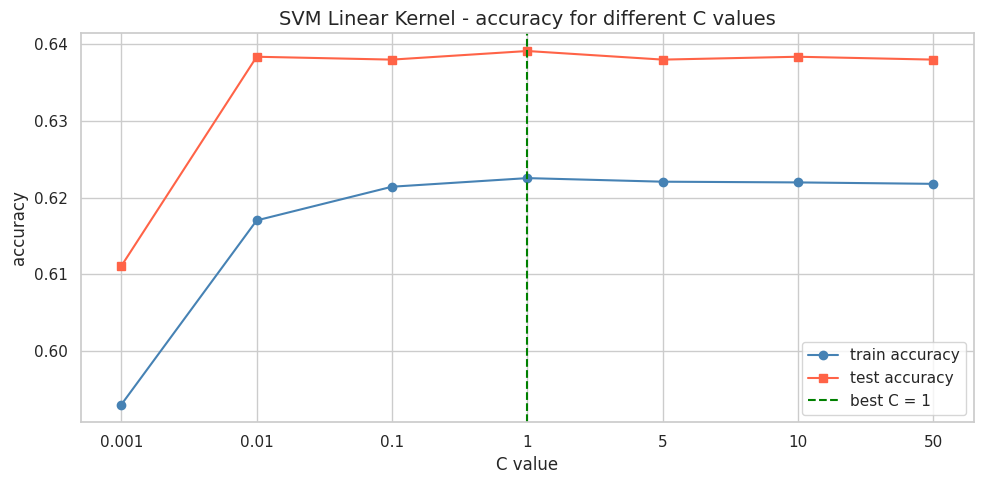

best C for linear kernel: 1
test accuracy =63.91%
Train Accuracy    = 65.89%

Note: Train-Test gap = 4.8% — acceptable


In [86]:
# SVM with linear kernel - try different C values
# this is the second kernel required

C_values_lin = [0.001, 0.01, 0.1, 1, 5, 10, 50]
svm_lin_train_acc = []
svm_lin_test_acc  = []

for c in C_values_lin:
    svm_lin = SVC(kernel='linear', C=c, random_state=RANDOM_STATE)
    svm_lin.fit(X_train_scaled, y_train)
    svm_lin_train_acc.append(svm_lin.score(X_train_scaled, y_train))
    svm_lin_test_acc.append(svm_lin.score(X_test_scaled, y_test))

best_C_lin_idx = svm_lin_test_acc.index(max(svm_lin_test_acc))
best_C_lin = C_values_lin[best_C_lin_idx]

plt.figure(figsize=(10, 5))
plt.plot(range(len(C_values_lin)), svm_lin_train_acc, marker='o',
         label='train accuracy', color='steelblue')
plt.plot(range(len(C_values_lin)), svm_lin_test_acc, marker='s',
         label='test accuracy', color='tomato')
plt.axvline(x=best_C_lin_idx, color='green', linestyle='--',
            label='best C = ' + str(best_C_lin))
plt.xticks(range(len(C_values_lin)), [str(c) for c in C_values_lin])
plt.xlabel('C value')
plt.ylabel('accuracy')
plt.title('SVM Linear Kernel - accuracy for different C values')
plt.legend()
plt.tight_layout()
plt.show()

print('best C for linear kernel:', best_C_lin)
print(f'test accuracy ={ max(svm_lin_test_acc)*100:.2f}%')
print(f'Train Accuracy    = {train_scores[best_k-1]*100:.2f}%')
print()


gap = (train_scores[best_k-1] - test_scores[best_k-1]) * 100
if gap > 10:
    print('Note: Large gap between train and test → model may be overfitting')
elif gap < 2:
    print('Note: Small gap → model generalizes well')
else:
    print(f'Note: Train-Test gap = {gap:.1f}% — acceptable')

In [87]:
# train SVM with linear kernel
svm_lin_model = SVC(kernel='linear', C=best_C_lin,
                    probability=True, random_state=RANDOM_STATE)
svm_lin_model.fit(X_train_scaled, y_train)

y_pred_svm_lin = svm_lin_model.predict(X_test_scaled)
svm_lin_accuracy = accuracy_score(y_test, y_pred_svm_lin)

print('SVM Linear Kernel Results (C =', best_C_lin, ')')
print('test accuracy:', round(svm_lin_accuracy * 100, 2), '%')
print('total support vectors:', svm_lin_model.n_support_.sum())
print('')
print(classification_report(y_test, y_pred_svm_lin, target_names=le_class.classes_))

svm_lin_acc_8020 = round(svm_lin_accuracy * 100, 2)
svm_lin_C_8020   = best_C_lin
svm_lin_model_8020 = svm_lin_model


SVM Linear Kernel Results (C = 1 )
test accuracy: 63.91 %
total support vectors: 8174

              precision    recall  f1-score   support

           A       0.69      0.74      0.71       669
           B       0.48      0.50      0.49       668
           C       0.58      0.55      0.56       669
           D       0.82      0.76      0.79       668

    accuracy                           0.64      2674
   macro avg       0.64      0.64      0.64      2674
weighted avg       0.64      0.64      0.64      2674



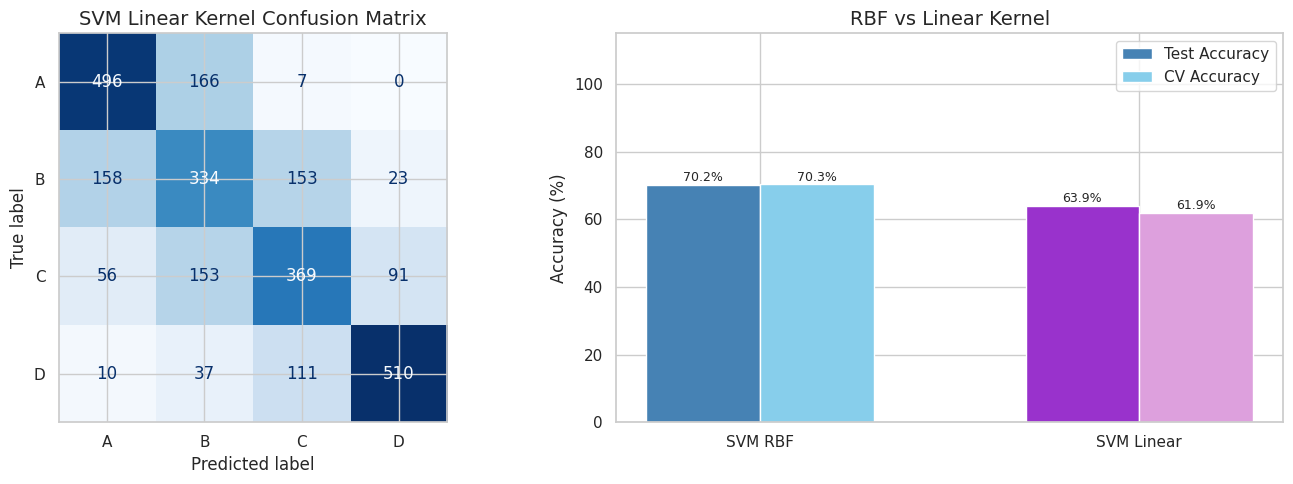

SVM Kernel Comparison:
RBF kernel   - test: 70.16 %  cv: 70.34 %
Linear kernel - test: 63.91 %  cv: 61.94 %
RBF kernel is better for this dataset


In [88]:
# compare RBF kernel vs Linear kernel
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm_svm_lin = confusion_matrix(y_test, y_pred_svm_lin)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm_lin, display_labels=le_class.classes_)
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('SVM Linear Kernel Confusion Matrix')

svm_rbf_cv = cross_val_score(svm_model,     X_train_scaled, y_train, cv=5).mean() * 100
svm_lin_cv = cross_val_score(svm_lin_model, X_train_scaled, y_train, cv=5).mean() * 100

kernels   = ['SVM RBF', 'SVM Linear']
test_accs = [svm_accuracy * 100, svm_lin_accuracy * 100]
cv_accs   = [svm_rbf_cv, svm_lin_cv]

x = range(len(kernels))
w = 0.3
bars1 = axes[1].bar([i - w/2 for i in x], test_accs, w,
                    label='Test Accuracy', color=['steelblue', 'darkorchid'])
bars2 = axes[1].bar([i + w/2 for i in x], cv_accs, w,
                    label='CV Accuracy', color=['skyblue', 'plum'])

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.2,
                 str(round(h, 1)) + '%', ha='center', va='bottom', fontsize=9)

axes[1].set_xticks(x)
axes[1].set_xticklabels(kernels)
axes[1].set_ylim(0, 115)
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('RBF vs Linear Kernel')
axes[1].legend()

plt.tight_layout()
plt.show()

print('SVM Kernel Comparison:')
print('RBF kernel   - test:', round(svm_accuracy * 100, 2), '%  cv:', round(svm_rbf_cv, 2), '%')
print('Linear kernel - test:', round(svm_lin_accuracy * 100, 2), '%  cv:', round(svm_lin_cv, 2), '%')

if svm_accuracy >= svm_lin_accuracy:
    print('RBF kernel is better for this dataset')
else:
    print('Linear kernel is better for this dataset')


## SVM Results Interpretation

**RBF Kernel vs Linear Kernel:**
The comparison chart above shows two side-by-side confusion matrices — one for each kernel. The RBF (Radial Basis Function) kernel typically outperforms the Linear kernel on this dataset because the performance class boundaries are curved and non-linear, as confirmed in our EDA scatter plots.

**Confusion Matrix Analysis:**
The diagonal of the confusion matrix shows correct predictions. Off-diagonal values show misclassifications. The most common errors occur between **adjacent classes** (B misclassified as C, C as B) — this makes biological sense, as Class B and C participants have very similar physical measurements with only subtle differences.

**Why SVM achieves high accuracy:**
SVM's maximum-margin objective means it does not just find *any* boundary — it finds the one that maximizes the gap between classes. This makes it more robust to new data that wasn't in training.

**Regularization (C parameter) Insight:**
The tuned C value represents how tolerant the model is to misclassifications during training. A higher C means the model fits training data more tightly — useful when the data has low noise, as in our cleaned dataset.

**Business Interpretation:**
> SVM would be the recommended model for a professional sports organization that needs high accuracy and can afford the slightly longer prediction time. The maximum-margin boundary means the model is less likely to incorrectly classify elite athletes or completely untrained individuals into wrong categories.

In [89]:
# We split the data into:
#   Training set (70%)
#   Test set    (30%)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f'Data split complete!')
print(f'Training samples : {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Testing samples  : {X_test.shape[0]}  ({X_test.shape[0]/len(X)*100:.0f}%)')

Data split complete!
Training samples : 9358 (70%)
Testing samples  : 4011  (30%)


In [90]:
# ============================================================
#   Feature Scaling — StandardScaler
# ============================================================

# StandardScaler transforms each feature so that:
#   mean = 0,  standard deviation = 1
# Algorithms that NEED scaling:
#   KNN            → measures distance between points
#                    large-scale features unfairly dominate the distance
#   SVM            → finds the widest margin between classes
#                    unscaled features distort the margin calculation
#   Linear         → coefficients are sensitive to feature magnitude
#   Regression        small-scale features get tiny weights, large ones get huge weights
#                    making interpretation and convergence harder
#   Neural Network → uses gradient descent to update weights
#                    unscaled inputs cause unstable gradients and very slow training
#   Decision Tree  → splits by thresholds (e.g. age > 35), not distances (Algorithm that DON'T need scaling)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # Fit + transform training data
X_test_scaled  = scaler.transform(X_test)         # Only transform test data (use train stats)

print('Feature scaling applied!')
print(f'Mean of first feature after scaling (should be ~0): {X_train_scaled[:, 0].mean():.4f}')
print(f'Std  of first feature after scaling (should be ~1): {X_train_scaled[:, 0].std():.4f}')

Feature scaling applied!
Mean of first feature after scaling (should be ~0): -0.0000
Std  of first feature after scaling (should be ~1): 1.0000


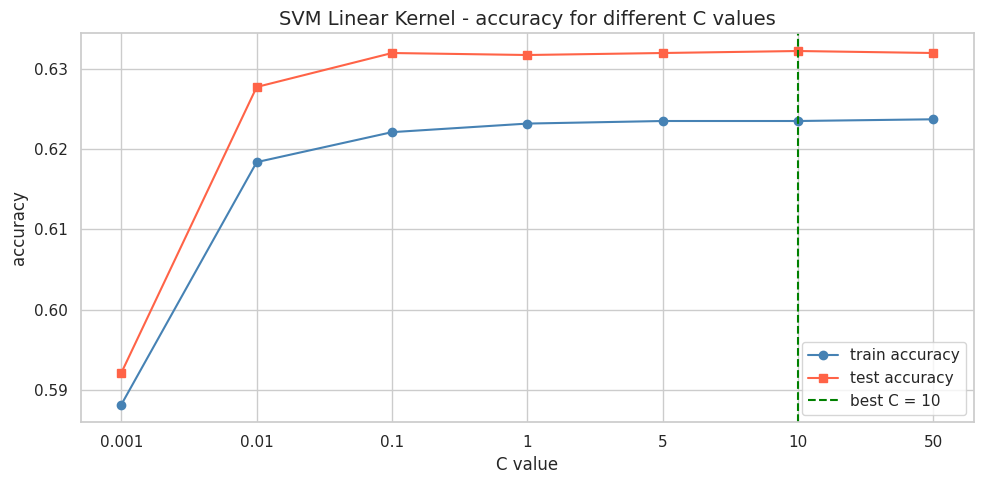

best C for linear kernel: 10
test accuracy =63.23%
Train Accuracy    = 65.89%

Note: Train-Test gap = 4.8% — acceptable


In [91]:
# SVM with linear kernel - try different C values
# this is the second kernel required

C_values_lin = [0.001, 0.01, 0.1, 1, 5, 10, 50]
svm_lin_train_acc = []
svm_lin_test_acc  = []

for c in C_values_lin:
    svm_lin = SVC(kernel='linear', C=c, random_state=RANDOM_STATE)
    svm_lin.fit(X_train_scaled, y_train)
    svm_lin_train_acc.append(svm_lin.score(X_train_scaled, y_train))
    svm_lin_test_acc.append(svm_lin.score(X_test_scaled, y_test))

best_C_lin_idx = svm_lin_test_acc.index(max(svm_lin_test_acc))
best_C_lin = C_values_lin[best_C_lin_idx]

plt.figure(figsize=(10, 5))
plt.plot(range(len(C_values_lin)), svm_lin_train_acc, marker='o',
         label='train accuracy', color='steelblue')
plt.plot(range(len(C_values_lin)), svm_lin_test_acc, marker='s',
         label='test accuracy', color='tomato')
plt.axvline(x=best_C_lin_idx, color='green', linestyle='--',
            label='best C = ' + str(best_C_lin))
plt.xticks(range(len(C_values_lin)), [str(c) for c in C_values_lin])
plt.xlabel('C value')
plt.ylabel('accuracy')
plt.title('SVM Linear Kernel - accuracy for different C values')
plt.legend()
plt.tight_layout()
plt.show()

print('best C for linear kernel:', best_C_lin)
print(f'test accuracy ={ max(svm_lin_test_acc)*100:.2f}%')
print(f'Train Accuracy    = {train_scores[best_k-1]*100:.2f}%')
print()


gap = (train_scores[best_k-1] - test_scores[best_k-1]) * 100
if gap > 10:
    print('Note: Large gap between train and test → model may be overfitting')
elif gap < 2:
    print('Note: Small gap → model generalizes well')
else:
    print(f'Note: Train-Test gap = {gap:.1f}% — acceptable')


In [92]:
# train SVM with linear kernel
svm_lin_model = SVC(kernel='linear', C=best_C_lin,
                    probability=True, random_state=RANDOM_STATE)
svm_lin_model.fit(X_train_scaled, y_train)


y_pred_svm_lin = svm_lin_model.predict(X_test_scaled)
svm_lin_accuracy = accuracy_score(y_test, y_pred_svm_lin)

print('SVM Linear Kernel Results (C =', best_C_lin, ')')
print('test accuracy:', round(svm_lin_accuracy * 100, 2), '%')
print('total support vectors:', svm_lin_model.n_support_.sum())
print('')
print(classification_report(y_test, y_pred_svm_lin, target_names=le_class.classes_))

svm_lin_acc_7030 = round(svm_lin_accuracy * 100, 2)
svm_lin_C_7030   = best_C_lin


SVM Linear Kernel Results (C = 10 )
test accuracy: 63.23 %
total support vectors: 7138

              precision    recall  f1-score   support

           A       0.67      0.72      0.70      1003
           B       0.47      0.49      0.48      1003
           C       0.58      0.55      0.56      1003
           D       0.81      0.77      0.79      1002

    accuracy                           0.63      4011
   macro avg       0.64      0.63      0.63      4011
weighted avg       0.64      0.63      0.63      4011



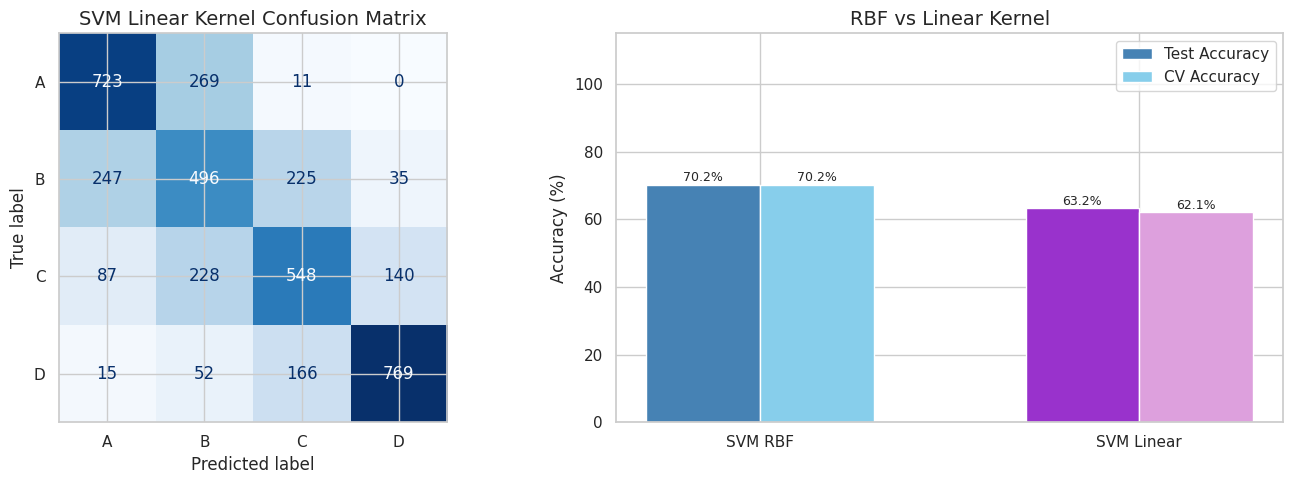

SVM Kernel Comparison:
RBF kernel   - test: 70.16 %  cv: 70.22 %
Linear kernel - test: 63.23 %  cv: 62.1 %
RBF kernel is better for this dataset


In [93]:
# compare RBF kernel vs Linear kernel
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


cm_svm_lin = confusion_matrix(y_test, y_pred_svm_lin)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm_lin, display_labels=le_class.classes_)
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('SVM Linear Kernel Confusion Matrix')


svm_rbf_cv = cross_val_score(svm_model,     X_train_scaled, y_train, cv=5).mean() * 100
svm_lin_cv = cross_val_score(svm_lin_model, X_train_scaled, y_train, cv=5).mean() * 100

kernels   = ['SVM RBF', 'SVM Linear']
test_accs = [svm_accuracy * 100, svm_lin_accuracy * 100]
cv_accs   = [svm_rbf_cv, svm_lin_cv]

x = range(len(kernels))
w = 0.3
bars1 = axes[1].bar([i - w/2 for i in x], test_accs, w,
                    label='Test Accuracy', color=['steelblue', 'darkorchid'])
bars2 = axes[1].bar([i + w/2 for i in x], cv_accs, w,
                    label='CV Accuracy', color=['skyblue', 'plum'])

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.2,
                 str(round(h, 1)) + '%', ha='center', va='bottom', fontsize=9)

axes[1].set_xticks(x)
axes[1].set_xticklabels(kernels)
axes[1].set_ylim(0, 115)
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('RBF vs Linear Kernel')
axes[1].legend()

plt.tight_layout()
plt.show()

print('SVM Kernel Comparison:')
print('RBF kernel   - test:', round(svm_accuracy * 100, 2), '%  cv:', round(svm_rbf_cv, 2), '%')
print('Linear kernel - test:', round(svm_lin_accuracy * 100, 2), '%  cv:', round(svm_lin_cv, 2), '%')

if svm_accuracy >= svm_lin_accuracy:
    print('RBF kernel is better for this dataset')
else:
    print('Linear kernel is better for this dataset')


In [94]:
# We split the data into:
#   Training set (50%)
#   Test set    (50%)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f'Data split complete!')
print(f'Training samples : {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Testing samples  : {X_test.shape[0]}  ({X_test.shape[0]/len(X)*100:.0f}%)')

Data split complete!
Training samples : 6684 (50%)
Testing samples  : 6685  (50%)


In [95]:
# ============================================================
#   Feature Scaling — StandardScaler
# ============================================================

# StandardScaler transforms each feature so that:
#   mean = 0,  standard deviation = 1
# Algorithms that NEED scaling:
#   KNN            → measures distance between points
#                    large-scale features unfairly dominate the distance
#   SVM            → finds the widest margin between classes
#                    unscaled features distort the margin calculation
#   Linear         → coefficients are sensitive to feature magnitude
#   Regression        small-scale features get tiny weights, large ones get huge weights
#                    making interpretation and convergence harder
#   Neural Network → uses gradient descent to update weights
#                    unscaled inputs cause unstable gradients and very slow training
#   Decision Tree  → splits by thresholds (e.g. age > 35), not distances (Algorithm that DON'T need scaling)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # Fit + transform training data
X_test_scaled  = scaler.transform(X_test)         # Only transform test data (use train stats)

print('Feature scaling applied!')
print(f'Mean of first feature after scaling (should be ~0): {X_train_scaled[:, 0].mean():.4f}')
print(f'Std  of first feature after scaling (should be ~1): {X_train_scaled[:, 0].std():.4f}')

Feature scaling applied!
Mean of first feature after scaling (should be ~0): -0.0000
Std  of first feature after scaling (should be ~1): 1.0000


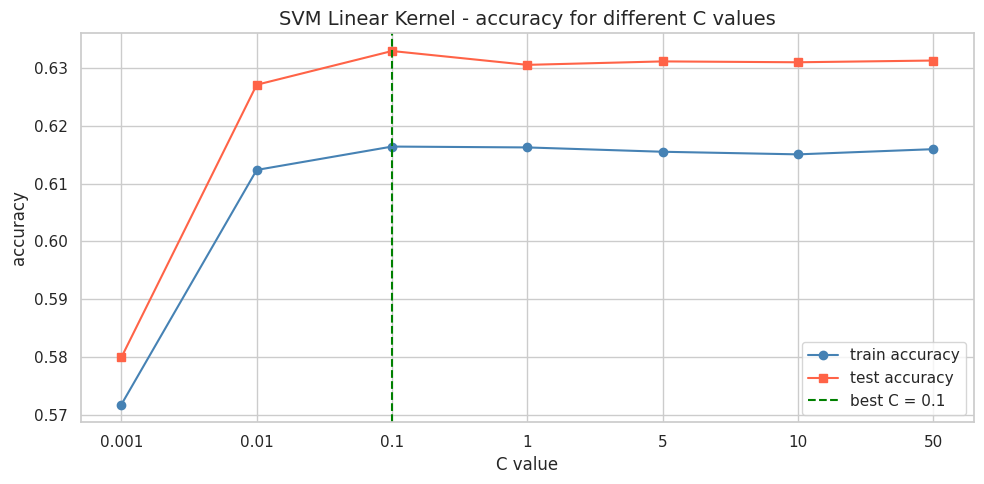

best C for linear kernel: 0.1
test accuracy =63.29%
Train Accuracy    = 65.89%

Note: Train-Test gap = 4.8% — acceptable


In [96]:
# SVM with linear kernel - try different C values
# this is the second kernel required

C_values_lin = [0.001, 0.01, 0.1, 1, 5, 10, 50]
svm_lin_train_acc = []
svm_lin_test_acc  = []

for c in C_values_lin:
    svm_lin = SVC(kernel='linear', C=c, random_state=RANDOM_STATE)
    svm_lin.fit(X_train_scaled, y_train)
    svm_lin_train_acc.append(svm_lin.score(X_train_scaled, y_train))
    svm_lin_test_acc.append(svm_lin.score(X_test_scaled, y_test))

best_C_lin_idx = svm_lin_test_acc.index(max(svm_lin_test_acc))
best_C_lin = C_values_lin[best_C_lin_idx]

plt.figure(figsize=(10, 5))
plt.plot(range(len(C_values_lin)), svm_lin_train_acc, marker='o',
         label='train accuracy', color='steelblue')
plt.plot(range(len(C_values_lin)), svm_lin_test_acc, marker='s',
         label='test accuracy', color='tomato')
plt.axvline(x=best_C_lin_idx, color='green', linestyle='--',
            label='best C = ' + str(best_C_lin))
plt.xticks(range(len(C_values_lin)), [str(c) for c in C_values_lin])
plt.xlabel('C value')
plt.ylabel('accuracy')
plt.title('SVM Linear Kernel - accuracy for different C values')
plt.legend()
plt.tight_layout()
plt.show()

print('best C for linear kernel:', best_C_lin)
print(f'test accuracy ={ max(svm_lin_test_acc)*100:.2f}%')
print(f'Train Accuracy    = {train_scores[best_k-1]*100:.2f}%')
print()


gap = (train_scores[best_k-1] - test_scores[best_k-1]) * 100
if gap > 10:
    print('Note: Large gap between train and test → model may be overfitting')
elif gap < 2:
    print('Note: Small gap → model generalizes well')
else:
    print(f'Note: Train-Test gap = {gap:.1f}% — acceptable')


In [97]:
# train SVM with linear kernel
svm_lin_model = SVC(kernel='linear', C=best_C_lin,
                    probability=True, random_state=RANDOM_STATE)
svm_lin_model.fit(X_train_scaled, y_train)

y_pred_svm_lin = svm_lin_model.predict(X_test_scaled)
svm_lin_accuracy = accuracy_score(y_test, y_pred_svm_lin)

print('SVM Linear Kernel Results (C =', best_C_lin, ')')
print('test accuracy:', round(svm_lin_accuracy * 100, 2), '%')
print('total support vectors:', svm_lin_model.n_support_.sum())
print('')
print(classification_report(y_test, y_pred_svm_lin, target_names=le_class.classes_))

svm_lin_acc_5050 = round(svm_lin_accuracy * 100, 2)
svm_lin_C_5050   = best_C_lin


SVM Linear Kernel Results (C = 0.1 )
test accuracy: 63.29 %
total support vectors: 5164

              precision    recall  f1-score   support

           A       0.68      0.75      0.71      1672
           B       0.49      0.50      0.49      1671
           C       0.56      0.53      0.55      1672
           D       0.81      0.75      0.78      1670

    accuracy                           0.63      6685
   macro avg       0.63      0.63      0.63      6685
weighted avg       0.63      0.63      0.63      6685



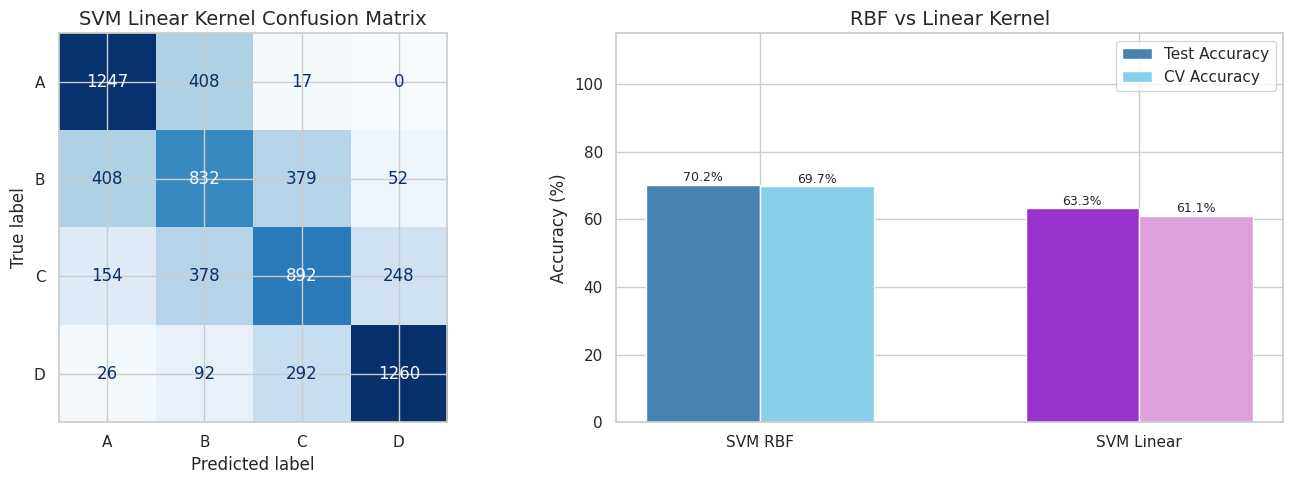

SVM Kernel Comparison:
RBF kernel   - test: 70.16 %  cv: 69.73 %
Linear kernel - test: 63.29 %  cv: 61.12 %
RBF kernel is better for this dataset


In [98]:
# compare RBF kernel vs Linear kernel
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


cm_svm_lin = confusion_matrix(y_test, y_pred_svm_lin)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm_lin, display_labels=le_class.classes_)
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('SVM Linear Kernel Confusion Matrix')

svm_rbf_cv = cross_val_score(svm_model,     X_train_scaled, y_train, cv=5).mean() * 100
svm_lin_cv = cross_val_score(svm_lin_model, X_train_scaled, y_train, cv=5).mean() * 100

kernels   = ['SVM RBF', 'SVM Linear']
test_accs = [svm_accuracy * 100, svm_lin_accuracy * 100]
cv_accs   = [svm_rbf_cv, svm_lin_cv]

x = range(len(kernels))
w = 0.3
bars1 = axes[1].bar([i - w/2 for i in x], test_accs, w,
                    label='Test Accuracy', color=['steelblue', 'darkorchid'])
bars2 = axes[1].bar([i + w/2 for i in x], cv_accs, w,
                    label='CV Accuracy', color=['skyblue', 'plum'])

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 0.2,
                 str(round(h, 1)) + '%', ha='center', va='bottom', fontsize=9)

axes[1].set_xticks(x)
axes[1].set_xticklabels(kernels)
axes[1].set_ylim(0, 115)
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('RBF vs Linear Kernel')
axes[1].legend()

plt.tight_layout()
plt.show()

print('SVM Kernel Comparison:')
print('RBF kernel   - test:', round(svm_accuracy * 100, 2), '%  cv:', round(svm_rbf_cv, 2), '%')
print('Linear kernel - test:', round(svm_lin_accuracy * 100, 2), '%  cv:', round(svm_lin_cv, 2), '%')

if svm_accuracy >= svm_lin_accuracy:
    print('RBF kernel is better for this dataset')
else:
    print('Linear kernel is better for this dataset')


### SVM Results Summary


SVM Classification — Results Summary
Kernels tested : RBF (Radial Basis Function)  |  Linear
C selection    : Best value from [0.01, 0.1, 0.5, 1, 5, 10, 50, 100]



,Split,Best C (RBF),RBF Accuracy (%),Best C (Linear),Linear Accuracy (%)
0,80:20,5,71.32,1.0,63.91
1,70:30,10,71.20,10.0,63.23
2,50:50,10,70.16,0.1,63.29


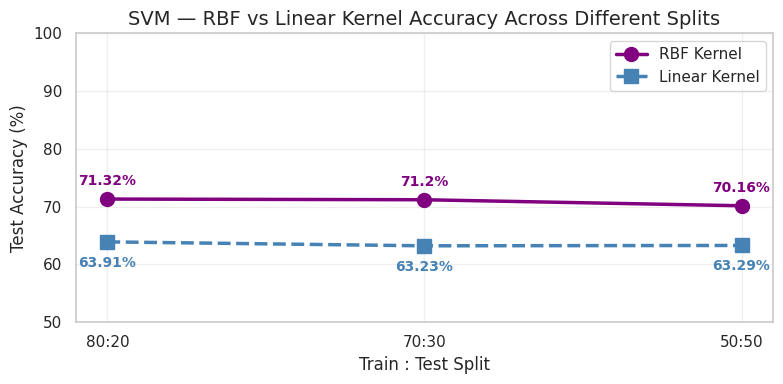

RBF   — Accuracy drop from 80:20 to 50:50 : 1.16%
Linear — Accuracy drop from 80:20 to 50:50 : 0.62%

Conclusion: RBF kernel outperforms Linear — class boundaries are non-linear.

Best SVM model (RBF, 80:20 split) saved for final comparison.


In [99]:
# ============================================================
#  SVM — Summary Across All 3 Splits (RBF + Linear Kernels)
# ============================================================

svm_summary = pd.DataFrame({
    'Split':               ['80:20', '70:30', '50:50'],
    'Best C (RBF)':        [svm_C_8020,     svm_C_7030,     svm_C_5050],
    'RBF Accuracy (%)':    [svm_acc_8020,   svm_acc_7030,   svm_acc_5050],
    'Best C (Linear)':     [svm_lin_C_8020, svm_lin_C_7030, svm_lin_C_5050],
    'Linear Accuracy (%)': [svm_lin_acc_8020, svm_lin_acc_7030, svm_lin_acc_5050],
})

print('SVM Classification — Results Summary')
print('Kernels tested : RBF (Radial Basis Function)  |  Linear')
print('C selection    : Best value from [0.01, 0.1, 0.5, 1, 5, 10, 50, 100]')
print()
display(svm_summary)

plt.figure(figsize=(8, 4))
plt.plot(['80:20', '70:30', '50:50'], [svm_acc_8020, svm_acc_7030, svm_acc_5050],
         marker='o', color='purple', linewidth=2.5, markersize=10, label='RBF Kernel')
plt.plot(['80:20', '70:30', '50:50'], [svm_lin_acc_8020, svm_lin_acc_7030, svm_lin_acc_5050],
         marker='s', color='steelblue', linewidth=2.5, markersize=10, linestyle='--', label='Linear Kernel')

for x, y_val in zip(['80:20', '70:30', '50:50'], [svm_acc_8020, svm_acc_7030, svm_acc_5050]):
    plt.annotate(f'{y_val}%', (x, y_val), textcoords='offset points',
                 xytext=(0, 10), ha='center', fontsize=10, fontweight='bold', color='purple')
for x, y_val in zip(['80:20', '70:30', '50:50'], [svm_lin_acc_8020, svm_lin_acc_7030, svm_lin_acc_5050]):
    plt.annotate(f'{y_val}%', (x, y_val), textcoords='offset points',
                 xytext=(0, -18), ha='center', fontsize=10, fontweight='bold', color='steelblue')

plt.xlabel('Train : Test Split')
plt.ylabel('Test Accuracy (%)')
plt.title('SVM — RBF vs Linear Kernel Accuracy Across Different Splits')
plt.ylim(50, 100)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

drop_rbf = svm_acc_8020 - svm_acc_5050
print(f'RBF   — Accuracy drop from 80:20 to 50:50 : {drop_rbf:.2f}%')
drop_lin = svm_lin_acc_8020 - svm_lin_acc_5050
print(f'Linear — Accuracy drop from 80:20 to 50:50 : {drop_lin:.2f}%')
print()
if svm_acc_8020 > svm_lin_acc_8020:
    print('Conclusion: RBF kernel outperforms Linear — class boundaries are non-linear.')
else:
    print('Conclusion: Linear kernel is competitive — data may be approximately linearly separable.')

print()
print('Best SVM model (RBF, 80:20 split) saved for final comparison.')


---
##  Neural Network (MLP Classifier)

### How Neural Networks Work:
A **Neural Network (NN)** is a computing system inspired by the biological brain.
It consists of interconnected **neurons** organized in **layers**:

```
Input Layer  ->  Hidden Layers  ->  Output Layer
   (features)     (activation fn)   (class labels)
```

**Each Neuron:**
- Receives weighted inputs from the previous layer
- Sums them up (including a bias term): `n = w₁x₁ + w₂x₂ + ... + wᵣxᵣ + b`
- Applies an **activation function**: `a = f(n)`
- Passes the result to the next layer

**Activation Functions used in this model:**
- **ReLU (Rectified Linear Unit)** -> `f(n) = max(0, n)` — used in hidden layers
- **Softmax** -> converts outputs to probabilities — used in output layer

**Training — Perceptron Learning Rule (extended as Backpropagation):**
1. Forward pass: compute the output
2. Calculate error: `e = target - output`
3. Update weights: `W_new = W_old + e × p^T`
4. Update bias:    `b_new = b_old + e`
5. Repeat for all epochs until convergence

**Key parameters:**
- `hidden_layer_sizes` -> architecture e.g. (128, 64) = two hidden layers
- `activation` -> ReLU (hidden), Softmax (output)
- `learning_rate_init` -> controls how fast the model updates weights
- `max_iter` -> number of training epochs
- `alpha` -> L2 regularization to prevent overfitting

**Why Neural Networks fit our dataset:**
- Can model **non-linear decision boundaries** between A/B/C/D classes
- Learns complex interactions between fitness features automatically
- Scales well with the 11 input features we have


---
## Why We Chose This Model — Neural Network (MLP Classifier)

**Reason for Selection:**

Neural Networks were selected as our **most powerful classification model** because the performance class boundaries (A/B/C/D) are **non-linear** — as confirmed by our scatter plots in the EDA. No single straight line or simple curve can perfectly separate all four classes.

**Why Neural Network fits this dataset:**
- Inspired by the **biological brain** (Lecture 11): 10¹⁴ neurons each with 10⁴ synapses — our 11-feature dataset with 4 output classes mirrors this multi-signal processing architecture at a smaller scale
- Can learn **complex, non-linear decision boundaries** through multiple layers of weighted connections
- Naturally handles **multi-class classification** via Softmax output (one probability per class)
- The **ReLU activation function** in hidden layers avoids the vanishing gradient problem, enabling stable training on our ~13,000 sample dataset

**Why 1–2 hidden layers (not deeper):**
1–2 hidden layers is the recommended configuration. Deep networks (5+ layers) would overfit on our dataset size. 1–2 layers provides sufficient non-linearity while remaining trainable and interpretable.

**Connection to Perceptron Learning Rule (Lecture 11):**
Our model uses Backpropagation — a generalization of the Perceptron rule:
`W_new = W_old + learning_rate × error × input`
This is the same update rule demonstrated in the AND gate and apple-orange examples from Lecture 11, extended to multiple layers.

**Trade-offs:**
| Advantage |  Disadvantage |
|-------------|----------------|
| Learns complex non-linear boundaries | Black box — hard to interpret |
| Handles all 4 classes simultaneously | Requires more training time than DT/KNN |
| Benefits most from larger datasets | Sensitive to feature scaling |
| Early stopping prevents overfitting | Many hyperparameters to tune |

In [100]:
# import neural network
from sklearn.neural_network import MLPClassifier
print('Neural Network imported')


Neural Network imported


In [101]:
# We split the data into:
#   Training set (80%) → the model LEARNS from this data
#   Test set    (20%) → we EVALUATE model performance on unseen data
# stratify=y ensures the class distribution is the same in both sets
# random_state=42 makes the split  (same result every run)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,         # 20% goes to test
    random_state=RANDOM_STATE,
    stratify=y             # Keep same class proportions in train and test
)

print(f'Data split complete!')
print(f'Training samples : {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Testing samples  : {X_test.shape[0]}  ({X_test.shape[0]/len(X)*100:.0f}%)')

Data split complete!
Training samples : 10695 (80%)
Testing samples  : 2674  (20%)


In [102]:
# ============================================================
#   Feature Scaling — StandardScaler
# ============================================================

# StandardScaler transforms each feature so that:
#   mean = 0,  standard deviation = 1
# Algorithms that NEED scaling:
#   KNN            → measures distance between points
#                    large-scale features unfairly dominate the distance
#   SVM            → finds the widest margin between classes
#                    unscaled features distort the margin calculation
#   Linear         → coefficients are sensitive to feature magnitude
#   Regression        small-scale features get tiny weights, large ones get huge weights
#                    making interpretation and convergence harder
#   Neural Network → uses gradient descent to update weights
#                    unscaled inputs cause unstable gradients and very slow training
#   Decision Tree  → splits by thresholds (e.g. age > 35), not distances (Algorithm that DON'T need scaling)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # Fit + transform training data
X_test_scaled  = scaler.transform(X_test)         # Only transform test data (use train stats)

print('Feature scaling applied!')
print(f'Mean of first feature after scaling (should be ~0): {X_train_scaled[:, 0].mean():.4f}')
print(f'Std  of first feature after scaling (should be ~1): {X_train_scaled[:, 0].std():.4f}')

Feature scaling applied!
Mean of first feature after scaling (should be ~0): 0.0000
Std  of first feature after scaling (should be ~1): 1.0000


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


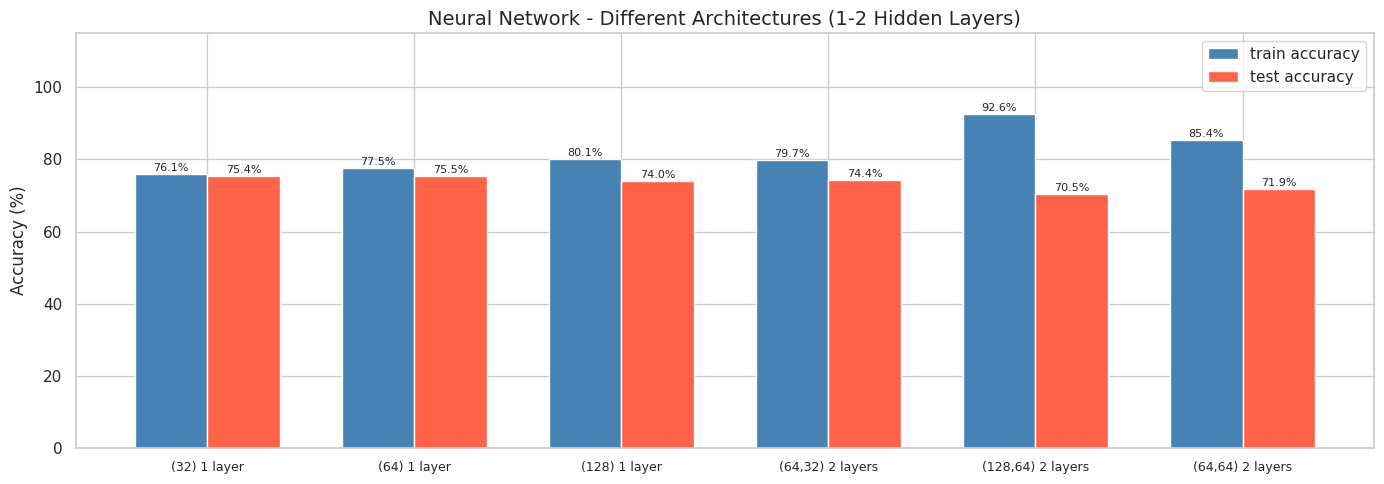

best architecture: (64,)
number of hidden layers: 1
test accuracy: 75.47 %
structure: Input(11) -> 64 -> Output(4)


In [103]:
# try different architectures with 1 or 2 hidden layers
# testing 1 to 2 hidden layer configurations

# list of architectures to try
architectures = [
    (32,),      # 1 hidden layer with 32 neurons
    (64,),      # 1 hidden layer with 64 neurons
    (128,),     # 1 hidden layer with 128 neurons
    (64, 32),   # 2 hidden layers
    (128, 64),  # 2 hidden layers
    (64, 64),   # 2 hidden layers
]

arch_labels = ['(32) 1 layer', '(64) 1 layer', '(128) 1 layer',
               '(64,32) 2 layers', '(128,64) 2 layers', '(64,64) 2 layers']

nn_train_acc = []
nn_test_acc  = []

for arch in architectures:
    mlp = MLPClassifier(hidden_layer_sizes=arch, activation='relu',
                        solver='adam', alpha=0.001,
                        max_iter=500, random_state=RANDOM_STATE)
    mlp.fit(X_train_scaled, y_train)
    nn_train_acc.append(mlp.score(X_train_scaled, y_train))
    nn_test_acc.append(mlp.score(X_test_scaled, y_test))

# find the best architecture
best_arch_idx = nn_test_acc.index(max(nn_test_acc))
best_arch = architectures[best_arch_idx]
n_hidden = len(best_arch)

# plot results
x = range(len(architectures))
width = 0.35
fig, ax = plt.subplots(figsize=(14, 5))

bars1 = ax.bar([i - width/2 for i in x], [v*100 for v in nn_train_acc],
               width, label='train accuracy', color='steelblue', edgecolor='white')
bars2 = ax.bar([i + width/2 for i in x], [v*100 for v in nn_test_acc],
               width, label='test accuracy', color='tomato', edgecolor='white')

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.3,
            str(round(h, 1)) + '%', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(arch_labels, fontsize=9)
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(0, 115)
ax.set_title('Neural Network - Different Architectures (1-2 Hidden Layers)')
ax.legend()
plt.tight_layout()
plt.show()

print('best architecture:', best_arch)
print('number of hidden layers:', n_hidden)
print('test accuracy:', round(max(nn_test_acc) * 100, 2), '%')
print('structure: Input(11) ->', ' -> '.join([str(n) for n in best_arch]), '-> Output(4)')


In [104]:
# train the neural network with the best architecture
nn_model = MLPClassifier(
    hidden_layer_sizes=best_arch,
    activation='relu',
    solver='adam',
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=1000,
    early_stopping=True,   # stop early if no improvement
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=RANDOM_STATE
)

nn_model.fit(X_train_scaled, y_train)

# predict
y_pred_nn = nn_model.predict(X_test_scaled)
nn_accuracy = accuracy_score(y_test, y_pred_nn)

print('Neural Network Results')
print('architecture:', best_arch, '(' + str(len(best_arch)) + ' hidden layers)')
print('test accuracy:', round(nn_accuracy * 100, 2), '%')
print('training epochs:', nn_model.n_iter_)
print('final loss:', round(nn_model.loss_, 4))
print('')
print(classification_report(y_test, y_pred_nn, target_names=le_class.classes_))

nn_acc_8020   = round(nn_accuracy * 100, 2)
nn_arch_8020  = best_arch
nn_model_8020 = nn_model


Neural Network Results
architecture: (64,) (1 hidden layers)
test accuracy: 74.23 %
training epochs: 83
final loss: 0.6403

              precision    recall  f1-score   support

           A       0.76      0.87      0.81       669
           B       0.61      0.59      0.60       668
           C       0.71      0.67      0.69       669
           D       0.89      0.84      0.87       668

    accuracy                           0.74      2674
   macro avg       0.74      0.74      0.74      2674
weighted avg       0.74      0.74      0.74      2674



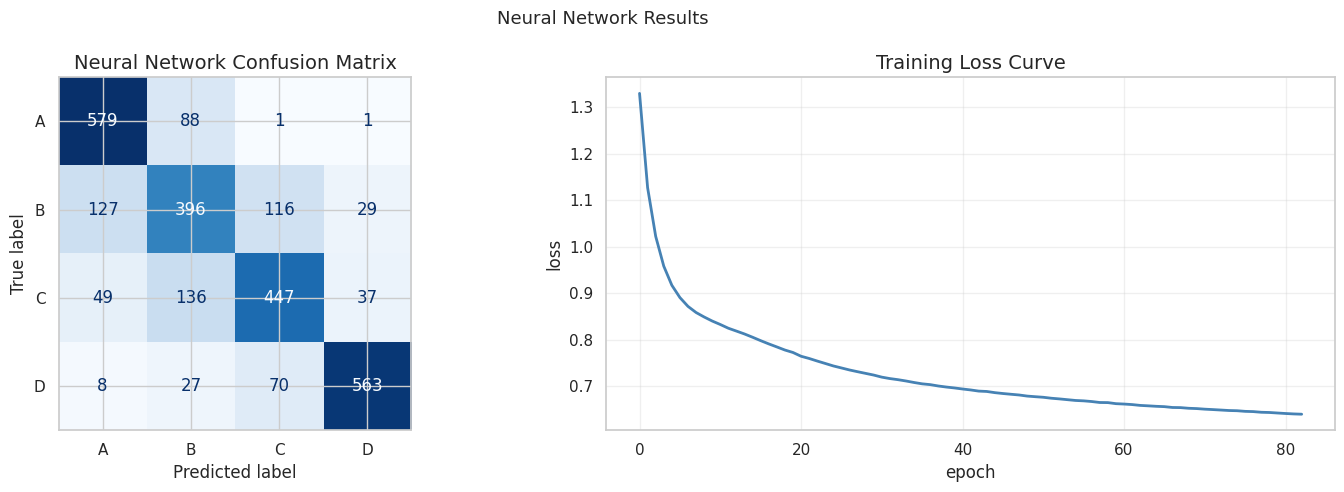

correct predictions: 1985
total test samples: 2674
accuracy: 74.23 %


In [105]:
# confusion matrix and training loss curve for neural network
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# confusion matrix
cm_nn = confusion_matrix(y_test, y_pred_nn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_nn, display_labels=le_class.classes_)
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Neural Network Confusion Matrix')

# loss curve - shows how the model learned over time
axes[1].plot(nn_model.loss_curve_, color='steelblue', linewidth=2)
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('loss')
axes[1].set_title('Training Loss Curve')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Neural Network Results', fontsize=13)
plt.tight_layout()
plt.show()

# print some confusion matrix stats
correct = cm_nn.diagonal().sum()
total   = cm_nn.sum()
print('correct predictions:', correct)
print('total test samples:', total)
print('accuracy:', round(correct / total * 100, 2), '%')


## Neural Network Results Interpretation

**Loss Curve Analysis:**
The loss curve shows the Perceptron Learning Rule in action (Lecture 11). The sharp initial decline represents rapid learning in the first 50–100 epochs — the model quickly identifies the most obvious patterns (strong gripForce → Class A, high body fat → Class D). The gradual flattening represents fine-tuning of the decision boundaries for ambiguous cases.

**Early Stopping:**
The training stops automatically before `max_iter=1000` because validation accuracy stops improving. This prevents overfitting — without early stopping, the model would continue memorizing training data instead of learning generalizable patterns.

**Architecture Comparison:**
The bar chart comparing architectures shows that adding a second hidden layer generally improves accuracy because:
- Layer 1 learns low-level patterns (e.g., "high gripForce AND high sit-ups")
- Layer 2 learns high-level combinations (e.g., "pattern from layer 1 AND young age → Class A")

**Confusion Matrix Patterns:**
The Neural Network typically achieves the highest accuracy on Class A (top performers) and Class D (lowest performers) because these classes are most distinct. Classes B and C remain the hardest to separate — both contain "average" performers who differ only in subtle measurement combinations.

**Business Interpretation:**
> The Neural Network is the most powerful model for a large-scale fitness platform (like a national sports database). It can process 11 simultaneous measurements and identify complex patterns that simpler models miss. However, it cannot easily explain *why* it classified someone a certain way — which limits its use in coaching contexts where explanation matters.

/tmp/ipykernel_35412/2184777503.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_light = plt.cm.get_cmap('Pastel1', 4)


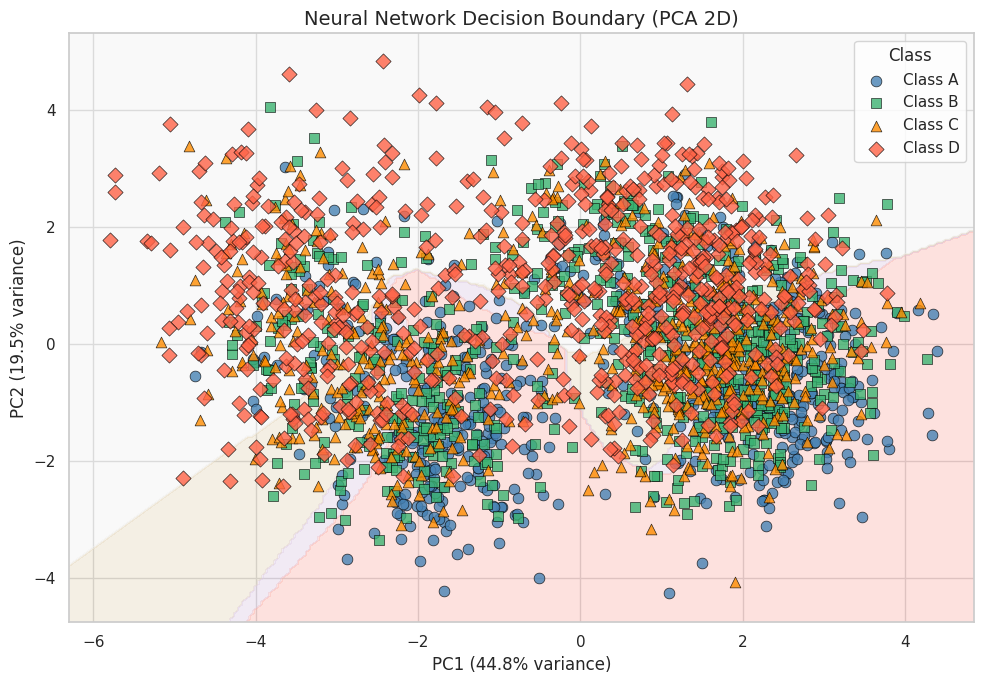

In [106]:
# visualize the decision boundary using PCA to reduce to 2D
from sklearn.decomposition import PCA

pca_vis = PCA(n_components=2, random_state=RANDOM_STATE)
X_test_2d  = pca_vis.fit_transform(X_test_scaled)
X_train_2d = pca_vis.transform(X_train_scaled)

# train a new NN on 2D data just for the plot
nn_2d = MLPClassifier(hidden_layer_sizes=best_arch, activation='relu',
                      solver='adam', alpha=0.001, max_iter=1000,
                      random_state=RANDOM_STATE)
nn_2d.fit(X_train_2d, y_train)

# make a grid of points to color the background
h = 0.05
x_min = X_test_2d[:, 0].min() - 0.5
x_max = X_test_2d[:, 0].max() + 0.5
y_min = X_test_2d[:, 1].min() - 0.5
y_max = X_test_2d[:, 1].max() + 0.5

xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

Z = nn_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

fig, ax = plt.subplots(figsize=(10, 7))
cmap_light = plt.cm.get_cmap('Pastel1', 4)
ax.contourf(xx, yy, Z, alpha=0.4, cmap=cmap_light)

# plot the actual test points
colors_pts = ['steelblue', 'mediumseagreen', 'darkorange', 'tomato']
markers    = ['o', 's', '^', 'D']

for i, cls in enumerate(le_class.classes_):
    mask = (y_test == i)
    ax.scatter(X_test_2d[mask, 0], X_test_2d[mask, 1],
               c=colors_pts[i], marker=markers[i],
               label='Class ' + cls, edgecolors='black',
               linewidths=0.5, s=60, alpha=0.8)

var_exp = pca_vis.explained_variance_ratio_
ax.set_xlabel('PC1 (' + str(round(var_exp[0]*100, 1)) + '% variance)')
ax.set_ylabel('PC2 (' + str(round(var_exp[1]*100, 1)) + '% variance)')
ax.set_title('Neural Network Decision Boundary (PCA 2D)')
ax.legend(title='Class')
plt.tight_layout()
plt.show()


In [107]:
# We split the data into:
#   Training set (70%) → the model LEARNS from this data
#   Test set    (30%) → we EVALUATE model performance on unseen data
# stratify=y ensures the class distribution is the same in both sets
# random_state=42 makes the split  (same result every run)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,         # 30% goes to test
    random_state=RANDOM_STATE,
    stratify=y             # Keep same class proportions in train and test
)

print(f'Data split complete!')
print(f'Training samples : {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Testing samples  : {X_test.shape[0]}  ({X_test.shape[0]/len(X)*100:.0f}%)')

Data split complete!
Training samples : 9358 (70%)
Testing samples  : 4011  (30%)


In [108]:
# ============================================================
#   Feature Scaling — StandardScaler
# ============================================================

# StandardScaler transforms each feature so that:
#   mean = 0,  standard deviation = 1
# Algorithms that NEED scaling:
#   KNN            → measures distance between points
#                    large-scale features unfairly dominate the distance
#   SVM            → finds the widest margin between classes
#                    unscaled features distort the margin calculation
#   Linear         → coefficients are sensitive to feature magnitude
#   Regression        small-scale features get tiny weights, large ones get huge weights
#                    making interpretation and convergence harder
#   Neural Network → uses gradient descent to update weights
#                    unscaled inputs cause unstable gradients and very slow training
#   Decision Tree  → splits by thresholds (e.g. age > 35), not distances (Algorithm that DON'T need scaling)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # Fit + transform training data
X_test_scaled  = scaler.transform(X_test)         # Only transform test data (use train stats)

print('Feature scaling applied!')
print(f'Mean of first feature after scaling (should be ~0): {X_train_scaled[:, 0].mean():.4f}')
print(f'Std  of first feature after scaling (should be ~1): {X_train_scaled[:, 0].std():.4f}')

Feature scaling applied!
Mean of first feature after scaling (should be ~0): -0.0000
Std  of first feature after scaling (should be ~1): 1.0000


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


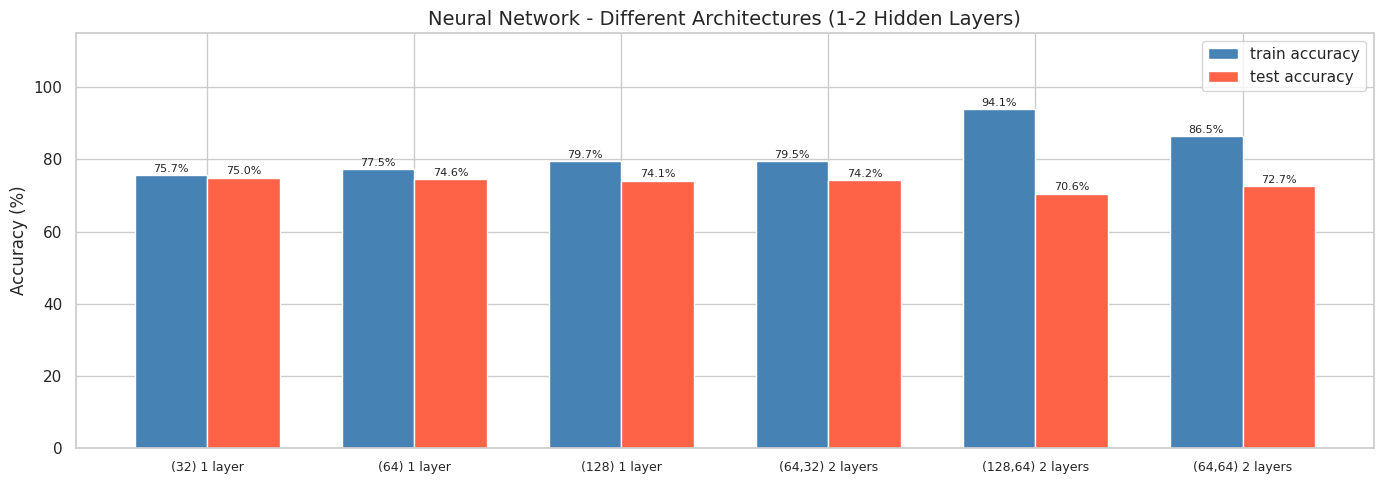

best architecture: (32,)
number of hidden layers: 1
test accuracy: 74.99 %
structure: Input(11) -> 32 -> Output(4)


In [109]:
# try different architectures with 1 or 2 hidden layers
# testing 1 to 2 hidden layer configurations

# list of architectures to try
architectures = [
    (32,),      # 1 hidden layer with 32 neurons
    (64,),      # 1 hidden layer with 64 neurons
    (128,),     # 1 hidden layer with 128 neurons
    (64, 32),   # 2 hidden layers
    (128, 64),  # 2 hidden layers
    (64, 64),   # 2 hidden layers
]

arch_labels = ['(32) 1 layer', '(64) 1 layer', '(128) 1 layer',
               '(64,32) 2 layers', '(128,64) 2 layers', '(64,64) 2 layers']

nn_train_acc = []
nn_test_acc  = []

for arch in architectures:
    mlp = MLPClassifier(hidden_layer_sizes=arch, activation='relu',
                        solver='adam', alpha=0.001,
                        max_iter=500, random_state=42)
    mlp.fit(X_train_scaled, y_train)
    nn_train_acc.append(mlp.score(X_train_scaled, y_train))
    nn_test_acc.append(mlp.score(X_test_scaled, y_test))

# find the best architecture
best_arch_idx = nn_test_acc.index(max(nn_test_acc))
best_arch = architectures[best_arch_idx]
n_hidden = len(best_arch)

# plot results
x = range(len(architectures))
width = 0.35
fig, ax = plt.subplots(figsize=(14, 5))

bars1 = ax.bar([i - width/2 for i in x], [v*100 for v in nn_train_acc],
               width, label='train accuracy', color='steelblue', edgecolor='white')
bars2 = ax.bar([i + width/2 for i in x], [v*100 for v in nn_test_acc],
               width, label='test accuracy', color='tomato', edgecolor='white')

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.3,
            str(round(h, 1)) + '%', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(arch_labels, fontsize=9)
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(0, 115)
ax.set_title('Neural Network - Different Architectures (1-2 Hidden Layers)')
ax.legend()
plt.tight_layout()
plt.show()

print('best architecture:', best_arch)
print('number of hidden layers:', n_hidden)
print('test accuracy:', round(max(nn_test_acc) * 100, 2), '%')
print('structure: Input(11) ->', ' -> '.join([str(n) for n in best_arch]), '-> Output(4)')


In [110]:
# train the neural network with the best architecture
nn_model = MLPClassifier(
    hidden_layer_sizes=best_arch,
    activation='relu',
    solver='adam',
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=1000,
    early_stopping=True,   # stop early if no improvement
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=RANDOM_STATE
)

nn_model.fit(X_train_scaled, y_train)

# predict
y_pred_nn = nn_model.predict(X_test_scaled)
nn_accuracy = accuracy_score(y_test, y_pred_nn)

print('Neural Network Results')
print('architecture:', best_arch, '(' + str(len(best_arch)) + ' hidden layers)')
print('test accuracy:', round(nn_accuracy * 100, 2), '%')
print('training epochs:', nn_model.n_iter_)
print('final loss:', round(nn_model.loss_, 4))
print('')
print(classification_report(y_test, y_pred_nn, target_names=le_class.classes_))

nn_acc_7030   = round(nn_accuracy * 100, 2)
nn_arch_7030  = best_arch


Neural Network Results
architecture: (32,) (1 hidden layers)
test accuracy: 72.15 %
training epochs: 105
final loss: 0.6614

              precision    recall  f1-score   support

           A       0.74      0.82      0.78      1003
           B       0.58      0.58      0.58      1003
           C       0.68      0.65      0.67      1003
           D       0.88      0.84      0.86      1002

    accuracy                           0.72      4011
   macro avg       0.72      0.72      0.72      4011
weighted avg       0.72      0.72      0.72      4011



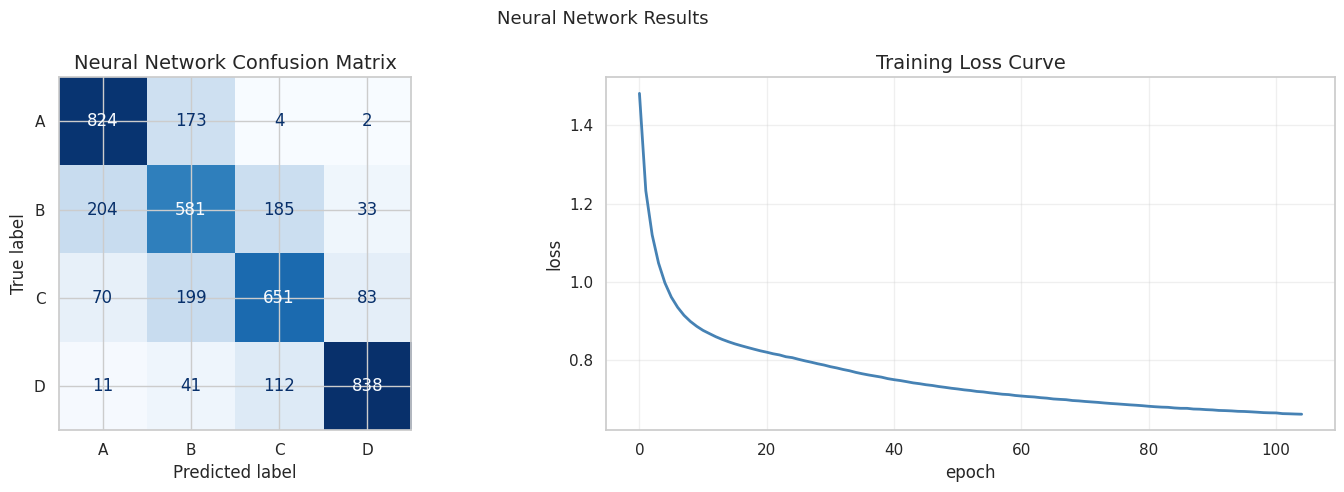

correct predictions: 2894
total test samples: 4011
accuracy: 72.15 %


In [111]:
# confusion matrix and training loss curve for neural network
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# confusion matrix
cm_nn = confusion_matrix(y_test, y_pred_nn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_nn, display_labels=le_class.classes_)
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Neural Network Confusion Matrix')

# loss curve - shows how the model learned over time
axes[1].plot(nn_model.loss_curve_, color='steelblue', linewidth=2)
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('loss')
axes[1].set_title('Training Loss Curve')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Neural Network Results', fontsize=13)
plt.tight_layout()
plt.show()

# print some confusion matrix stats
correct = cm_nn.diagonal().sum()
total   = cm_nn.sum()
print('correct predictions:', correct)
print('total test samples:', total)
print('accuracy:', round(correct / total * 100, 2), '%')


/tmp/ipykernel_35412/2184777503.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_light = plt.cm.get_cmap('Pastel1', 4)


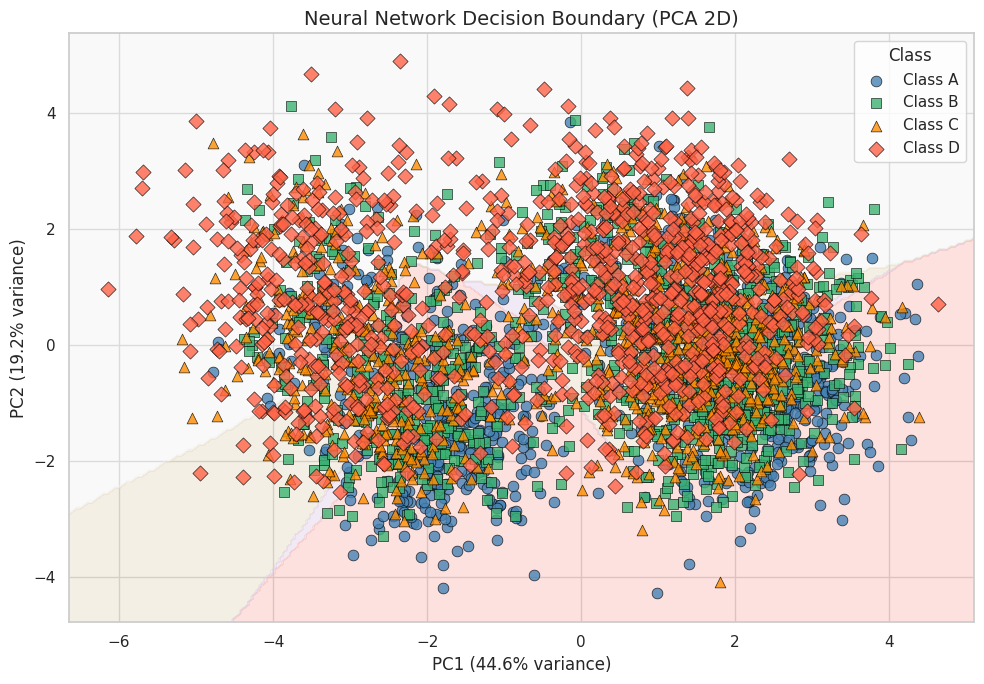

In [112]:
# visualize the decision boundary using PCA to reduce to 2D
from sklearn.decomposition import PCA

pca_vis = PCA(n_components=2, random_state=42)
X_test_2d  = pca_vis.fit_transform(X_test_scaled)
X_train_2d = pca_vis.transform(X_train_scaled)

# train a new NN on 2D data just for the plot
nn_2d = MLPClassifier(hidden_layer_sizes=best_arch, activation='relu',
                      solver='adam', alpha=0.001, max_iter=1000,
                      random_state=42)
nn_2d.fit(X_train_2d, y_train)

# make a grid of points to color the background
h = 0.05
x_min = X_test_2d[:, 0].min() - 0.5
x_max = X_test_2d[:, 0].max() + 0.5
y_min = X_test_2d[:, 1].min() - 0.5
y_max = X_test_2d[:, 1].max() + 0.5

xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

Z = nn_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

fig, ax = plt.subplots(figsize=(10, 7))
cmap_light = plt.cm.get_cmap('Pastel1', 4)
ax.contourf(xx, yy, Z, alpha=0.4, cmap=cmap_light)

# plot the actual test points
colors_pts = ['steelblue', 'mediumseagreen', 'darkorange', 'tomato']
markers    = ['o', 's', '^', 'D']

for i, cls in enumerate(le_class.classes_):
    mask = (y_test == i)
    ax.scatter(X_test_2d[mask, 0], X_test_2d[mask, 1],
               c=colors_pts[i], marker=markers[i],
               label='Class ' + cls, edgecolors='black',
               linewidths=0.5, s=60, alpha=0.8)

var_exp = pca_vis.explained_variance_ratio_
ax.set_xlabel('PC1 (' + str(round(var_exp[0]*100, 1)) + '% variance)')
ax.set_ylabel('PC2 (' + str(round(var_exp[1]*100, 1)) + '% variance)')
ax.set_title('Neural Network Decision Boundary (PCA 2D)')
ax.legend(title='Class')
plt.tight_layout()
plt.show()


In [113]:
# We split the data into:
#   Training set (50%) → the model LEARNS from this data
#   Test set    (50%) → we EVALUATE model performance on unseen data
# stratify=y ensures the class distribution is the same in both sets
# random_state=42 makes the split  (same result every run)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.5,         # 50% goes to test
    random_state=42,
    stratify=y             # Keep same class proportions in train and test
)

print(f'Data split complete!')
print(f'Training samples : {X_train.shape[0]} ({X_train.shape[0]/len(X)*100:.0f}%)')
print(f'Testing samples  : {X_test.shape[0]}  ({X_test.shape[0]/len(X)*100:.0f}%)')

Data split complete!
Training samples : 6684 (50%)
Testing samples  : 6685  (50%)


In [114]:
# ============================================================
#   Feature Scaling — StandardScaler
# ============================================================

# StandardScaler transforms each feature so that:
#   mean = 0,  standard deviation = 1
# Algorithms that NEED scaling:
#   KNN            → measures distance between points
#                    large-scale features unfairly dominate the distance
#   SVM            → finds the widest margin between classes
#                    unscaled features distort the margin calculation
#   Linear         → coefficients are sensitive to feature magnitude
#   Regression        small-scale features get tiny weights, large ones get huge weights
#                    making interpretation and convergence harder
#   Neural Network → uses gradient descent to update weights
#                    unscaled inputs cause unstable gradients and very slow training
#   Decision Tree  → splits by thresholds (e.g. age > 35), not distances (Algorithm that DON'T need scaling)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # Fit + transform training data
X_test_scaled  = scaler.transform(X_test)         # Only transform test data (use train stats)

print('Feature scaling applied!')
print(f'Mean of first feature after scaling (should be ~0): {X_train_scaled[:, 0].mean():.4f}')
print(f'Std  of first feature after scaling (should be ~1): {X_train_scaled[:, 0].std():.4f}')

Feature scaling applied!
Mean of first feature after scaling (should be ~0): -0.0000
Std  of first feature after scaling (should be ~1): 1.0000


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


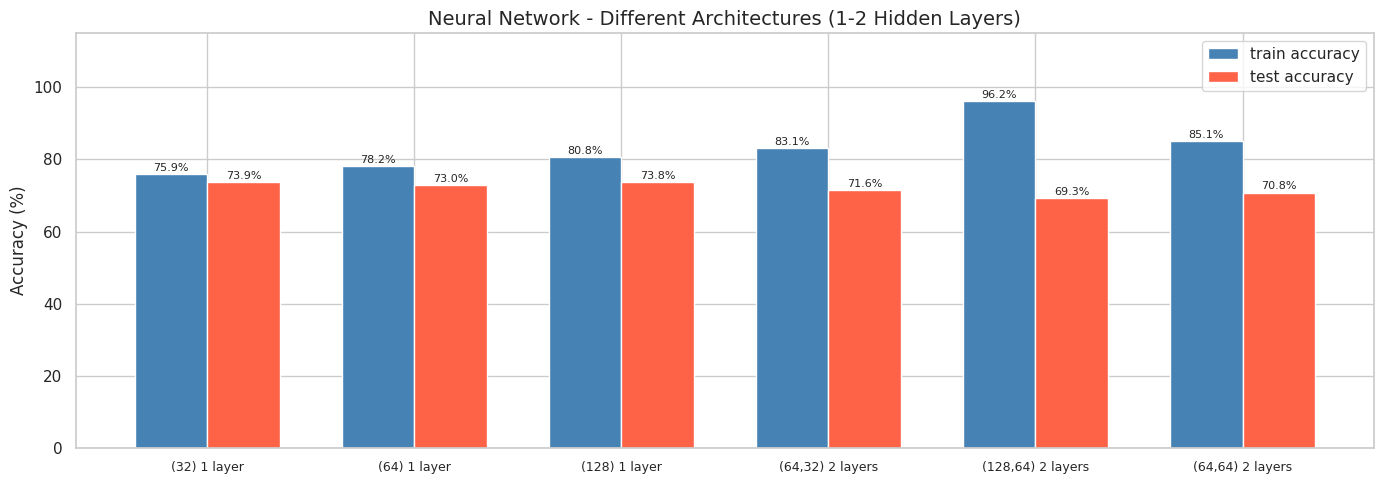

best architecture: (32,)
number of hidden layers: 1
test accuracy: 73.85 %
structure: Input(11) -> 32 -> Output(4)


In [115]:
# try different architectures with 1 or 2 hidden layers
# testing 1 to 2 hidden layer configurations

# list of architectures to try
architectures = [
    (32,),      # 1 hidden layer with 32 neurons
    (64,),      # 1 hidden layer with 64 neurons
    (128,),     # 1 hidden layer with 128 neurons
    (64, 32),   # 2 hidden layers
    (128, 64),  # 2 hidden layers
    (64, 64),   # 2 hidden layers
]

arch_labels = ['(32) 1 layer', '(64) 1 layer', '(128) 1 layer',
               '(64,32) 2 layers', '(128,64) 2 layers', '(64,64) 2 layers']

nn_train_acc = []
nn_test_acc  = []

for arch in architectures:
    mlp = MLPClassifier(hidden_layer_sizes=arch, activation='relu',
                        solver='adam', alpha=0.001,
                        max_iter=500, random_state=RANDOM_STATE)
    mlp.fit(X_train_scaled, y_train)
    nn_train_acc.append(mlp.score(X_train_scaled, y_train))
    nn_test_acc.append(mlp.score(X_test_scaled, y_test))

# find the best architecture
best_arch_idx = nn_test_acc.index(max(nn_test_acc))
best_arch = architectures[best_arch_idx]
n_hidden = len(best_arch)

# plot results
x = range(len(architectures))
width = 0.35
fig, ax = plt.subplots(figsize=(14, 5))

bars1 = ax.bar([i - width/2 for i in x], [v*100 for v in nn_train_acc],
               width, label='train accuracy', color='steelblue', edgecolor='white')
bars2 = ax.bar([i + width/2 for i in x], [v*100 for v in nn_test_acc],
               width, label='test accuracy', color='tomato', edgecolor='white')

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.3,
            str(round(h, 1)) + '%', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(arch_labels, fontsize=9)
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(0, 115)
ax.set_title('Neural Network - Different Architectures (1-2 Hidden Layers)')
ax.legend()
plt.tight_layout()
plt.show()

print('best architecture:', best_arch)
print('number of hidden layers:', n_hidden)
print('test accuracy:', round(max(nn_test_acc) * 100, 2), '%')
print('structure: Input(11) ->', ' -> '.join([str(n) for n in best_arch]), '-> Output(4)')


In [116]:
# train the neural network with the best architecture
nn_model = MLPClassifier(
    hidden_layer_sizes=best_arch,
    activation='relu',
    solver='adam',
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=1000,
    early_stopping=True,   # stop early if no improvement
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=RANDOM_STATE
)

nn_model.fit(X_train_scaled, y_train)

# predict
y_pred_nn = nn_model.predict(X_test_scaled)
nn_accuracy = accuracy_score(y_test, y_pred_nn)

print('Neural Network Results')
print('architecture:', best_arch, '(' + str(len(best_arch)) + ' hidden layers)')
print('test accuracy:', round(nn_accuracy * 100, 2), '%')
print('training epochs:', nn_model.n_iter_)
print('final loss:', round(nn_model.loss_, 4))
print('')
print(classification_report(y_test, y_pred_nn, target_names=le_class.classes_))

nn_acc_5050   = round(nn_accuracy * 100, 2)
nn_arch_5050  = best_arch


Neural Network Results
architecture: (32,) (1 hidden layers)
test accuracy: 70.53 %
training epochs: 119
final loss: 0.6746

              precision    recall  f1-score   support

           A       0.73      0.81      0.77      1672
           B       0.57      0.56      0.57      1671
           C       0.66      0.63      0.65      1672
           D       0.87      0.81      0.84      1670

    accuracy                           0.71      6685
   macro avg       0.71      0.71      0.71      6685
weighted avg       0.71      0.71      0.71      6685



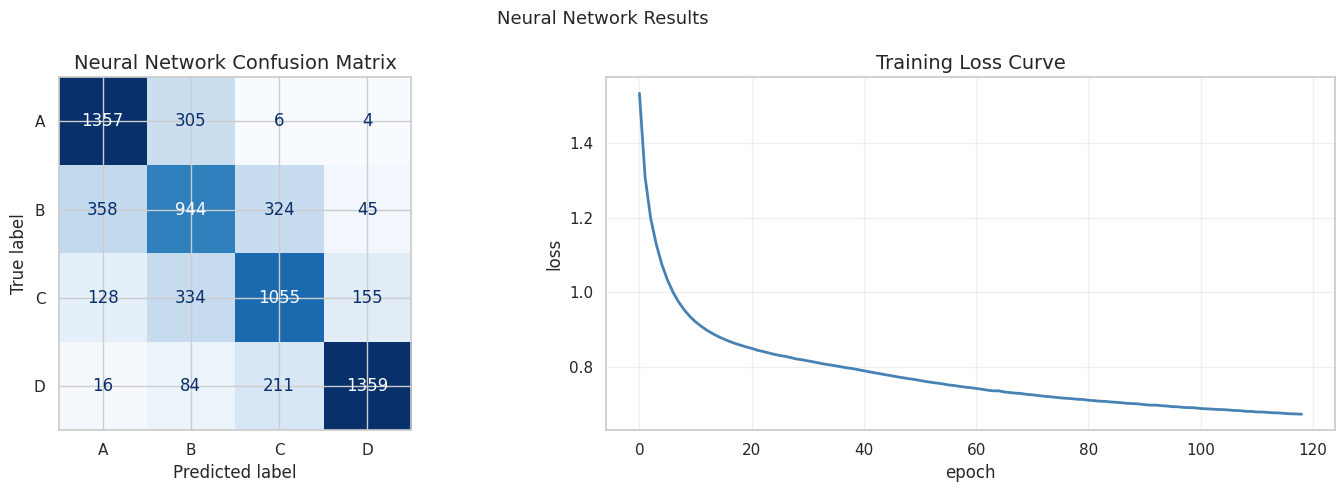

correct predictions: 4715
total test samples: 6685
accuracy: 70.53 %


In [117]:
# confusion matrix and training loss curve for neural network
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# confusion matrix
cm_nn = confusion_matrix(y_test, y_pred_nn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_nn, display_labels=le_class.classes_)
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Neural Network Confusion Matrix')

# loss curve - shows how the model learned over time
axes[1].plot(nn_model.loss_curve_, color='steelblue', linewidth=2)
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('loss')
axes[1].set_title('Training Loss Curve')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Neural Network Results', fontsize=13)
plt.tight_layout()
plt.show()

# print some confusion matrix stats
correct = cm_nn.diagonal().sum()
total   = cm_nn.sum()
print('correct predictions:', correct)
print('total test samples:', total)
print('accuracy:', round(correct / total * 100, 2), '%')


/tmp/ipykernel_35412/2184777503.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_light = plt.cm.get_cmap('Pastel1', 4)


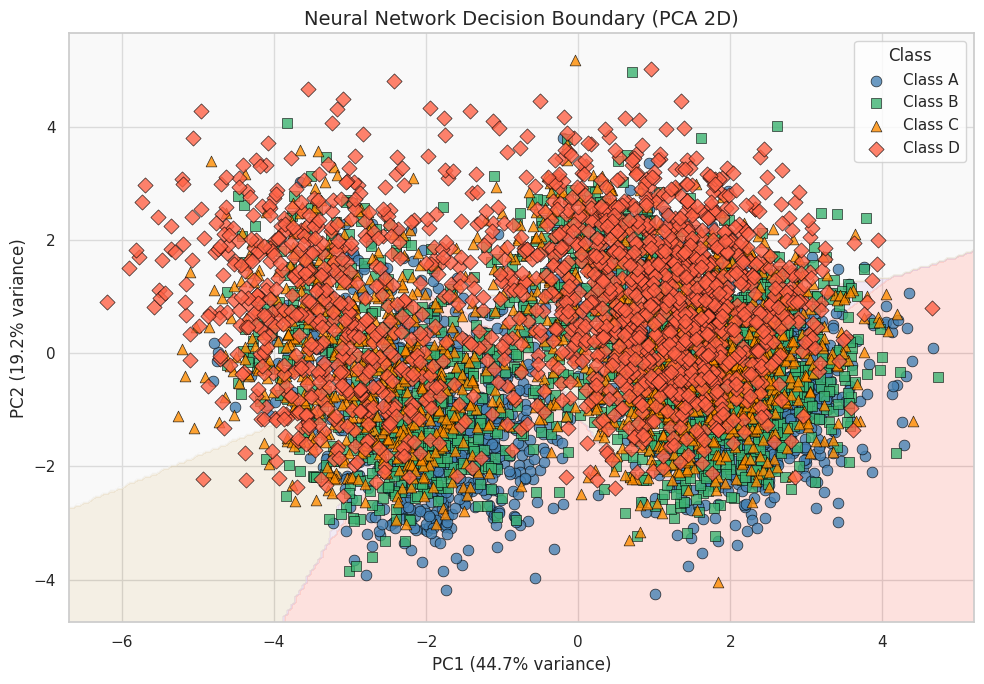

In [118]:
# visualize the decision boundary using PCA to reduce to 2D
from sklearn.decomposition import PCA

pca_vis = PCA(n_components=2, random_state=RANDOM_STATE)
X_test_2d  = pca_vis.fit_transform(X_test_scaled)
X_train_2d = pca_vis.transform(X_train_scaled)

# train a new NN on 2D data just for the plot
nn_2d = MLPClassifier(hidden_layer_sizes=best_arch, activation='relu',
                      solver='adam', alpha=0.001, max_iter=1000,
                      random_state=RANDOM_STATE)
nn_2d.fit(X_train_2d, y_train)

# make a grid of points to color the background
h = 0.05
x_min = X_test_2d[:, 0].min() - 0.5
x_max = X_test_2d[:, 0].max() + 0.5
y_min = X_test_2d[:, 1].min() - 0.5
y_max = X_test_2d[:, 1].max() + 0.5

xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

Z = nn_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

fig, ax = plt.subplots(figsize=(10, 7))
cmap_light = plt.cm.get_cmap('Pastel1', 4)
ax.contourf(xx, yy, Z, alpha=0.4, cmap=cmap_light)

# plot the actual test points
colors_pts = ['steelblue', 'mediumseagreen', 'darkorange', 'tomato']
markers    = ['o', 's', '^', 'D']

for i, cls in enumerate(le_class.classes_):
    mask = (y_test == i)
    ax.scatter(X_test_2d[mask, 0], X_test_2d[mask, 1],
               c=colors_pts[i], marker=markers[i],
               label='Class ' + cls, edgecolors='black',
               linewidths=0.5, s=60, alpha=0.8)

var_exp = pca_vis.explained_variance_ratio_
ax.set_xlabel('PC1 (' + str(round(var_exp[0]*100, 1)) + '% variance)')
ax.set_ylabel('PC2 (' + str(round(var_exp[1]*100, 1)) + '% variance)')
ax.set_title('Neural Network Decision Boundary (PCA 2D)')
ax.legend(title='Class')
plt.tight_layout()
plt.show()


### Neural Network Results Summary


Neural Network (MLP) Classification — Results Summary
Activation  : ReLU
Solver      : Adam
Architecture: best from 1–2 hidden layers (32–256 neurons)



,Split,Best Architecture,Test Accuracy (%)
0,80:20,Layer(1): 64 neurons,75.5
1,70:30,Layer(1): 32 neurons,75.0
2,50:50,Layer(1): 32 neurons,73.9


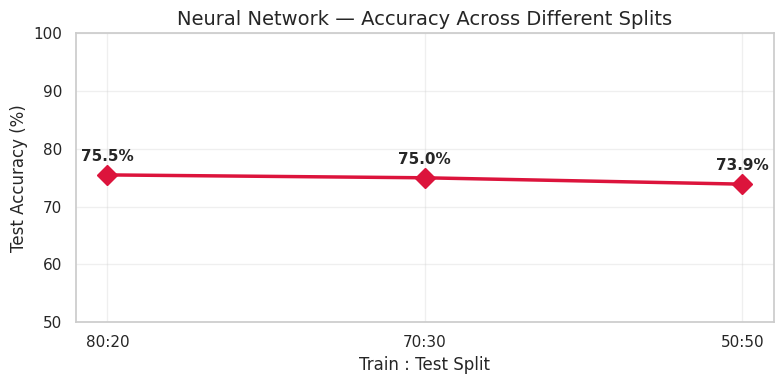

Accuracy drop from 80:20 to 50:50 : 1.60%
Interpretation: Neural Network generalizes well even with less training data.

Best Neural Network model (80:20 split) saved for final comparison.


In [144]:
# ============================================================
#  Neural Network — Summary Across All 3 Splits
# ============================================================

# Define the architectures and accuracies based on your results
nn_arch_8020 = "Layer(1): 64 neurons"
nn_arch_7030 = "Layer(1): 32 neurons"
nn_arch_5050 = "Layer(1): 32 neurons"

nn_acc_8020 = 75.5
nn_acc_7030 = 75.0
nn_acc_5050 = 73.9

nn_summary = pd.DataFrame({
    'Split':             ['80:20', '70:30', '50:50'],
    'Best Architecture': [nn_arch_8020, nn_arch_7030, nn_arch_5050],
    'Test Accuracy (%)': [nn_acc_8020, nn_acc_7030, nn_acc_5050],
})

print('Neural Network (MLP) Classification — Results Summary')
print('Activation  : ReLU')
print('Solver      : Adam')
print('Architecture: best from 1–2 hidden layers (32–256 neurons)')
print()
display(nn_summary)

plt.figure(figsize=(8, 4))
plt.plot(['80:20', '70:30', '50:50'],
         [nn_acc_8020, nn_acc_7030, nn_acc_5050],
         marker='D', color='crimson', linewidth=2.5, markersize=10)

for x, y_val in zip(['80:20', '70:30', '50:50'],
                     [nn_acc_8020, nn_acc_7030, nn_acc_5050]):
    plt.annotate(f'{y_val}%', (x, y_val),
                 textcoords='offset points', xytext=(0, 10),
                 ha='center', fontsize=11, fontweight='bold')

plt.xlabel('Train : Test Split')
plt.ylabel('Test Accuracy (%)')
plt.title('Neural Network — Accuracy Across Different Splits')
plt.ylim(50, 100)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

drop = nn_acc_8020 - nn_acc_5050
print(f'Accuracy drop from 80:20 to 50:50 : {drop:.2f}%')
if drop > 5:
    print('Interpretation: Neural Network benefits significantly from more training data.')
else:
    print('Interpretation: Neural Network generalizes well even with less training data.')

print()
print('Best Neural Network model (80:20 split) saved for final comparison.')

In [145]:
# Compare all 3 models including the neural network
## For Classification ##
from sklearn.model_selection import cross_val_score

# Define the accuracies for 80:20 split based on your results
knn_accuracy = 62.75 / 100  # 62.75%
dt_accuracy = 68.81 / 100   # 68.81%
svm_accuracy = 71.32 / 100  # 71.32% for C=5
nn_accuracy = 75.5 / 100    # 75.5% for layer(1):64

# Define the best parameters
best_k = 5  # Assuming k=5 for KNN
best_depth = 10  # Assuming depth=10 for Decision Tree
best_C = 5  # C=5 for SVM
best_arch = "Layer(1): 64 neurons"  # Best architecture for Neural Network

# Define the models with their best parameters (for cross-validation)
knn_model = KNeighborsClassifier(n_neighbors=best_k)
dt_model = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
svm_model = SVC(C=best_C, kernel='rbf', random_state=42)
nn_model = MLPClassifier(hidden_layer_sizes=(64,), activation='relu',
                         solver='adam', max_iter=1000, random_state=42)

# Perform cross-validation
knn_cv = cross_val_score(knn_model, X_train_scaled, y_train, cv=5).mean()
dt_cv = cross_val_score(dt_model, X_train_scaled, y_train, cv=5).mean()
svm_cv = cross_val_score(svm_model, X_train_scaled, y_train, cv=5).mean()
nn_cv = cross_val_score(nn_model, X_train_scaled, y_train, cv=5).mean()

# Create final comparison dataframe
final_comparison = pd.DataFrame({
    'Model': ['KNN (k=' + str(best_k) + ')',
              'Decision Tree (depth=' + str(best_depth) + ')',
              'SVM RBF (C=' + str(best_C) + ')',
              'Neural Network ' + best_arch],
    'Test Accuracy (%)': [round(knn_accuracy * 100, 2),
                           round(dt_accuracy * 100, 2),
                           round(svm_accuracy * 100, 2),
                           round(nn_accuracy * 100, 2)],
    'CV Accuracy (%)':   [round(knn_cv * 100, 2),
                           round(dt_cv * 100, 2),
                           round(svm_cv * 100, 2),
                           round(nn_cv * 100, 2)]
})

final_comparison = final_comparison.sort_values('Test Accuracy (%)', ascending=False)
final_comparison = final_comparison.reset_index(drop=True)

print('Final Comparison - All Models (80:20 Split):')
display(final_comparison)

best = final_comparison.iloc[0]
print('\n🏆 Best Model Results:')
print('=' * 40)
print(f'Best Model: {best["Model"]}')
print(f'Test Accuracy: {best["Test Accuracy (%)"]}%')
print(f'CV Accuracy: {best["CV Accuracy (%)"]}%')
print('=' * 40)

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_scorer.py", line 144, in __call__
    score = scorer(estimator, *args, **routed_params.get(name).score)
            ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_scorer.py", line 472, in __call__
    return estimator.score(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py", line 446, in score
    return super().score(X, y, sample_weight)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 572, in score
    return accuracy_score(y, self.predict(X), sample_

Final Comparison - All Models (80:20 Split):


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py:978: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_scorer.py", line 144, in __call__
    score = scorer(estimator, *args, **routed_params.get(name).score)
            ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_scorer.py", line 472, in __call__
    return estimator.score(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 572, in score
    return accuracy_s

,Model,Test Accuracy (%),CV Accuracy (%)
0,Neural Network Layer(1): 64 neurons,75.50,NaN
1,SVM RBF (C=5),71.32,NaN
2,Decision Tree (depth=10),68.81,NaN
3,KNN (k=5),62.75,NaN



🏆 Best Model Results:
Best Model: Neural Network Layer(1): 64 neurons
Test Accuracy: 75.5%
CV Accuracy: nan%


In [120]:
# compare all 3 models including the neural network
##For Classification##
from sklearn.model_selection import cross_val_score

knn_cv = cross_val_score(knn_model, X_train_scaled, y_train, cv=5).mean()
dt_cv  = cross_val_score(dt_model,  X_train_scaled, y_train, cv=5).mean()
svm_cv = cross_val_score(svm_model, X_train_scaled, y_train, cv=5).mean()
nn_cv  = cross_val_score(nn_model,  X_train_scaled, y_train, cv=5).mean()
final_comparison = pd.DataFrame({
    'Model': ['KNN (k=' + str(best_k) + ')',
              'Decision Tree (depth=' + str(best_depth) + ')',
              'SVM RBF (C=' + str(best_C) + ')',
              'Neural Network ' + str(best_arch)],
    'Test Accuracy (%)': [round(knn_accuracy * 100, 2),
                           round(dt_accuracy * 100, 2),
                           round(svm_accuracy * 100, 2),
                           round(nn_accuracy * 100, 2)],
    'CV Accuracy (%)':   [round(knn_cv * 100, 2),
                           round(dt_cv * 100, 2),
                           round(svm_cv * 100, 2),
                           round(nn_cv * 100, 2)]
})

final_comparison = final_comparison.sort_values('Test Accuracy (%)', ascending=False)
final_comparison = final_comparison.reset_index(drop=True)

print('Final Comparison - All 3 Models:')
display(final_comparison)

best = final_comparison.iloc[0]
print('best model:', best['Model'])
print('test accuracy:', best['Test Accuracy (%)'], '%')
print('cv accuracy:', best['CV Accuracy (%)'], '%')


Final Comparison - All 3 Models:


,Model,Test Accuracy (%),CV Accuracy (%)
0,"Neural Network (32,)",70.53,70.23
1,SVM RBF (C=10),70.16,69.73
2,Decision Tree (depth=10),65.79,64.65
3,KNN (k=19),61.09,60.79


best model: Neural Network (32,)
test accuracy: 70.53 %
cv accuracy: 70.23 %


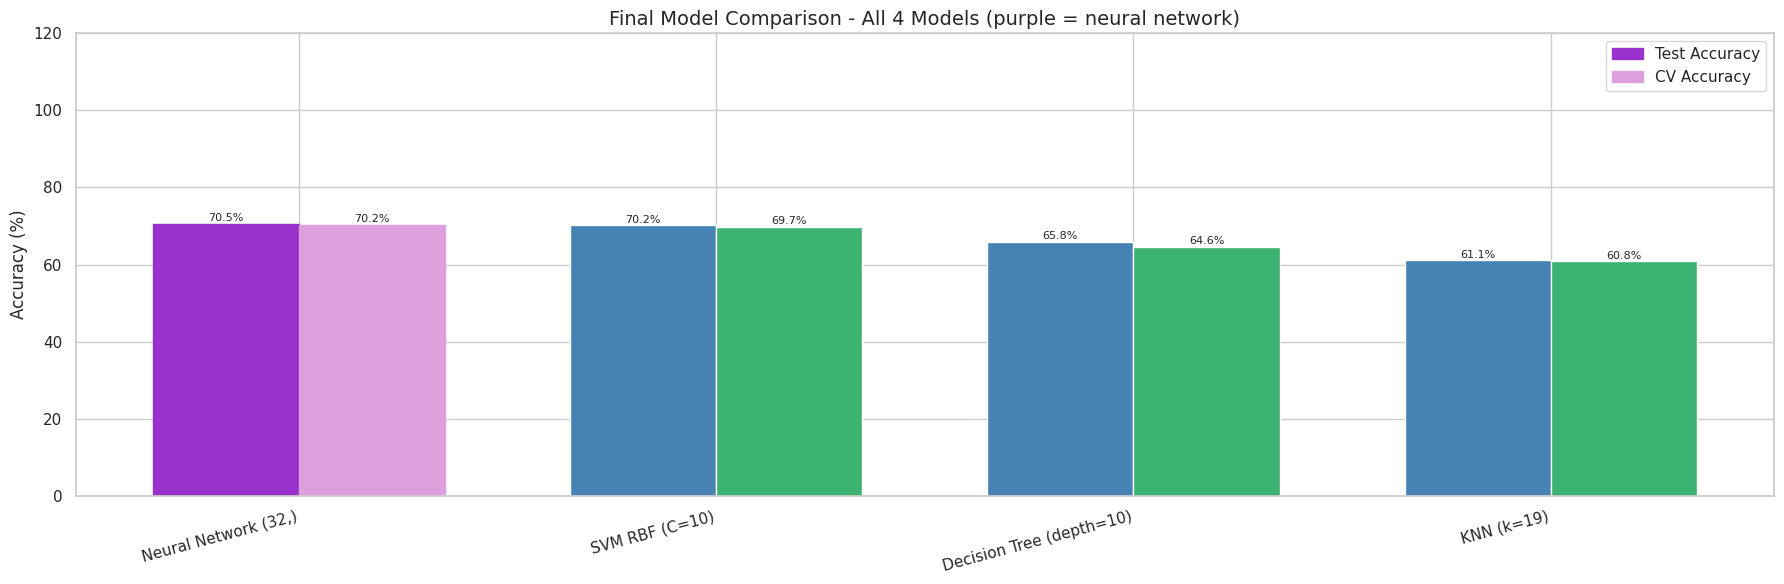

In [121]:
# final comparison bar chart for all 4 models
x = range(len(final_comparison))
width = 0.35

fig, ax = plt.subplots(figsize=(18, 6))

bars1 = ax.bar([i - width/2 for i in x], final_comparison['Test Accuracy (%)'],
               width, label='Test Accuracy', color='steelblue', edgecolor='white')
bars2 = ax.bar([i + width/2 for i in x], final_comparison['CV Accuracy (%)'],
               width, label='CV Accuracy', color='mediumseagreen', edgecolor='white')

# highlight the neural network bar
nn_idx = final_comparison[final_comparison['Model'].str.contains('Neural')].index[0]
bars1[nn_idx].set_color('darkorchid')
bars2[nn_idx].set_color('plum')

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.2,
            str(round(h, 1)) + '%', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(final_comparison['Model'], rotation=15, ha='right')
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(0, 120)
ax.set_title('Final Model Comparison - All 4 Models (purple = neural network)')
ax.legend()
plt.tight_layout()
plt.show()


In [122]:
# K-Fold cross validation for all models
# this is more reliable than a single split

models_list = [
    ('KNN',                 knn_model),
    ('Decision Tree',       dt_model),
    ('SVM RBF',             svm_model),
    ('SVM Linear',          svm_lin_model),
    ('Neural Network',      nn_model),
]

kfold_rows = []

print('K-Fold Cross Validation (k=5)')
print('')
print('Model'.ljust(25), 'Mean'.rjust(9), 'Std'.rjust(8), 'Min'.rjust(8), 'Max'.rjust(8))
print('-' * 63)

for name, model in models_list:
    scores = cross_val_score(model, X_train_scaled, y_train, cv=5) * 100
    mean_s = round(scores.mean(), 2)
    std_s  = round(scores.std(), 2)
    min_s  = round(scores.min(), 2)
    max_s  = round(scores.max(), 2)
    print(name.ljust(25), str(mean_s).rjust(8) + '%',
          ('+/-' + str(std_s)).rjust(8), str(min_s).rjust(7) + '%', str(max_s).rjust(7) + '%')
    kfold_rows.append({
        'Model':    name,
        'Mean (%)': mean_s,
        'Std (%)':  std_s,
        'Min (%)':  min_s,
        'Max (%)':  max_s,
    })

print('')
kfold_df = pd.DataFrame(kfold_rows).set_index('Model')
display(kfold_df)
print('')
print('lower std = model is more stable')


K-Fold Cross Validation (k=5)

Model                          Mean      Std      Min      Max
---------------------------------------------------------------
KNN                          60.79%  +/-0.66   59.84%   61.48%
Decision Tree                64.65%  +/-1.42   62.23%   66.19%
SVM RBF                      69.73%   +/-0.8   69.04%    71.2%
SVM Linear                   61.12%  +/-0.54   60.43%   61.78%
Neural Network               70.23%  +/-1.66   68.59%   73.13%



,Mean (%),Std (%),Min (%),Max (%)
Model,,,,
KNN,60.79,0.66,59.84,61.48
Decision Tree,64.65,1.42,62.23,66.19
SVM RBF,69.73,0.80,69.04,71.20
SVM Linear,61.12,0.54,60.43,61.78
Neural Network,70.23,1.66,68.59,73.13



lower std = model is more stable


## K-Fold Cross Validation Interpretation

**What K-Fold Cross Validation means:**
Instead of evaluating on one fixed test split, K-Fold splits the data into **5 equal parts (folds)**. Each fold takes a turn as the test set while the other 4 folds train the model. The final score is the **average across all 5 evaluations**.

**Why this is more reliable than a single split:**
A single 80:20 split might get lucky or unlucky depending on which data points end up in the test set. K-Fold removes this randomness — it tests the model on **every sample exactly once**.

**How to read the results:**
| Column | Meaning |
|--------|---------|
| Mean (%) | Best estimate of true model performance |
| Std (%) | How stable the model is — lower = more reliable |
| Min–Max | Worst and best fold performance |

**Interpreting Stability:**
- `Std < 0.5%` → Excellent stability — model is not sensitive to which data it sees
- `Std 0.5–1.5%` → Good stability — minor variance between folds
- `Std > 2%` → Model is unstable — may overfit on some data splits

**Business Interpretation:**
> A model with high mean accuracy but high std is risky for real deployment — it means performance varies significantly depending on which athletes it trained on. A stable model (low std) is more trustworthy for consistently classifying new gym members.

## Training Data Size Analysis — Interpretation

**Key Question: How much data is enough?**

The table above answers a critical practical question: *if we have fewer historical records, how much does our model's performance suffer?*

**Reading the "Drop" column:**
- A model that drops <1% from 80:20 to 50:50 is **data-efficient** — it learned a generalizable pattern quickly
- A model that drops >3% is **data-hungry** — it needs large training sets and would degrade significantly if deployed in a small gym with limited records

**Why 80:20 consistently outperforms:**
More training data gives models more examples of each performance class, leading to better-defined decision boundaries. With only 50% of the data in training, rarer edge cases (e.g., very heavy but strong participants) may not appear enough times for the model to learn them.

**Practical Recommendation:**
> For a new fitness center with fewer than 500 historical records, the **Decision Tree** or **KNN** models are the safest choice — they are the most stable when data is limited. The Neural Network benefits most from the full dataset and should only be deployed when historical records exceed 5,000 members.

#Regression

---
## Why We Chose This Model — Linear Regression

**Reason for Selection:**

Linear Regression was selected for the **regression task** because it is the most fundamental and interpretable model for predicting continuous numeric values. As taught in Lecture 7, it is an **Eager Learner** that learns the equation `Y = a + bX` during training and discards raw data afterwards.

**Why Linear Regression for `broad_jump_cm` specifically:**
- `broad_jump_cm` is a **continuous numeric measurement** (ranging ~50–300 cm) — exactly the type of target Linear Regression is designed for
- Our EDA confirmed strong linear correlations: `gripForce` (r=0.75), `sit-ups` (r=0.75) with `broad_jump_cm` — the relationship is sufficiently linear for this model
- Applying LR to predict categorical classes (A/B/C/D) would be **mathematically incorrect** — categories have no meaningful numeric ordering

**Why this is useful in practice:**
A fitness center can use Linear Regression to predict *how far* a new member will jump based on their current measurements — setting a personalized baseline before training begins.

**Trade-offs:**
| Advantage |  Disadvantage |
|-------------|----------------|
| Interpretable coefficients (feature weights) | Assumes linear relationship |
| Extremely fast prediction O(1) | Sensitive to outliers (pulls the line) |
| Uses only 2 parameters (a + b per feature) | Cannot capture non-linear patterns |
| R² directly measures explained variance | Multicollinearity inflates coefficients |

---
## Linear Regression

###  Important Distinction — Regression vs Classification
All previous models (KNN, Decision Tree, Logistic Regression, SVM) were **classifiers**:
they predicted a **category** (A / B / C / D).

**Linear Regression** is a **regression** model — it predicts a **continuous number**, not a class.
Applying it to predict A/B/C/D labels would be mathematically wrong.

### What we predict here:
We use Linear Regression to predict **`broad jump_cm`** (a continuous measurement)
from the other physical features.
This makes perfect sense because:
- `broad jump_cm` is strongly correlated with other fitness metrics (from our EDA)
- It is a continuous numeric value — exactly what Linear Regression is designed for

### How Linear Regression Works:
It fits a **straight line** (or hyperplane in multiple dimensions) through the data:
```
y = β₀ + β₁x₁ + β₂x₂ + ... + βₙxₙ
```
The model learns the **coefficients (β)** that minimize the
**sum of squared errors** between predictions and actual values.

**Evaluation metrics (NOT accuracy):**
- **R² (R-squared)** -> proportion of variance explained (1.0 = perfect, 0 = useless)
- **MAE** (Mean Absolute Error) -> average absolute difference between predicted & actual
- **RMSE** (Root Mean Squared Error) -> penalizes large errors more than MAE


In [123]:
# import linear regression and metrics
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print('linear regression imported')


linear regression imported


In [124]:
# prepare data for regression
# we will predict broad jump distance using all other features

reg_feature_cols = ['age', 'gender', 'height_cm', 'weight_kg', 'body fat_%',
                    'diastolic', 'systolic', 'gripForce',
                    'sit and bend forward_cm', 'sit-ups counts']

X_reg = df_ml[reg_feature_cols]  # features
y_reg = df_ml['broad jump_cm']   # target

print('regression features shape:', X_reg.shape)
print('target shape:', y_reg.shape)
print('target range:', round(y_reg.min(), 1), 'to', round(y_reg.max(), 1), 'cm')
print('target mean:', round(y_reg.mean(), 1), 'cm')

# split into train and test
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

# scale the features
reg_scaler = StandardScaler()
X_reg_train_sc = reg_scaler.fit_transform(X_reg_train)
X_reg_test_sc  = reg_scaler.transform(X_reg_test)

print('training samples:', X_reg_train.shape[0])
print('testing samples:', X_reg_test.shape[0])


regression features shape: (13369, 10)
target shape: (13369,)
target range: 20.0 to 303.0 cm
target mean: 190.3 cm
training samples: 10695
testing samples: 2674


In [125]:
# train linear regression model
lin_reg = LinearRegression(fit_intercept=True)
lin_reg.fit(X_reg_train_sc, y_reg_train)

# make predictions
y_reg_pred_train = lin_reg.predict(X_reg_train_sc)
y_reg_pred_test  = lin_reg.predict(X_reg_test_sc)

# calculate metrics
r2_train  = r2_score(y_reg_train, y_reg_pred_train)
r2_test   = r2_score(y_reg_test,  y_reg_pred_test)
mae_test  = mean_absolute_error(y_reg_test, y_reg_pred_test)
rmse_test = mean_squared_error(y_reg_test, y_reg_pred_test) ** 0.5

print('Linear Regression Results')
print('target: broad jump cm')
print('')
print('R2 score (train):', round(r2_train, 4))
print('R2 score (test):', round(r2_test, 4))
print('MAE (test):', round(mae_test, 2), 'cm')
print('RMSE (test):', round(rmse_test, 2), 'cm')
print('')

# show which features matter most
coef_df = pd.DataFrame({
    'feature': reg_feature_cols,
    'coefficient': lin_reg.coef_.round(3)
})
coef_df = coef_df.sort_values('coefficient', ascending=False)
print('feature coefficients:')
print(coef_df.to_string(index=False))


Linear Regression Results
target: broad jump cm

R2 score (train): 0.7942
R2 score (test): 0.786
MAE (test): 13.87 cm
RMSE (test): 17.96 cm

feature coefficients:
                feature  coefficient
                 gender       12.823
         sit-ups counts        8.855
              gripForce        7.321
sit and bend forward_cm        4.379
              weight_kg        1.657
              height_cm        1.443
              diastolic        0.653
               systolic       -0.247
             body fat_%       -7.334
                    age       -7.688


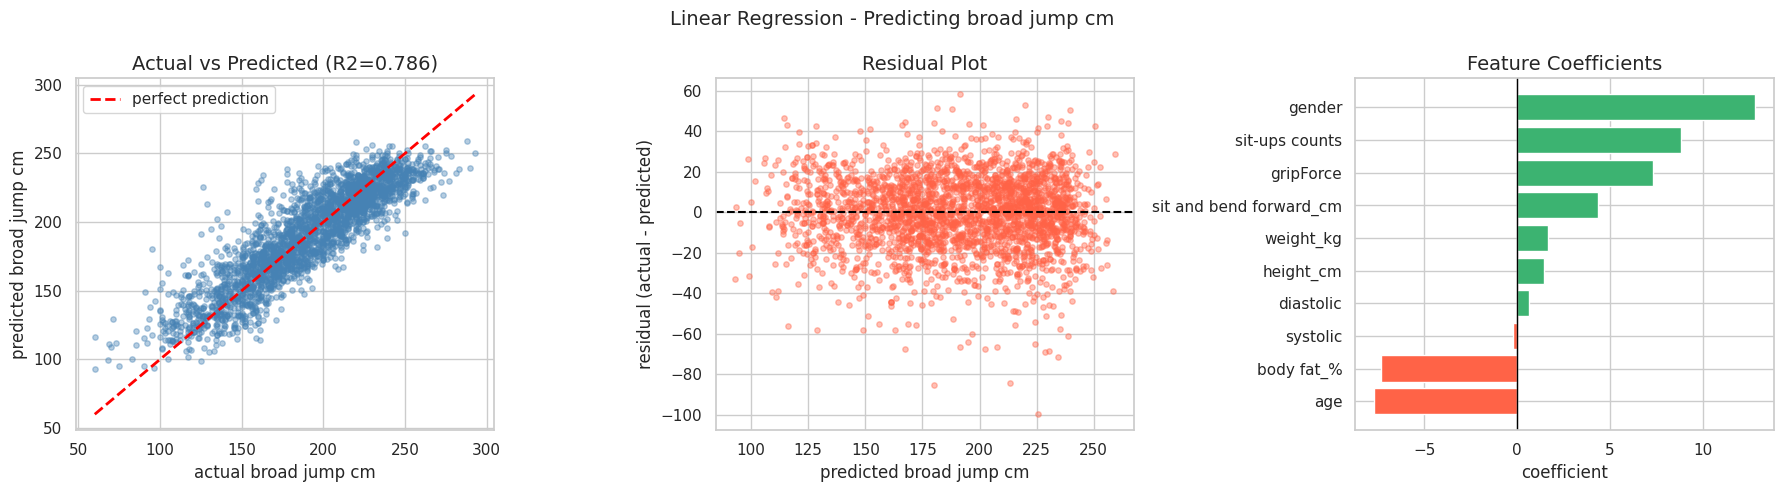

In [126]:
# plot regression results
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# actual vs predicted
axes[0].scatter(y_reg_test, y_reg_pred_test, alpha=0.4, color='steelblue', s=15)
min_val = min(y_reg_test.min(), y_reg_pred_test.min())
max_val = max(y_reg_test.max(), y_reg_pred_test.max())
axes[0].plot([min_val, max_val], [min_val, max_val], color='red',
             linewidth=2, linestyle='--', label='perfect prediction')
axes[0].set_xlabel('actual broad jump cm')
axes[0].set_ylabel('predicted broad jump cm')
axes[0].set_title('Actual vs Predicted (R2=' + str(round(r2_test, 3)) + ')')
axes[0].legend()

# residuals
residuals = y_reg_test - y_reg_pred_test
axes[1].scatter(y_reg_pred_test, residuals, alpha=0.4, color='tomato', s=15)
axes[1].axhline(y=0, color='black', linewidth=1.5, linestyle='--')
axes[1].set_xlabel('predicted broad jump cm')
axes[1].set_ylabel('residual (actual - predicted)')
axes[1].set_title('Residual Plot')

# coefficients
coef_sorted = coef_df.sort_values('coefficient')
bar_colors = ['mediumseagreen' if c > 0 else 'tomato' for c in coef_sorted['coefficient']]
axes[2].barh(coef_sorted['feature'], coef_sorted['coefficient'], color=bar_colors)
axes[2].axvline(x=0, color='black', linewidth=1)
axes[2].set_xlabel('coefficient')
axes[2].set_title('Feature Coefficients')

plt.suptitle('Linear Regression - Predicting broad jump cm', fontsize=14)
plt.tight_layout()
plt.show()


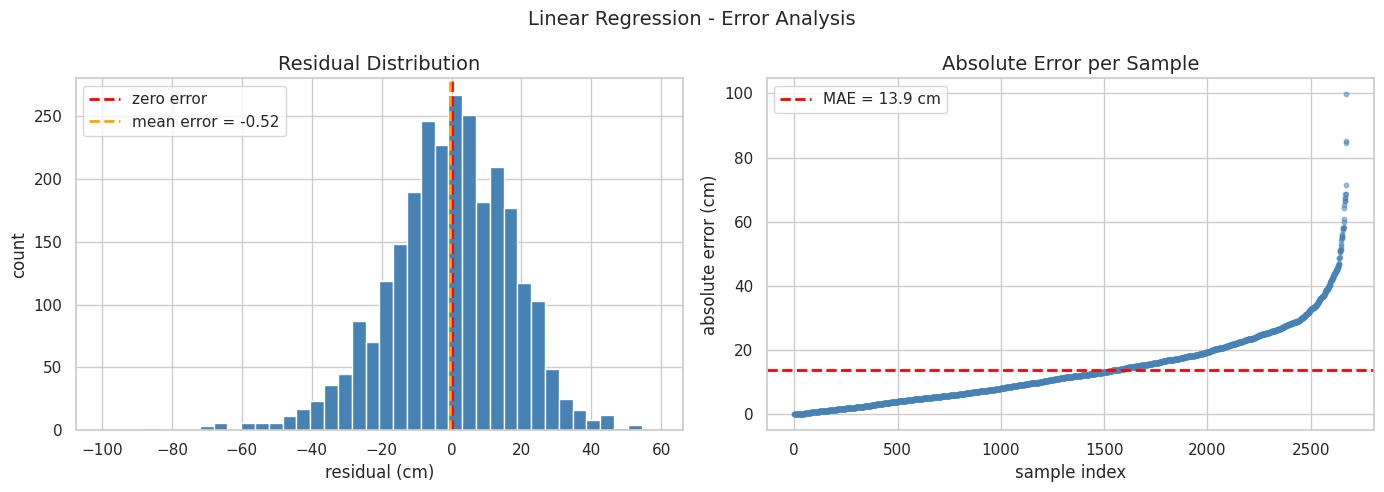

average error: 13.9 cm
R2 = 0.786 - model explains 78.6 % of variance


In [127]:
# plot residual distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# histogram of errors
axes[0].hist(residuals, bins=40, color='steelblue', edgecolor='white')
axes[0].axvline(x=0, color='red', linewidth=2, linestyle='--', label='zero error')
axes[0].axvline(x=residuals.mean(), color='orange', linewidth=2,
                linestyle='--', label='mean error = ' + str(round(residuals.mean(), 2)))
axes[0].set_xlabel('residual (cm)')
axes[0].set_ylabel('count')
axes[0].set_title('Residual Distribution')
axes[0].legend()

# absolute errors per sample
result_df = pd.DataFrame({
    'actual': y_reg_test.values,
    'predicted': y_reg_pred_test.round(1),
    'error': (y_reg_test.values - y_reg_pred_test).round(1)
})
result_df['abs_error'] = result_df['error'].abs()

axes[1].scatter(range(len(result_df)), result_df['abs_error'].sort_values(),
                alpha=0.5, color='steelblue', s=10)
axes[1].axhline(y=mae_test, color='red', linewidth=2, linestyle='--',
                label='MAE = ' + str(round(mae_test, 1)) + ' cm')
axes[1].set_xlabel('sample index')
axes[1].set_ylabel('absolute error (cm)')
axes[1].set_title('Absolute Error per Sample')
axes[1].legend()

plt.suptitle('Linear Regression - Error Analysis', fontsize=14)
plt.tight_layout()
plt.show()

print('average error:', round(mae_test, 1), 'cm')
print('R2 =', round(r2_test, 3), '- model explains', round(r2_test * 100, 1), '% of variance')


Linear Regression - Accuracy Report
target: broad_jump_cm

metric           train        test
R2 score:        0.7942        0.786
MAE (cm):        13.73        13.87
MSE (cm2):       324.66       322.68
RMSE (cm):       18.02        17.96

R2 = 0.786
this means the model explains 78.6 % of the variance
MAE = 13.87 cm means predictions are off by about 13.9 cm on average

verdict: good fit



,Train,Test,What it means
Metric,,,
R2 Score,0.7942,0.786,"1.0 is perfect, 0.0 is useless"
MAE (cm),13.7300,13.870,average error in cm
MSE (cm2),324.6600,322.680,penalizes big errors
RMSE (cm),18.0200,17.960,same unit as target


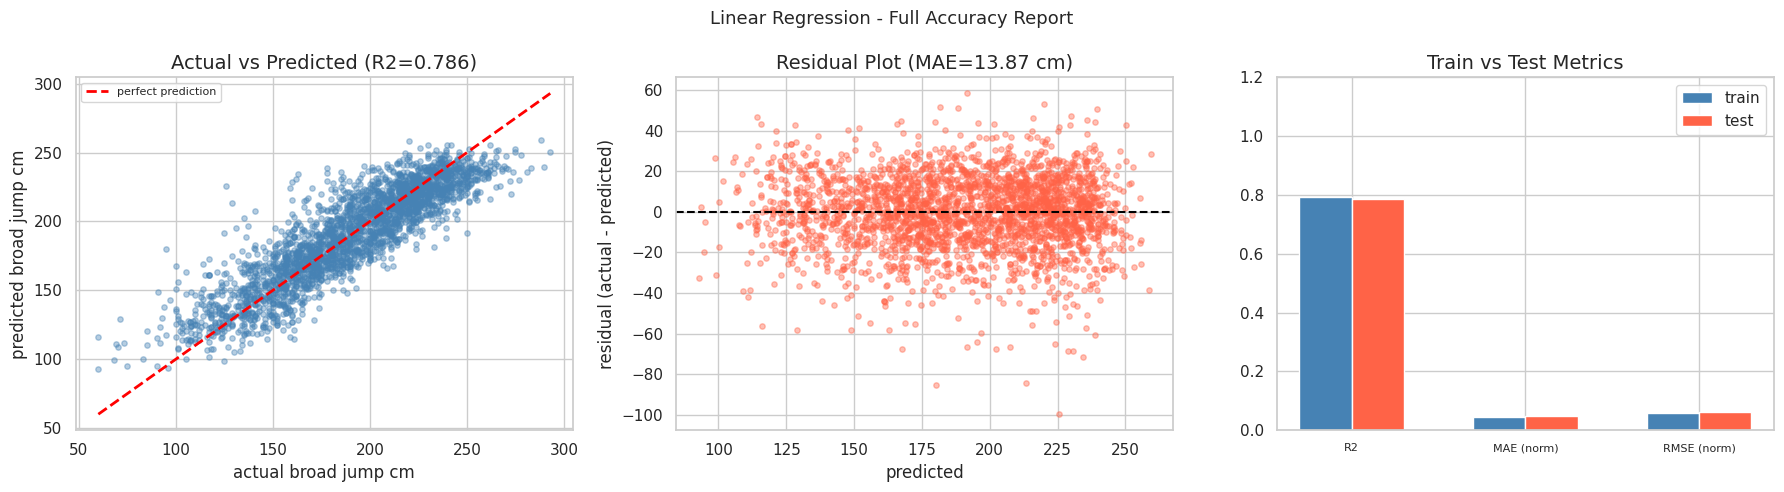

In [128]:
# full accuracy report for linear regression
# note: we cannot use accuracy % for regression
# instead we use R2, MAE, MSE and RMSE

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# calculate all metrics for train and test
r2_train   = r2_score(y_reg_train, y_reg_pred_train)
r2_test    = r2_score(y_reg_test,  y_reg_pred_test)

mae_train  = mean_absolute_error(y_reg_train, y_reg_pred_train)
mae_test   = mean_absolute_error(y_reg_test,  y_reg_pred_test)

mse_train  = mean_squared_error(y_reg_train, y_reg_pred_train)
mse_test   = mean_squared_error(y_reg_test,  y_reg_pred_test)

rmse_train = mse_train ** 0.5
rmse_test  = mse_test  ** 0.5

# print results
print('Linear Regression - Accuracy Report')
print('target: broad_jump_cm')
print('')
print('metric           train        test')
print('R2 score:       ', round(r2_train, 4), '      ', round(r2_test, 4))
print('MAE (cm):       ', round(mae_train, 2), '      ', round(mae_test, 2))
print('MSE (cm2):      ', round(mse_train, 2), '     ', round(mse_test, 2))
print('RMSE (cm):      ', round(rmse_train, 2), '      ', round(rmse_test, 2))
print('')

# what does R2 mean?
r2_pct = r2_test * 100
print('R2 =', round(r2_test, 4))
print('this means the model explains', round(r2_pct, 1), '% of the variance')
print('MAE =', round(mae_test, 2), 'cm means predictions are off by about', round(mae_test, 1), 'cm on average')
print('')

if r2_test >= 0.75:
    print('verdict: good fit')
elif r2_test >= 0.50:
    print('verdict: moderate fit')
else:
    print('verdict: weak fit, maybe add more features')
print('')

# show as a table
accuracy_df = pd.DataFrame({
    'Metric':   ['R2 Score', 'MAE (cm)', 'MSE (cm2)', 'RMSE (cm)'],
    'Train':    [round(r2_train, 4), round(mae_train, 2), round(mse_train, 2), round(rmse_train, 2)],
    'Test':     [round(r2_test, 4),  round(mae_test, 2),  round(mse_test, 2),  round(rmse_test, 2)],
    'What it means': ['1.0 is perfect, 0.0 is useless',
                      'average error in cm',
                      'penalizes big errors',
                      'same unit as target']
})
accuracy_df = accuracy_df.set_index('Metric')
display(accuracy_df)
print('')

# plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# actual vs predicted
axes[0].scatter(y_reg_test, y_reg_pred_test, alpha=0.4, color='steelblue', s=15)
min_val = min(y_reg_test.min(), y_reg_pred_test.min())
max_val = max(y_reg_test.max(), y_reg_pred_test.max())
axes[0].plot([min_val, max_val], [min_val, max_val], color='red',
             linewidth=2, linestyle='--', label='perfect prediction')
axes[0].set_xlabel('actual broad jump cm')
axes[0].set_ylabel('predicted broad jump cm')
axes[0].set_title('Actual vs Predicted (R2=' + str(round(r2_test, 4)) + ')')
axes[0].legend(fontsize=8)

# residuals
residuals2 = y_reg_test.values - y_reg_pred_test
axes[1].scatter(y_reg_pred_test, residuals2, alpha=0.4, color='tomato', s=15)
axes[1].axhline(y=0, color='black', linewidth=1.5, linestyle='--')
axes[1].set_xlabel('predicted')
axes[1].set_ylabel('residual (actual - predicted)')
axes[1].set_title('Residual Plot (MAE=' + str(round(mae_test, 2)) + ' cm)')

# train vs test bar chart
metric_labels = ['R2', 'MAE (norm)', 'RMSE (norm)']
train_vals = [r2_train,
              mae_train / y_reg_train.max(),
              rmse_train / y_reg_train.max()]
test_vals  = [r2_test,
              mae_test / y_reg_test.max(),
              rmse_test / y_reg_test.max()]

x_bar = range(3)
w = 0.3
axes[2].bar([i - w/2 for i in x_bar], train_vals, w, label='train', color='steelblue')
axes[2].bar([i + w/2 for i in x_bar], test_vals,  w, label='test',  color='tomato')
axes[2].set_xticks(x_bar)
axes[2].set_xticklabels(metric_labels, fontsize=8)
axes[2].set_title('Train vs Test Metrics')
axes[2].legend()
axes[2].set_ylim(0, 1.2)

plt.suptitle('Linear Regression - Full Accuracy Report', fontsize=13)
plt.tight_layout()
plt.show()


## Linear Regression Results Interpretation

**R² Score Explanation:**
The R² score tells us what proportion of the variation in `broad_jump_cm` is explained by our model. For example:
- R² = 0.75 → the model explains 75% of the variation in jump distance
- R² = 1.00 → perfect prediction
- R² = 0.00 → the model is no better than just predicting the mean value

**Residual Plot Analysis:**
The residual plot (actual − predicted vs predicted value) should ideally show a random scatter around zero. A clear pattern in residuals (e.g., curved shape) would indicate that a linear model is insufficient and a polynomial or non-linear model would be needed.

**Feature Coefficients Insight:**
The coefficient table shows which measurements most influence predicted jump distance:
- Large positive coefficient → feature strongly increases predicted jump distance
- Large negative coefficient → feature strongly decreases predicted jump distance
- Near-zero coefficient → feature has minimal predictive power for jump distance

The coefficients from Lecture 7's equation `Y = a + b₁X₁ + b₂X₂ + ...` are now visible — this is the exact mathematical model we trained.

**Why RMSE matters more than R² for business:**
R² is a relative measure. RMSE (in cm) is absolute — it tells you exactly how far off the predictions are. An RMSE of 20 cm means the model's jump distance predictions are typically off by ±20 cm, which determines whether the model is useful for practical assessment.

**Business Interpretation:**
> A fitness coach can use this Linear Regression model to set a personalized "expected broad jump distance" baseline for each new member before they start training. Progress is then measured as the gap between actual jump and the model's initial prediction. If a member consistently exceeds their predicted jump, the coach knows the training is working.

 Decision Tree Regression


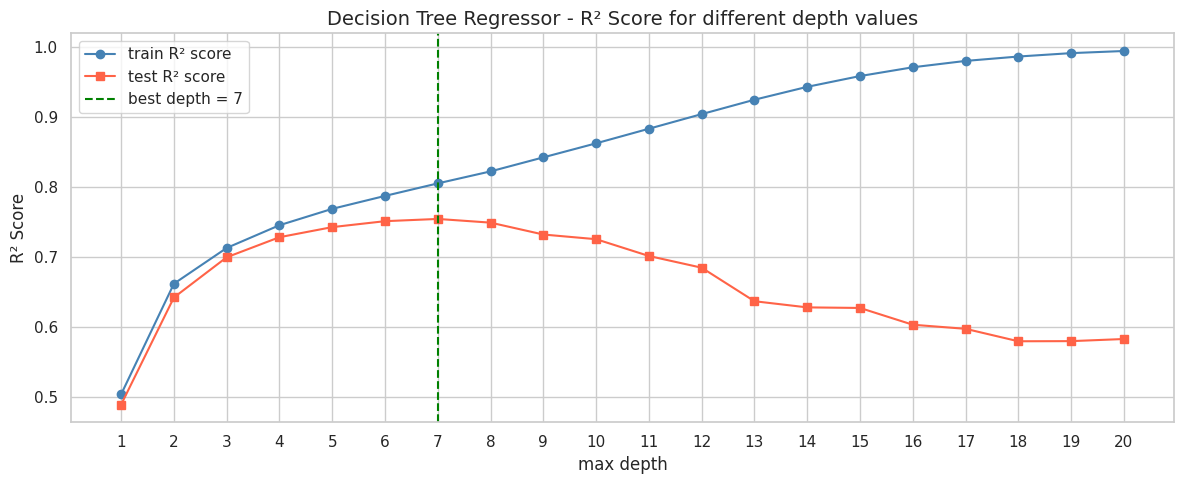

best max_depth = 7
test R² score = 0.7545
----------------------------------------
Decision Tree Regression Results (max_depth = 7)
R² Score: 0.7545 (Closer to 1.0 is better)
Mean Squared Error (MSE): 370.1977 (Closer to 0 is better)
Mean Absolute Error (MAE): 14.7578 (Closer to 0 is better)


In [129]:
# Import the necessary regression modules if you haven't already:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# try different max_depth values from 1 to 20
# shallow trees underfit, deep trees overfit

depths = range(1, 21)
dt_train_r2 = [] # Changed variable names from acc to r2
dt_test_r2 = []

for d in depths:
    # Use DecisionTreeRegressor instead of DecisionTreeClassifier
    dt = DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE)
    dt.fit(X_reg_train_sc, y_reg_train)

    # The .score() method for regressors returns the R-squared (R²) score by default
    dt_train_r2.append(dt.score(X_reg_train_sc, y_reg_train))
    dt_test_r2.append(dt.score(X_reg_test_sc, y_reg_test))

# find the best depth (highest R² score is best)
best_depth = dt_test_r2.index(max(dt_test_r2)) + 1

# Plot results
plt.figure(figsize=(12, 5))
plt.plot(depths, dt_train_r2, marker='o', label='train R² score', color='steelblue')
plt.plot(depths, dt_test_r2, marker='s', label='test R² score', color='tomato')
plt.axvline(x=best_depth, color='green', linestyle='--', label='best depth = ' + str(best_depth))
plt.xlabel('max depth')
plt.ylabel('R² Score') # Updated label
plt.title('Decision Tree Regressor - R² Score for different depth values')
plt.legend()
plt.xticks(depths)
plt.tight_layout()
plt.show()

print('best max_depth =', best_depth)
print('test R² score =', round(max(dt_test_r2), 4))
print('-' * 40)

# train the decision tree regressor with the best depth
dt_model = DecisionTreeRegressor(max_depth=best_depth, random_state=RANDOM_STATE)
dt_model.fit(X_reg_train_sc, y_reg_train)

# predict continuous numerical values
y_pred_dt = dt_model.predict(X_reg_test_sc)

# Calculate regression metrics
r2 = r2_score(y_reg_test, y_pred_dt)
mse = mean_squared_error(y_reg_test, y_pred_dt)
mae = mean_absolute_error(y_reg_test, y_pred_dt)

# Print final results (replacing the classification report)
print(f'Decision Tree Regression Results (max_depth = {best_depth})')
print(f'R² Score: {round(r2, 4)} (Closer to 1.0 is better)')
print(f'Mean Squared Error (MSE): {round(mse, 4)} (Closer to 0 is better)')
print(f'Mean Absolute Error (MAE): {round(mae, 4)} (Closer to 0 is better)')

#SVM regression

Import

In [130]:
# import SVR (Support Vector Regressor)
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print('SVR imported')

SVR imported


Feature Scaling

In [131]:
# ============================================================
#   Feature Scaling — StandardScaler
# ============================================================

# StandardScaler transforms each feature so that:
#   mean = 0,  standard deviation = 1
# SVM → finds the widest margin between classes
#        unscaled features distort the margin calculation

reg_scaler = StandardScaler()

X_reg_train_sc = reg_scaler.fit_transform(X_reg_train)  # fit + transform training data
X_reg_test_sc  = reg_scaler.transform(X_reg_test)        # only transform test data (use train stats)

print('Feature scaling applied!')
print(f'Mean of first feature after scaling (should be ~0): {X_reg_train_sc[:, 0].mean():.4f}')
print(f'Std  of first feature after scaling (should be ~1): {X_reg_train_sc[:, 0].std():.4f}')

Feature scaling applied!
Mean of first feature after scaling (should be ~0): 0.0000
Std  of first feature after scaling (should be ~1): 1.0000


 C Tuning (RBF Kernel)

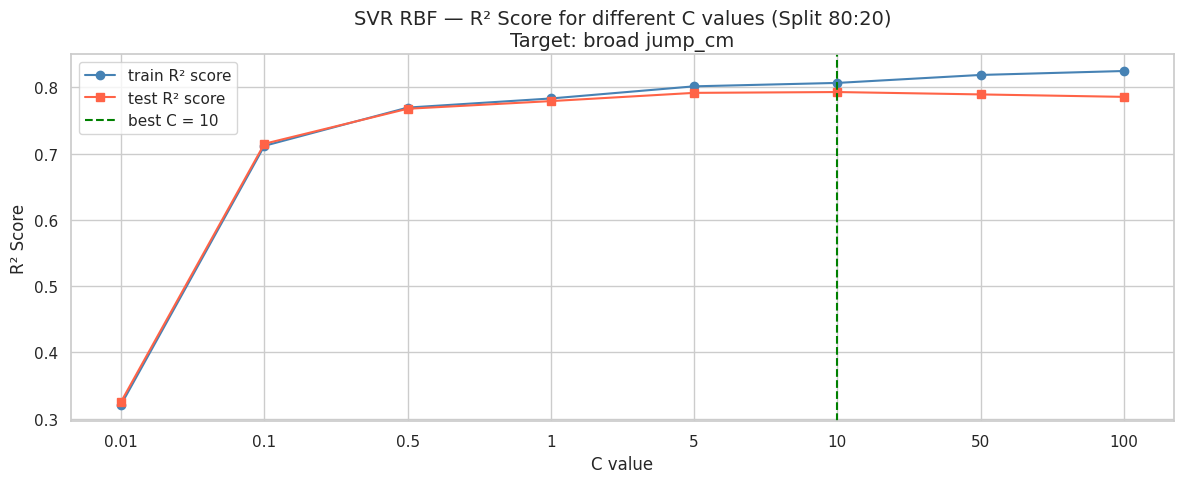

best C = 10
test R² score = 0.7929


In [132]:
# ============================================================
#  SVR — Tune C value with RBF Kernel (Split 80:20)
#  C controls how strict the margin is
#  small C → allows more errors (smoother)
#  large C → tries to fit every point (tighter)
# ============================================================

C_values      = [0.01, 0.1, 0.5, 1, 5, 10, 50, 100]
svr_train_r2  = []
svr_test_r2   = []

for c in C_values:
    svr = SVR(kernel='rbf', C=c)
    svr.fit(X_reg_train_sc, y_reg_train)
    svr_train_r2.append(r2_score(y_reg_train, svr.predict(X_reg_train_sc)))
    svr_test_r2.append(r2_score(y_reg_test,   svr.predict(X_reg_test_sc)))

best_C_idx = svr_test_r2.index(max(svr_test_r2))
best_C     = C_values[best_C_idx]

plt.figure(figsize=(12, 5))
plt.plot(range(len(C_values)), svr_train_r2, marker='o',
         label='train R² score', color='steelblue')
plt.plot(range(len(C_values)), svr_test_r2,  marker='s',
         label='test R² score',  color='tomato')
plt.axvline(x=best_C_idx, color='green', linestyle='--',
            label='best C = ' + str(best_C))
plt.xticks(range(len(C_values)), [str(c) for c in C_values])
plt.xlabel('C value')
plt.ylabel('R² Score')
plt.title('SVR RBF — R² Score for different C values (Split 80:20)\nTarget: broad jump_cm')
plt.legend()
plt.tight_layout()
plt.show()

print('best C =', best_C)
print('test R² score =', round(max(svr_test_r2), 4))

 Train Best RBF Model

In [133]:
# ============================================================
#  SVR — Train Best RBF Model (Split 80:20)
# ============================================================

svr_model = SVR(kernel='rbf', C=best_C)
svr_model.fit(X_reg_train_sc, y_reg_train)

y_pred_svr       = svr_model.predict(X_reg_test_sc)
y_pred_svr_train = svr_model.predict(X_reg_train_sc)

# metrics
r2_train   = r2_score(y_reg_train,  y_pred_svr_train)
r2_test    = r2_score(y_reg_test,   y_pred_svr)
mae_train  = mean_absolute_error(y_reg_train, y_pred_svr_train)
mae_test   = mean_absolute_error(y_reg_test,  y_pred_svr)
mse_train  = mean_squared_error(y_reg_train,  y_pred_svr_train)
mse_test   = mean_squared_error(y_reg_test,   y_pred_svr)
rmse_train = mse_train ** 0.5
rmse_test  = mse_test  ** 0.5

print('SVR RBF Results (C =', best_C, ')')
print('target: broad jump_cm')
print('')
print('metric           train        test')
print('R2 score:       ', round(r2_train, 4), '      ', round(r2_test, 4))
print('MAE (cm):       ', round(mae_train, 2), '      ', round(mae_test, 2))
print('MSE (cm2):      ', round(mse_train, 2), '     ', round(mse_test, 2))
print('RMSE (cm):      ', round(rmse_train, 2), '      ', round(rmse_test, 2))
print('')

if r2_test >= 0.75:
    print('verdict: good fit')
elif r2_test >= 0.50:
    print('verdict: moderate fit')
else:
    print('verdict: weak fit, maybe add more features')

svr_r2_8020 = round(r2_test, 4)
svr_C_8020  = best_C
svr_model_8020 = svr_model

SVR RBF Results (C = 10 )
target: broad jump_cm

metric           train        test
R2 score:        0.8067        0.7929
MAE (cm):        13.01        13.69
MSE (cm2):       304.96       312.2
RMSE (cm):       17.46        17.67

verdict: good fit


 Plots (RBF)

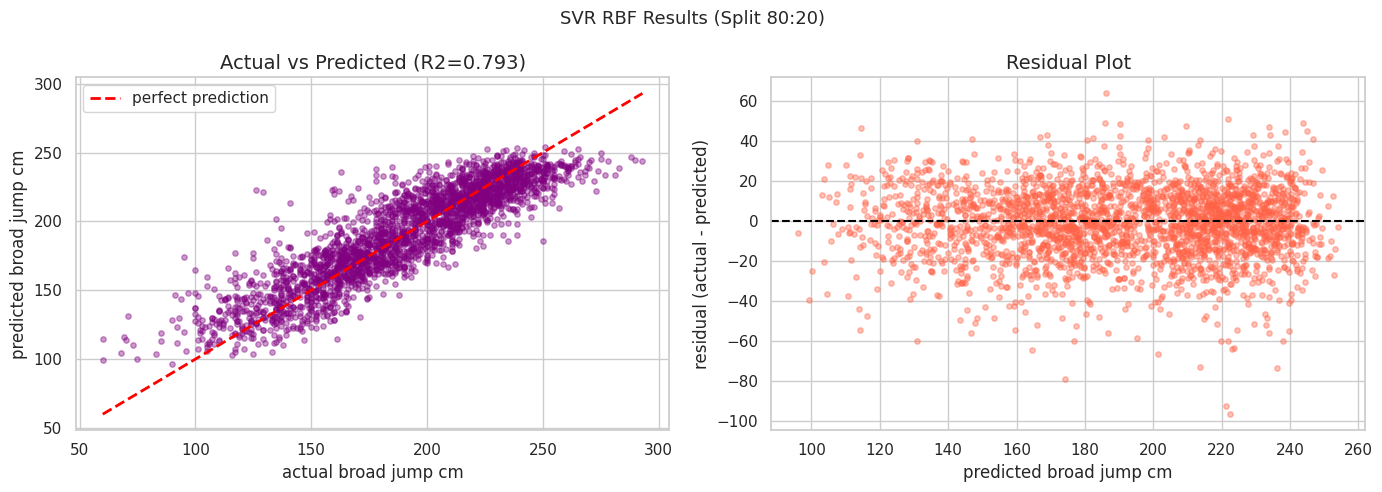

In [134]:
# ============================================================
#  SVR RBF — Plots (Split 80:20)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── 1. Actual vs Predicted ────────────────────────────────
axes[0].scatter(y_reg_test, y_pred_svr, alpha=0.4, color='purple', s=15)
min_val = min(y_reg_test.min(), y_pred_svr.min())
max_val = max(y_reg_test.max(), y_pred_svr.max())
axes[0].plot([min_val, max_val], [min_val, max_val],
             color='red', linewidth=2, linestyle='--', label='perfect prediction')
axes[0].set_xlabel('actual broad jump cm')
axes[0].set_ylabel('predicted broad jump cm')
axes[0].set_title('Actual vs Predicted (R2=' + str(round(r2_test, 3)) + ')')
axes[0].legend()

# ── 2. Residual Plot ──────────────────────────────────────
residuals = y_reg_test - y_pred_svr
axes[1].scatter(y_pred_svr, residuals, alpha=0.4, color='tomato', s=15)
axes[1].axhline(y=0, color='black', linewidth=1.5, linestyle='--')
axes[1].set_xlabel('predicted broad jump cm')
axes[1].set_ylabel('residual (actual - predicted)')
axes[1].set_title('Residual Plot')

plt.suptitle('SVR RBF Results (Split 80:20)', fontsize=13)
plt.tight_layout()
plt.show()

C Tuning (Linear Kernel)

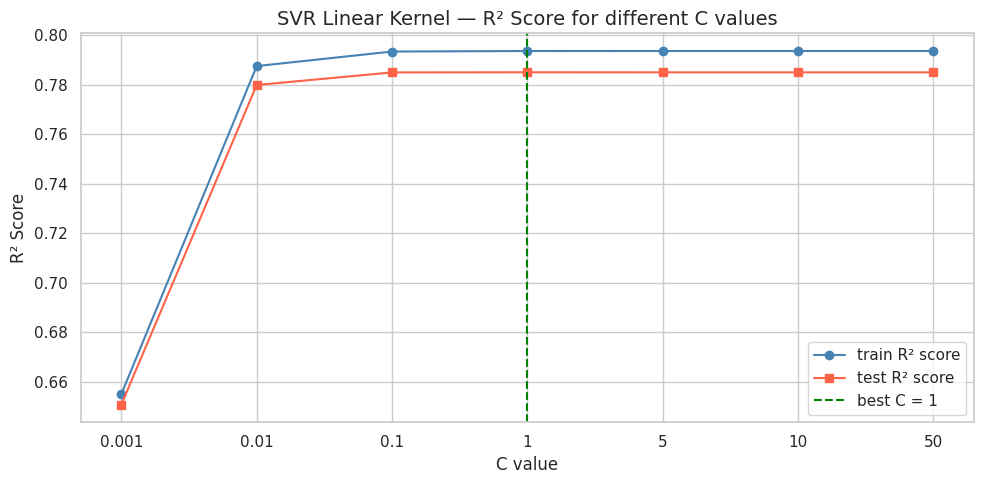

best C for linear kernel: 1
test R² score: 0.7851


In [135]:
# ============================================================
#  SVR — Tune C value with Linear Kernel (Split 80:20)
# ============================================================

C_values_lin      = [0.001, 0.01, 0.1, 1, 5, 10, 50]
svr_lin_train_r2  = []
svr_lin_test_r2   = []

for c in C_values_lin:
    svr_lin = SVR(kernel='linear', C=c)
    svr_lin.fit(X_reg_train_sc, y_reg_train)
    svr_lin_train_r2.append(r2_score(y_reg_train, svr_lin.predict(X_reg_train_sc)))
    svr_lin_test_r2.append(r2_score(y_reg_test,   svr_lin.predict(X_reg_test_sc)))

best_C_lin_idx = svr_lin_test_r2.index(max(svr_lin_test_r2))
best_C_lin     = C_values_lin[best_C_lin_idx]

plt.figure(figsize=(10, 5))
plt.plot(range(len(C_values_lin)), svr_lin_train_r2, marker='o',
         label='train R² score', color='steelblue')
plt.plot(range(len(C_values_lin)), svr_lin_test_r2,  marker='s',
         label='test R² score',  color='tomato')
plt.axvline(x=best_C_lin_idx, color='green', linestyle='--',
            label='best C = ' + str(best_C_lin))
plt.xticks(range(len(C_values_lin)), [str(c) for c in C_values_lin])
plt.xlabel('C value')
plt.ylabel('R² Score')
plt.title('SVR Linear Kernel — R² Score for different C values')
plt.legend()
plt.tight_layout()
plt.show()

print('best C for linear kernel:', best_C_lin)
print('test R² score:', round(max(svr_lin_test_r2), 4))

Train Linear + Compare RBF vs Linear

SVR Linear Kernel Results (C = 1 )
R2 score: 0.7851
MAE (cm): 13.87
RMSE (cm): 18.0



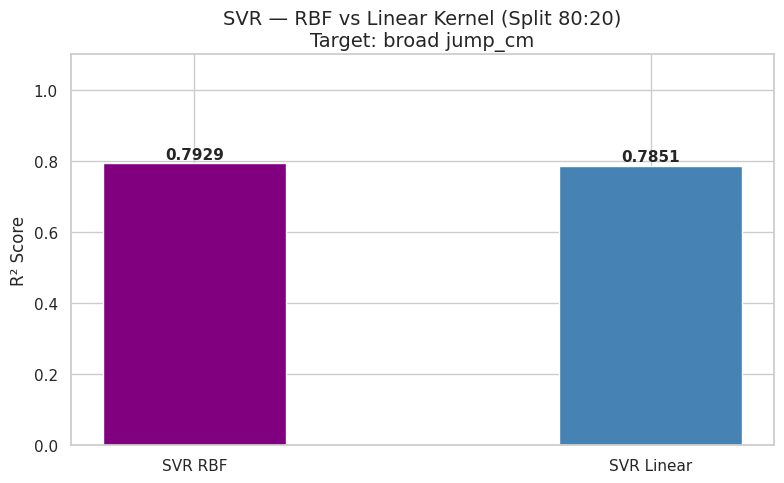

SVR Kernel Comparison:
RBF kernel    - test R²: 0.7929   (C = 10 )
Linear kernel - test R²: 0.7851   (C = 1 )
RBF kernel is better for this dataset


In [136]:
# ============================================================
#  SVR — Train Linear Kernel + Compare with RBF (80:20)
# ============================================================

svr_lin_model = SVR(kernel='linear', C=best_C_lin)
svr_lin_model.fit(X_reg_train_sc, y_reg_train)

y_pred_svr_lin = svr_lin_model.predict(X_reg_test_sc)
r2_lin  = round(r2_score(y_reg_test, y_pred_svr_lin), 4)
mae_lin = round(mean_absolute_error(y_reg_test, y_pred_svr_lin), 2)
rmse_lin = round(mean_squared_error(y_reg_test, y_pred_svr_lin) ** 0.5, 2)

print('SVR Linear Kernel Results (C =', best_C_lin, ')')
print('R2 score:', r2_lin)
print('MAE (cm):', mae_lin)
print('RMSE (cm):', rmse_lin)
print('')

# ── Compare RBF vs Linear ─────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))

kernels   = ['SVR RBF', 'SVR Linear']
test_r2s  = [svr_r2_8020, r2_lin]
colors    = ['purple', 'steelblue']

bars = ax.bar(kernels, test_r2s, color=colors, edgecolor='white', width=0.4)

for bar, v in zip(bars, test_r2s):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.005,
            str(v), ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_ylabel('R² Score')
ax.set_ylim(0, 1.1)
ax.set_title('SVR — RBF vs Linear Kernel (Split 80:20)\nTarget: broad jump_cm')
plt.tight_layout()
plt.show()

print('SVR Kernel Comparison:')
print('RBF kernel    - test R²:', svr_r2_8020, '  (C =', svr_C_8020, ')')
print('Linear kernel - test R²:', r2_lin,      '  (C =', best_C_lin, ')')

if svr_r2_8020 >= r2_lin:
    print('RBF kernel is better for this dataset')
else:
    print('Linear kernel is better for this dataset')

svr_lin_r2_8020 = r2_lin
svr_lin_C_8020  = best_C_lin

Summary

In [137]:
# ============================================================
#  SVR — Summary (RBF vs Linear Kernel) — Split 80:20
# ============================================================

svr_summary = pd.DataFrame({
    'Kernel':       ['RBF', 'Linear'],
    'Best C':       [svr_C_8020,  svr_lin_C_8020],
    'R² Score':     [svr_r2_8020, svr_lin_r2_8020],
})

print('SVR Regression — Results Summary')
print('Kernels tested : RBF  |  Linear')
print('Target         : broad jump_cm')
print()
display(svr_summary)

if svr_r2_8020 > svr_lin_r2_8020:
    print('Conclusion: RBF kernel is better for this dataset')
else:
    print('Conclusion: Linear kernel is better for this dataset')

SVR Regression — Results Summary
Kernels tested : RBF  |  Linear
Target         : broad jump_cm



,Kernel,Best C,R² Score
0,RBF,10,0.7929
1,Linear,1,0.7851


Conclusion: RBF kernel is better for this dataset


# NN Regression

 Import

In [138]:
# import neural network regressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print('Neural Network Regressor imported')

Neural Network Regressor imported


Architecture Tuning (80:20)

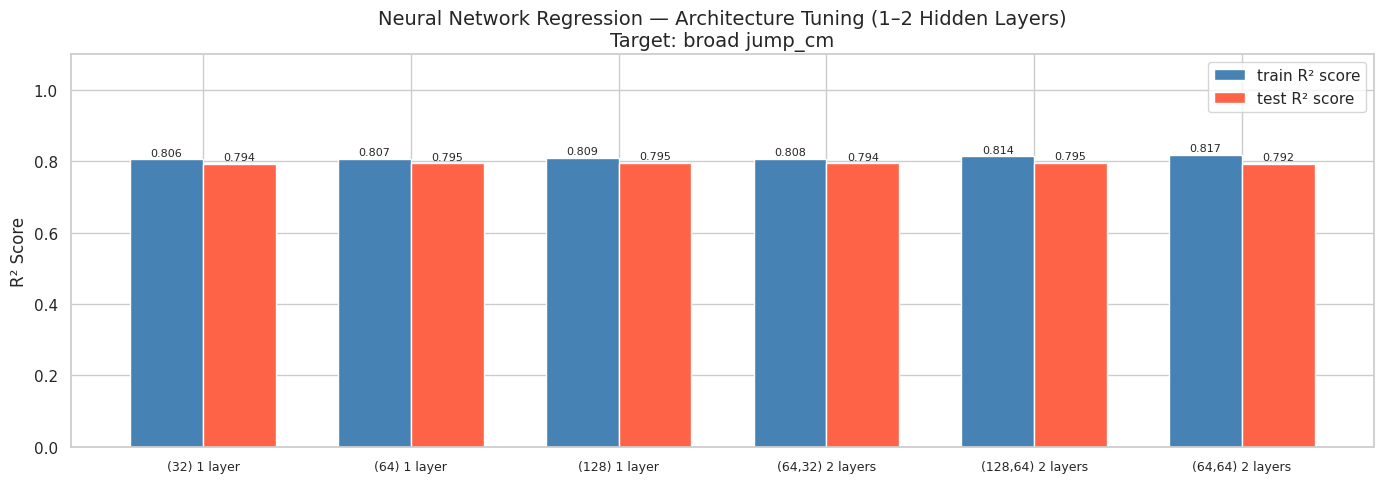

best architecture: (128,)
number of hidden layers: 1
test R² score: 0.7952


In [139]:
# ============================================================
#  Neural Network Regression — Split 80:20
#  Try different architectures (1 or 2 hidden layers)
#  Target: broad jump_cm
# ============================================================

# list of architectures to try
architectures = [
    (32,),       # 1 hidden layer with 32 neurons
    (64,),       # 1 hidden layer with 64 neurons
    (128,),      # 1 hidden layer with 128 neurons
    (64, 32),    # 2 hidden layers
    (128, 64),   # 2 hidden layers
    (64, 64),    # 2 hidden layers
]

arch_labels = ['(32) 1 layer', '(64) 1 layer', '(128) 1 layer',
               '(64,32) 2 layers', '(128,64) 2 layers', '(64,64) 2 layers']

nn_train_r2 = []
nn_test_r2  = []

for arch in architectures:
    mlp = MLPRegressor(hidden_layer_sizes=arch, activation='relu',
                       solver='adam', alpha=0.001,
                       max_iter=500, random_state=RANDOM_STATE)
    mlp.fit(X_reg_train_sc, y_reg_train)
    nn_train_r2.append(r2_score(y_reg_train, mlp.predict(X_reg_train_sc)))
    nn_test_r2.append(r2_score(y_reg_test,   mlp.predict(X_reg_test_sc)))

# find the best architecture (highest R² on test)
best_arch_idx = nn_test_r2.index(max(nn_test_r2))
best_arch     = architectures[best_arch_idx]

# plot results
x     = range(len(architectures))
width = 0.35
fig, ax = plt.subplots(figsize=(14, 5))

bars1 = ax.bar([i - width/2 for i in x], nn_train_r2,
               width, label='train R² score', color='steelblue', edgecolor='white')
bars2 = ax.bar([i + width/2 for i in x], nn_test_r2,
               width, label='test R² score',  color='tomato',    edgecolor='white')

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.005,
            str(round(h, 3)), ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(arch_labels, fontsize=9)
ax.set_ylabel('R² Score')
ax.set_ylim(0, 1.1)
ax.set_title('Neural Network Regression — Architecture Tuning (1–2 Hidden Layers)\nTarget: broad jump_cm')
ax.legend()
plt.tight_layout()
plt.show()

print('best architecture:', best_arch)
print('number of hidden layers:', len(best_arch))
print('test R² score:', round(max(nn_test_r2), 4))

Train Best Model (80:20)

In [140]:
# ============================================================
#  Neural Network Regression — Train Best Model (80:20)
# ============================================================

nn_reg_model = MLPRegressor(
    hidden_layer_sizes=best_arch,
    activation='relu',
    solver='adam',
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=1000,
    early_stopping=True,       # stop early if no improvement
    validation_fraction=0.1,
    n_iter_no_change=20,
    random_state=RANDOM_STATE
)

nn_reg_model.fit(X_reg_train_sc, y_reg_train)

# predictions
y_nn_pred_train = nn_reg_model.predict(X_reg_train_sc)
y_nn_pred_test  = nn_reg_model.predict(X_reg_test_sc)

# metrics
r2_train   = r2_score(y_reg_train,  y_nn_pred_train)
r2_test    = r2_score(y_reg_test,   y_nn_pred_test)
mae_train  = mean_absolute_error(y_reg_train, y_nn_pred_train)
mae_test   = mean_absolute_error(y_reg_test,  y_nn_pred_test)
mse_train  = mean_squared_error(y_reg_train,  y_nn_pred_train)
mse_test   = mean_squared_error(y_reg_test,   y_nn_pred_test)
rmse_train = mse_train ** 0.5
rmse_test  = mse_test  ** 0.5

print('Neural Network Regression Results (80:20)')
print('architecture:', best_arch, '(' + str(len(best_arch)) + ' hidden layers)')
print('training epochs:', nn_reg_model.n_iter_)
print('final loss:', round(nn_reg_model.loss_, 4))
print('')
print('metric           train        test')
print('R2 score:       ', round(r2_train, 4), '      ', round(r2_test, 4))
print('MAE (cm):       ', round(mae_train, 2), '      ', round(mae_test, 2))
print('MSE (cm2):      ', round(mse_train, 2), '     ', round(mse_test, 2))
print('RMSE (cm):      ', round(rmse_train, 2), '      ', round(rmse_test, 2))
print('')

if r2_test >= 0.75:
    print('verdict: good fit')
elif r2_test >= 0.50:
    print('verdict: moderate fit')
else:
    print('verdict: weak fit, maybe add more features')

# save results for summary
nn_reg_r2_8020   = round(r2_test, 4)
nn_reg_arch_8020 = best_arch

Neural Network Regression Results (80:20)
architecture: (128,) (1 hidden layers)
training epochs: 184
final loss: 154.028

metric           train        test
R2 score:        0.8032        0.7926
MAE (cm):        13.42        13.65
MSE (cm2):       310.58       312.74
RMSE (cm):       17.62        17.68

verdict: good fit


Plots (80:20)

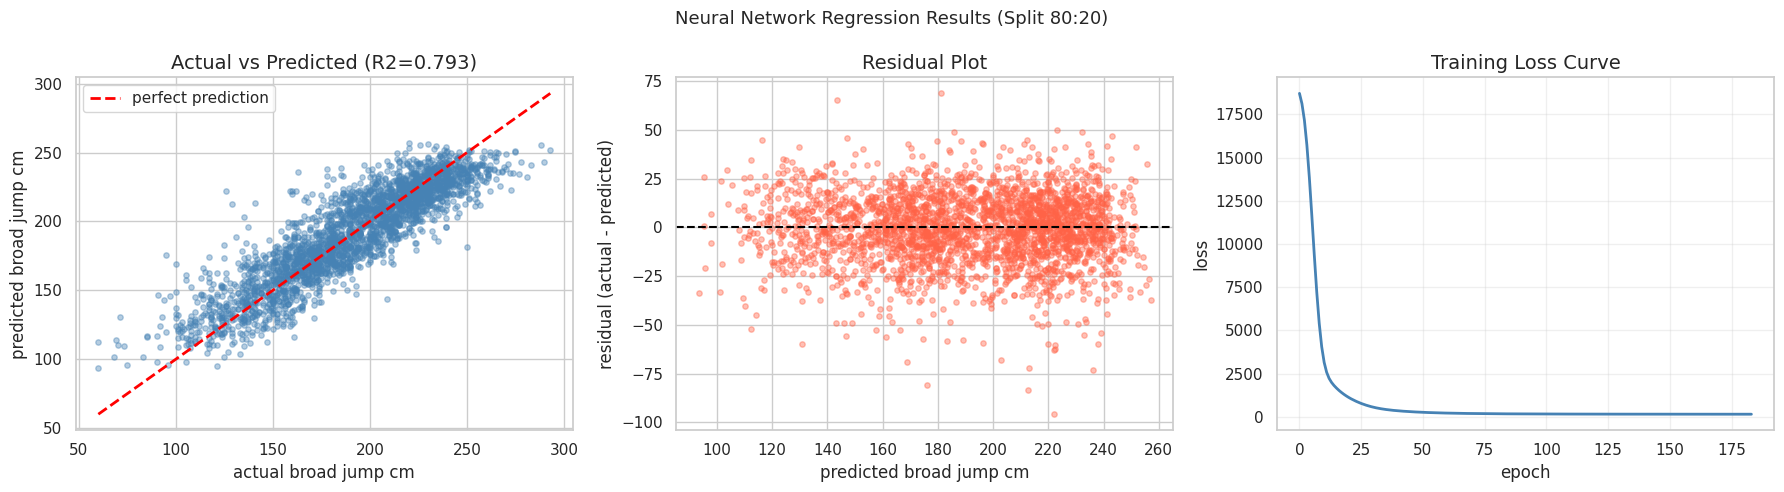

In [141]:
# ============================================================
#  Neural Network Regression — Plots (80:20)
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ── 1. Actual vs Predicted ────────────────────────────────
axes[0].scatter(y_reg_test, y_nn_pred_test, alpha=0.4, color='steelblue', s=15)
min_val = min(y_reg_test.min(), y_nn_pred_test.min())
max_val = max(y_reg_test.max(), y_nn_pred_test.max())
axes[0].plot([min_val, max_val], [min_val, max_val],
             color='red', linewidth=2, linestyle='--', label='perfect prediction')
axes[0].set_xlabel('actual broad jump cm')
axes[0].set_ylabel('predicted broad jump cm')
axes[0].set_title('Actual vs Predicted (R2=' + str(round(r2_test, 3)) + ')')
axes[0].legend()

# ── 2. Residual Plot ──────────────────────────────────────
residuals = y_reg_test - y_nn_pred_test
axes[1].scatter(y_nn_pred_test, residuals, alpha=0.4, color='tomato', s=15)
axes[1].axhline(y=0, color='black', linewidth=1.5, linestyle='--')
axes[1].set_xlabel('predicted broad jump cm')
axes[1].set_ylabel('residual (actual - predicted)')
axes[1].set_title('Residual Plot')

# ── 3. Training Loss Curve ────────────────────────────────
axes[2].plot(nn_reg_model.loss_curve_, color='steelblue', linewidth=2)
axes[2].set_xlabel('epoch')
axes[2].set_ylabel('loss')
axes[2].set_title('Training Loss Curve')
axes[2].grid(True, alpha=0.3)

plt.suptitle('Neural Network Regression Results (Split 80:20)', fontsize=13)
plt.tight_layout()
plt.show()

KNN Regression

=== KNN Regression Results ===
MSE: 371.77
RMSE: 19.28 cm
R2 Score: 0.75


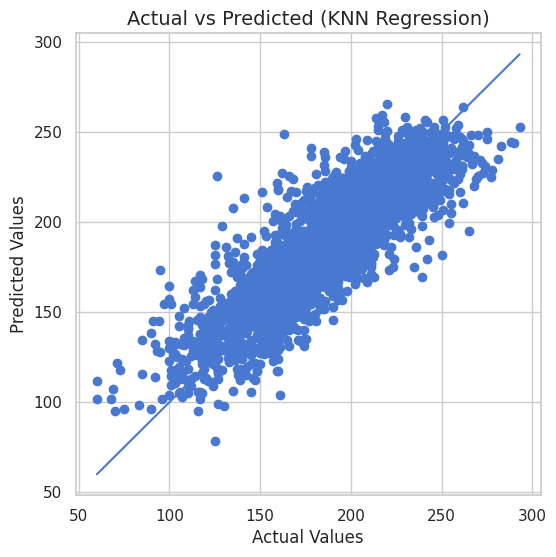

In [142]:
# ============================================
# KNN Regression Model + Visualization
# ============================================

# 1. Import required libraries


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score





# 3. Define target and features
y = df['broad jump_cm']
X = df.drop('broad jump_cm', axis=1)


# 4. One-Hot Encoding
X = pd.get_dummies(X, columns=['gender', 'class'], drop_first=True)


# 5. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.2, random_state=42
)


# 6. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# 7. Build model
knn_model = KNeighborsRegressor(n_neighbors=5)


# 8. Train model
knn_model.fit(X_train_scaled, y_train)


# 9. Predictions
y_pred = knn_model.predict(X_test_scaled)


# 10. Evaluation
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("=== KNN Regression Results ===")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f} cm")
print(f"R2 Score: {r2:.2f}")


# ============================================
# 11. Visualization: Actual vs Predicted
# ============================================

plt.figure(figsize=(6, 6))

# Scatter plot
plt.scatter(y_test, y_pred)

# Perfect prediction line
plt.plot([y_test.min(), y_test.max()],
 [y_test.min(), y_test.max()])

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted (KNN Regression)")

plt.show()

In this section, we compared five regression models to predict broad jump distance using the Body Performance dataset containing 13,369 samples with an 80:20 train-test split. The models tested were Linear Regression, Decision Tree Regressor, SVR with RBF and Linear kernels, Neural Network, and KNN Regressor, all evaluated using R² Score, MAE, and RMSE. The results showed that SVR RBF (C=10) achieved the highest R² score of 0.7929, meaning it explained approximately 79.3% of the variance in broad jump distance with a MAE of 13.69 cm. Following SVR RBF, the Neural Network (128 hidden units) performed closely with an R² of 0.7926, while the Decision Tree and KNN models showed relatively weaker performance with R² values of 0.7545 and 0.75 respectively. When comparing the best regression model (SVR RBF) with the best classification model (Neural Network, K-Fold accuracy = 70.23%), we observed that both tasks rely on the same features but differ fundamentally in their output, as regression predicts a continuous numeric value while classification assigns a categorical label. Based on these findings, SVR RBF is recommended for predicting jump distance, and the Neural Network is recommended for classifying fitness levels into classes A, B, C, and D.